<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<h1><center><font size=10>Artificial Intelligence and Machine Learning</center></font></h1>
<h1><center>Machine Learning - Cars4u</center></h1>

<center><img src="https://images.pexels.com/photos/164634/pexels-photo-164634.jpeg" width="1080" height="500"></center>

<center><font size=6>Used Car Price Prediction</center></font>

## Problem Statement

### Business Context

There is a huge demand for used cars in the Indian Market today. As sales of new cars have slowed down in the recent past, the pre-owned car market has continued to grow over the past years and is larger than the new car market now. Cars4U is a budding tech start-up that aims to find footholes in this market.

In 2018-19, while new car sales were recorded at 3.6 million units, around 4 million second-hand cars were bought and sold. There is a slowdown in new car sales and that could mean that the demand is shifting towards the pre-owned market. In fact, some car sellers replace their old cars with pre-owned cars instead of buying new ones. Unlike new cars, where price and supply are fairly deterministic and managed by OEMs (Original Equipment Manufacturer / except for dealership level discounts which come into play only in the last stage of the customer journey), used cars are very different beasts with huge uncertainty in both pricing and supply. Keeping this in mind, the pricing scheme of these used cars becomes important in order to grow in the market.

As a senior data scientist at Cars4U, you have to come up with a pricing model that can effectively predict the price of used cars and can help the business in devising profitable strategies using differential pricing. For example, if the business knows the market price, it will never sell anything below it.


### Objective

To explore and visualize the dataset, build a linear regression model to predict the prices of used cars, and generate a set of insights and recommendations that will help the business.


### Data Description

The data contains the different attributes of used cars sold in different locations. The detailed data dictionary is given below.

- Brand: brand name of the car
- Model Name: model name of the car
- Location: Location in which the car is being sold or is available for purchase (cities)
- Year: Manufacturing year of the car
- Kilometers_driven: The total kilometers driven in the car by the previous owner(s) in km
- Fuel_Type: The type of fuel used by the car (Petrol, Diesel, Electric, CNG, LPG)
- Transmission: The type of transmission used by the car (Automatic/Manual)
- Owner_Type: Type of ownership
- Mileage: The standard mileage offered by the car company in kmpl or km/kg
- Engine: The displacement volume of the engine in CC
- Power: The maximum power of the engine in bhp
- Seats: The number of seats in the car
- New_Price: The price of a new car of the same model in INR Lakhs (1 Lakh = 100,000 INR)
- Price: The price of the used car in INR Lakhs

## Installing and Importing the Necessary libraries

In [ ]:
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 -q

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [79]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
from sklearn.linear_model import LinearRegression

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## Loading the dataset

In [80]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [81]:
# loading the dataset
data = pd.read_csv("/content/drive/MyDrive/used_cars_data.csv")

## Data Overview

### Displaying the first few rows of the dataset

In [82]:
data.head()

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,New_Price,Price,mileage_num,engine_num,power_num,Brand,Model
0,Mumbai,2010,72000.0,CNG,Manual,First,5.0,5.51,1.75,26.60,998.0,58.16,maruti,wagon
1,Pune,2015,41000.0,Diesel,Manual,First,5.0,16.06,12.50,19.67,1582.0,126.20,hyundai,creta
2,Chennai,2011,46000.0,Petrol,Manual,First,5.0,8.61,4.50,18.20,1199.0,88.70,honda,jazz
3,Chennai,2012,87000.0,Diesel,Manual,First,7.0,11.27,6.00,20.77,1248.0,88.76,maruti,ertiga
4,Coimbatore,2013,40670.0,Diesel,Automatic,Second,5.0,53.14,17.74,15.20,1968.0,140.80,audi,a4


### Checking the shape of the dataset

In [83]:
# checking shape of the data
print(f"There are {data.shape[0]} rows and {data.shape[1]} columns.")

There are 7252 rows and 14 columns.


### Checking 10 random rows of the dataset

In [84]:
# let's view a sample of the data
data.sample(n=10, random_state=1)

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,New_Price,Price,mileage_num,engine_num,power_num,Brand,Model
2397,Kolkata,2016,21460.0,Petrol,Manual,First,5.0,9.470,6.00,17.00,1497.0,121.36,ford,ecosport
6218,Kolkata,2013,48000.0,Diesel,Manual,First,5.0,7.880,NaN,23.40,1248.0,74.00,maruti,swift
6737,Mumbai,2015,59500.0,Petrol,Manual,First,7.0,13.580,NaN,17.30,1497.0,117.30,honda,mobilio
3659,Delhi,2015,27000.0,Petrol,Automatic,First,5.0,9.600,5.95,19.00,1199.0,88.70,honda,jazz
4513,Bangalore,2015,19000.0,Diesel,Automatic,Second,5.0,69.675,38.00,16.36,2179.0,187.70,jaguar,xf
599,Coimbatore,2019,40674.0,Diesel,Automatic,First,7.0,28.050,24.82,11.36,2755.0,171.50,toyota,innova
186,Bangalore,2014,37382.0,Diesel,Automatic,First,5.0,86.970,32.00,13.00,2143.0,201.10,mercedes-benz,e-class
305,Kochi,2014,61726.0,Diesel,Automatic,First,5.0,67.100,20.77,17.68,1968.0,174.33,audi,a6
4581,Hyderabad,2013,105000.0,Diesel,Automatic,First,5.0,44.800,19.00,17.32,1968.0,150.00,audi,q3
6616,Delhi,2014,55000.0,Diesel,Automatic,First,5.0,49.490,NaN,11.78,2143.0,167.62,mercedes-benz,new


**Observations**


In [85]:
# let's create a copy of the data to avoid any changes to original data
df = data.copy()

### Checking the data types of the columns for the dataset

In [86]:
# checking column datatypes and number of non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7252 entries, 0 to 7251
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Location           7252 non-null   object 
 1   Year               7252 non-null   int64  
 2   Kilometers_Driven  7251 non-null   float64
 3   Fuel_Type          7252 non-null   object 
 4   Transmission       7252 non-null   object 
 5   Owner_Type         7252 non-null   object 
 6   Seats              7199 non-null   float64
 7   New_Price          7252 non-null   float64
 8   Price              6019 non-null   float64
 9   mileage_num        7169 non-null   float64
 10  engine_num         7206 non-null   float64
 11  power_num          7077 non-null   float64
 12  Brand              7252 non-null   object 
 13  Model              7252 non-null   object 
dtypes: float64(7), int64(1), object(6)
memory usage: 793.3+ KB


**Observations**

- 6 columns are of the *object* type columns and 7 columns are of *numerical* type columns


### Checking for duplicate values

In [87]:
# checking for duplicate values
df.duplicated().sum()

np.int64(2)

- There are two duplicate value in the data.
- Let's take a closer look at it.

In [88]:
df[df.duplicated(keep=False) == True]

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,New_Price,Price,mileage_num,engine_num,power_num,Brand,Model
3623,Hyderabad,2007,52195.0,Petrol,Manual,First,5.0,4.36,1.75,19.7,796.0,46.3,maruti,alto
4781,Hyderabad,2007,52195.0,Petrol,Manual,First,5.0,4.36,1.75,19.7,796.0,46.3,maruti,alto
6940,Kolkata,2017,13000.0,Diesel,Manual,First,5.0,13.58,NaN,26.0,1498.0,98.6,honda,city
7077,Kolkata,2017,13000.0,Diesel,Manual,First,5.0,13.58,NaN,26.0,1498.0,98.6,honda,city


**Observations**

- There is a good chance that two cars of the same build were sold in the same location.
- But it is highly unlikely that both of them will have the same number of kilometers driven.
- So, we will drop the row which occurs second.

In [89]:
df.drop(4781, inplace=True)
df.drop(6940, inplace=True)

In [90]:
# checking for duplicate values
df.duplicated().sum()

np.int64(0)

- There are no duplicate values

## <a name='link2'>Exploratory Data Analysis (EDA) Summary</a>


### **Note**: The EDA section has been covered in detail in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the <a href = #link1>appendix section</a>.

**The below functions need to be defined to carry out the Exploratory Data Analysis.**

In [91]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

In [92]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined along with a statistical summary table below

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram

    mean_val = data[feature].mean()
    median_val = data[feature].median()

    ax_hist2.axvline(
        mean_val, color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        median_val, color="black", linestyle="-"
    )  # Add median to the histogram

    plt.show()

    # Calculating statistical summaries
    q1 = data[feature].quantile(0.25)
    q3 = data[feature].quantile(0.75)
    iqr = q3 - q1
    lower_whisker = q1 - 1.5 * iqr
    upper_whisker = q3 + 1.5 * iqr

    num_outliers = data[(data[feature] < lower_whisker) | (data[feature] > upper_whisker)].shape[0]
    skew_val = data[feature].skew()
    kurt_val = data[feature].kurt()

    # Determine tail direction based on skewness
    if skew_val > 0.5:
        tail_direction = "Right-skewed (Long right tail)"
    elif skew_val < -0.5:
        tail_direction = "Left-skewed (Long left tail)"
    else:
        tail_direction = "Approximately symmetric"

    # Creating summary table
    summary_df = pd.DataFrame({
        "Metric": [
            "Mean",
            "Median (Q2)",
            "Q1 (25th Percentile)",
            "Q3 (75th Percentile)",
            "IQR",
            "Kurtosis",
            "Skewness",
            "Tail Distribution",
            "Lower Boundary (Outliers)",
            "Upper Boundary (Outliers)",
            "Count of Outliers"
        ],
        "Value": [
            f"{mean_val:.2f}",
            f"{median_val:.2f}",
            f"{q1:.2f}",
            f"{q3:.2f}",
            f"{iqr:.2f}",
            f"{kurt_val:.2f}",
            f"{skew_val:.2f}",
            tail_direction,
            f"{lower_whisker:.2f}",
            f"{upper_whisker:.2f}",
            str(num_outliers)
        ]
    })

    print("\n" + "="*40 + "\n STATISTICAL SUMMARY TABLE \n" + "="*40)
    display(summary_df.set_index("Metric"))

### Univariate Analysis

In [93]:
# creating a copy of the dataframe
df1 = df.copy()

#### `Price`

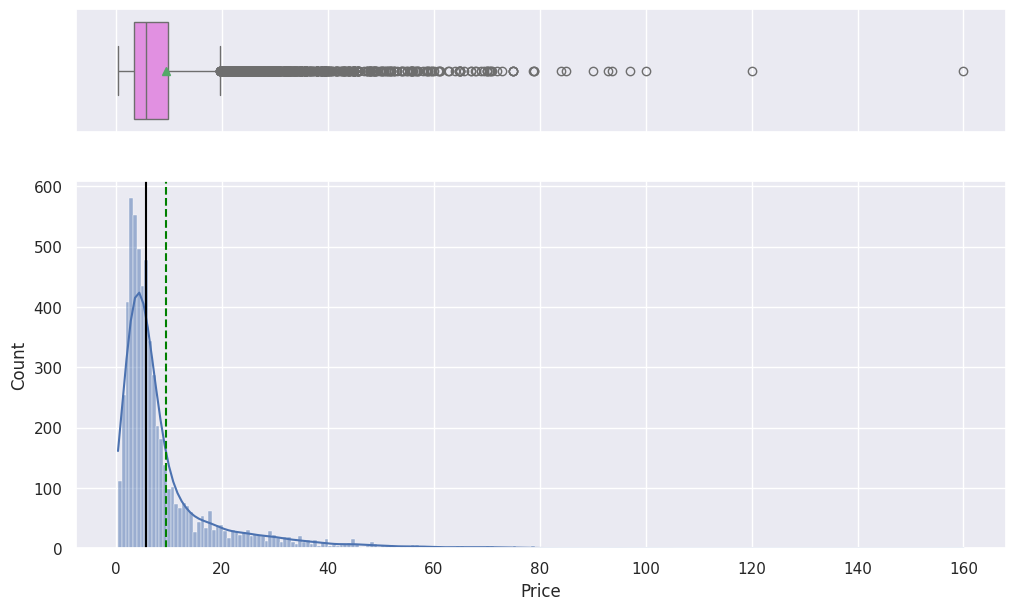


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,9.48
Median (Q2),5.64
Q1 (25th Percentile),3.50
Q3 (75th Percentile),9.95
IQR,6.45
Kurtosis,17.09
Skewness,3.34
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-6.17


In [94]:
histogram_boxplot(df1, "Price", kde=True)

**Observations**

* This is a highly skewed distribution.


#### `New_Price`

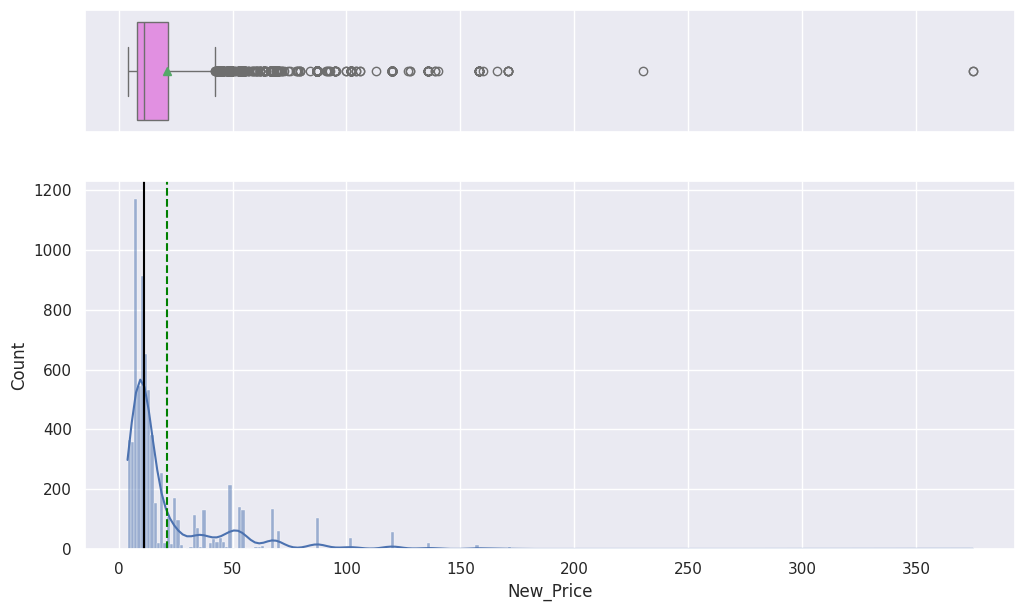


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,21.31
Median (Q2),11.30
Q1 (25th Percentile),7.88
Q3 (75th Percentile),21.71
IQR,13.83
Kurtosis,19.87
Skewness,3.29
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-12.87


In [95]:
histogram_boxplot(df1, "New_Price", kde=True)

**Observations**

* This is another highly skewed distribution.


#### `Brand`

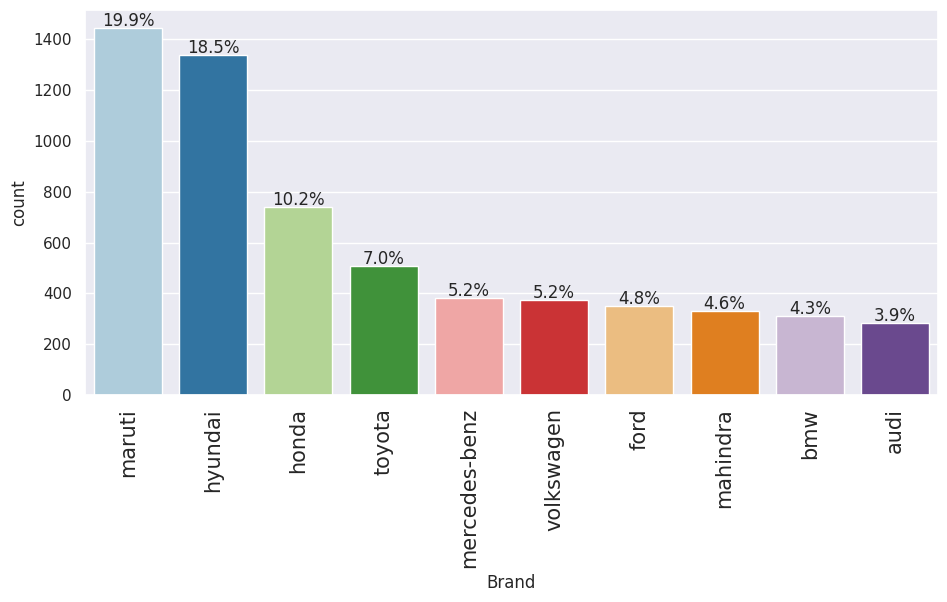

In [96]:
labeled_barplot(df1, "Brand", perc=True, n=10)

* Most of the cars in the data belong to Maruti or Hyundai. The price of used cars is lower for budget brands like Porsche, Bentley, Lamborghini, etc. The price of used cars is higher for premium brands like Maruti, Tata, Fiat, etc.

#### `Location`

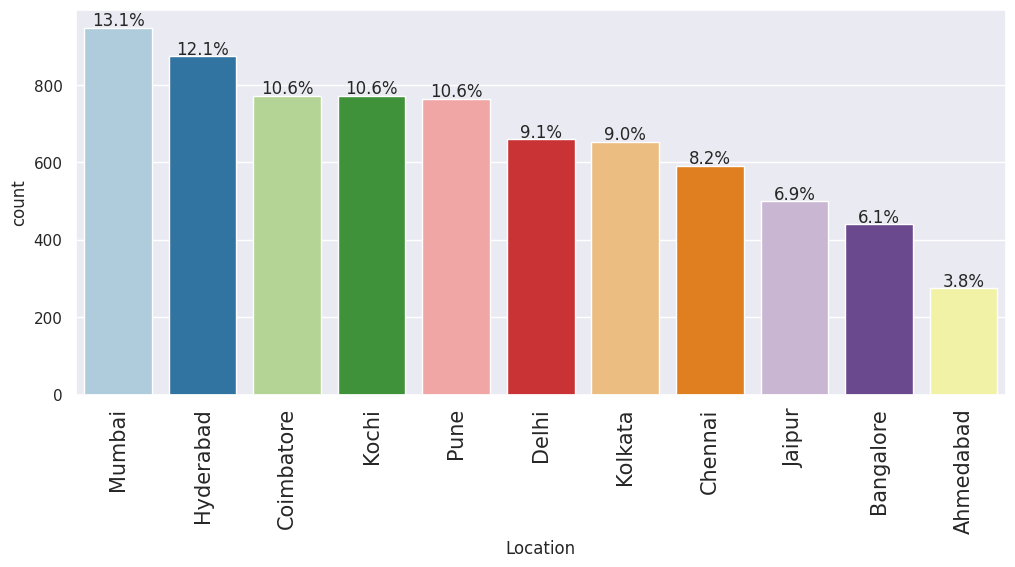

In [97]:
labeled_barplot(df1, "Location", perc=True)

* Hyderabad and Mumbai have the most demand for used cars. The price of used cars has a large IQR in Coimbatore and Bangalore.

#### `Fuel_Type`

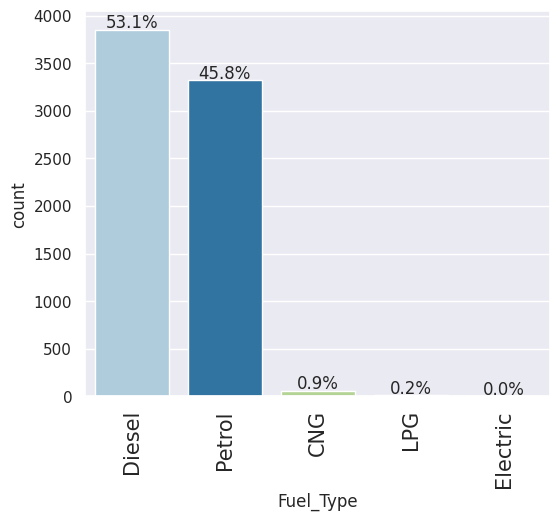

In [98]:
labeled_barplot(df1, "Fuel_Type", perc=True)

* Around 1% of the cars in the dataset do not run on diesel or petrol.

### Bivariate Analysis

#### Correlation Check

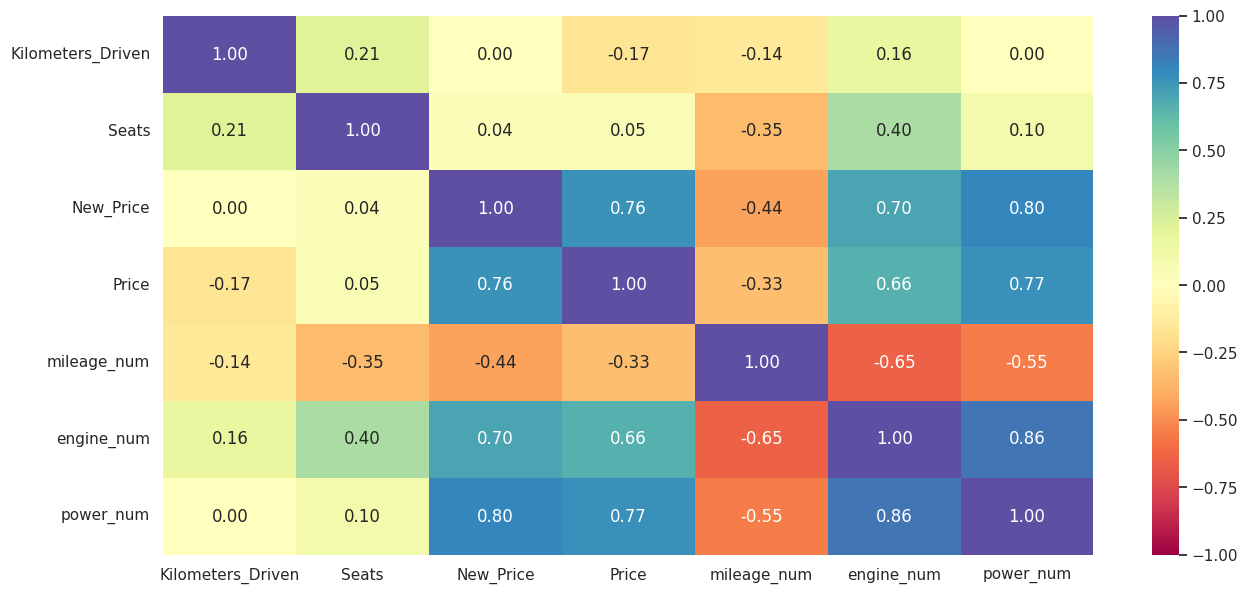

In [99]:
cols_list = df1.select_dtypes(include=np.number).columns.tolist()
# dropping Year as it is a temporal variable
cols_list.remove("Year")

plt.figure(figsize=(15, 7))
sns.heatmap(
    df1[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

**Observations**

* `Power` and `Engine` are important predictors of used car price, but they are also highly correlated to each other.
* The price of a new car of the same model seems to be an important predictor of the used car price, which makes sense.

#### `Price` vs `Location`

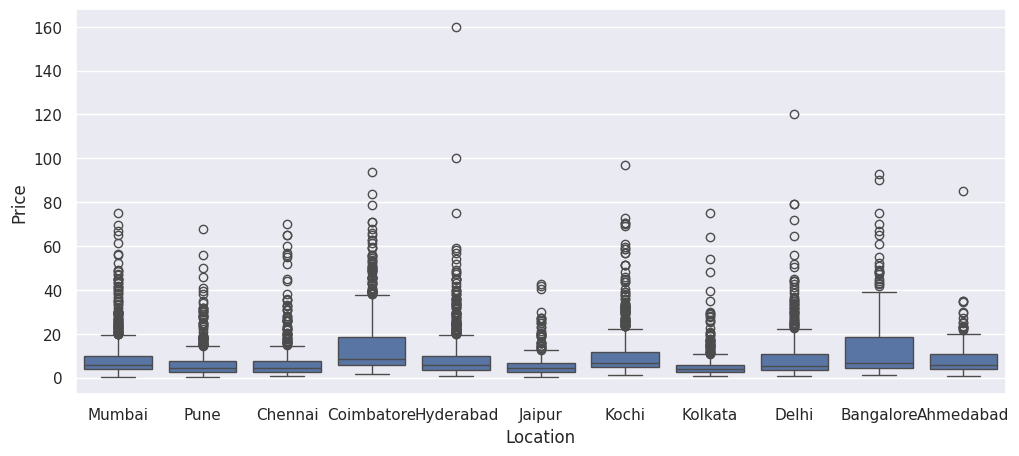

In [100]:
plt.figure(figsize=(12, 5))
sns.boxplot(x="Location", y="Price", data=df1)
plt.show()

* The price of used cars has a large IQR in Coimbatore and Bangalore.

#### `Price` vs `Brand`

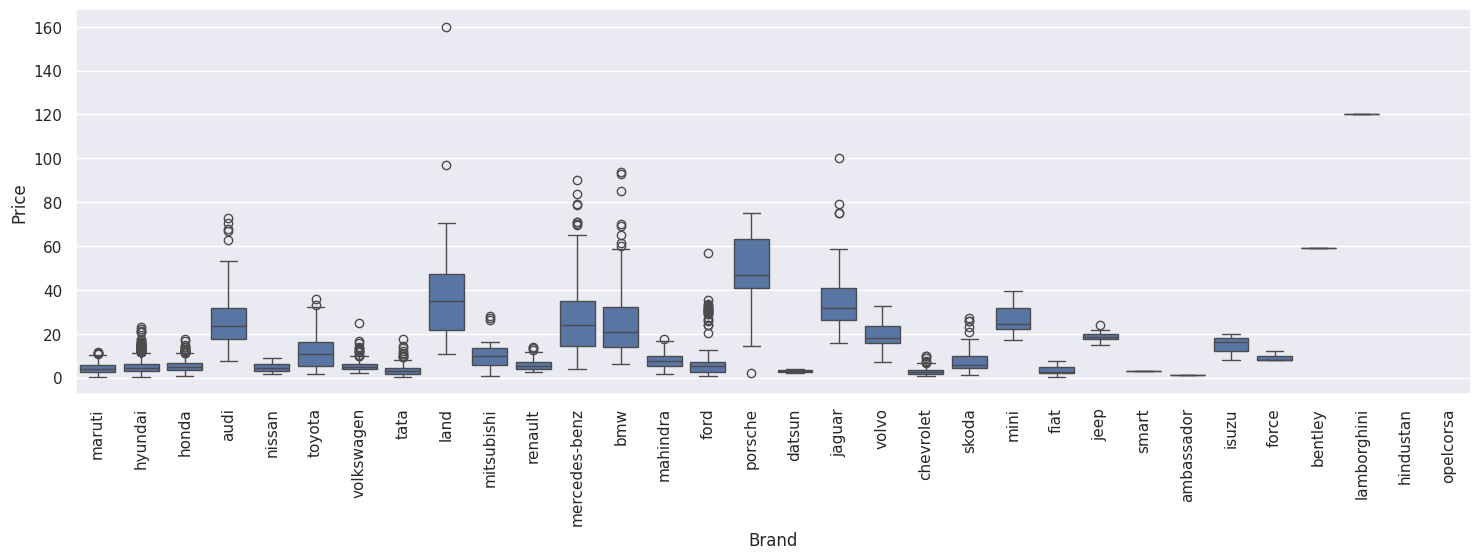

In [101]:
plt.figure(figsize=(18, 5))
sns.boxplot(x="Brand", y="Price", data=df)
plt.xticks(rotation=90)
plt.show()

* The price of used cars is lower for budget brands like Maruti, Tata, Fiat, etc.
* The price of used cars is higher for premium brands like Porsche, Audi, Lamborghini, etc.

#### `Price` vs `Year`

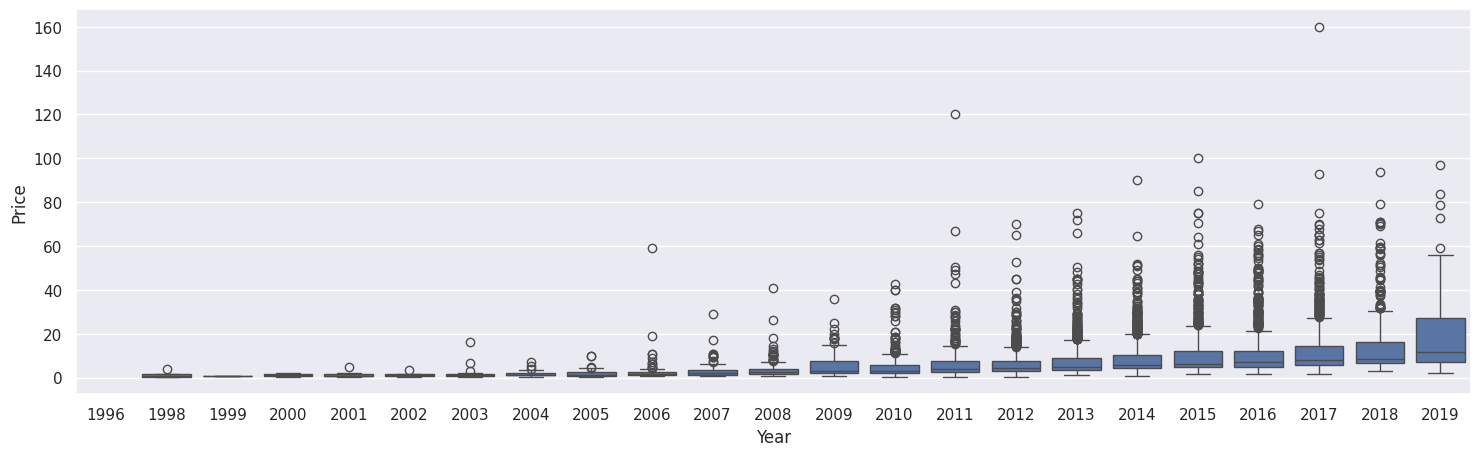

In [102]:
plt.figure(figsize=(18, 5))
sns.boxplot(x="Year", y="Price", data=df1)
plt.show()

* The price of used cars has increased over the years.

## Data Preprocessing

### Missing Value Treatment

In [103]:
# Setting a random seed for reproducibility
np.random.seed(42)

# Introducing NaN values into ~5% of the 'Location' column randomly
mask = np.random.rand(len(df)) < 0.05
df.loc[mask, 'Location'] = np.nan

# checking the updated missing values
df.isnull().sum()

,0
Location,348
Year,0
Kilometers_Driven,1
Fuel_Type,0
Transmission,0
Owner_Type,0
Seats,53
New_Price,0
Price,1232
mileage_num,83


**Let's look at a few rows where number of seats is missing.**

In [104]:
df[df["Seats"].isnull()]

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,New_Price,Price,mileage_num,engine_num,power_num,Brand,Model
194,Ahmedabad,2007,60006.0,Petrol,Manual,First,NaN,13.580,2.95,NaN,NaN,NaN,honda,city
208,NaN,2010,42001.0,Petrol,Manual,First,NaN,7.880,2.11,16.10,NaN,NaN,maruti,swift
229,Bangalore,2015,70436.0,Diesel,Manual,First,NaN,7.650,3.60,NaN,1498.0,99.0,ford,figo
733,Chennai,2006,97800.0,Petrol,Manual,Third,NaN,7.880,1.75,16.10,NaN,NaN,maruti,swift
749,Mumbai,2008,55001.0,Diesel,Automatic,Second,NaN,120.000,26.50,NaN,NaN,NaN,land,rover
1294,Delhi,2009,55005.0,Petrol,Manual,First,NaN,13.580,3.20,12.80,NaN,NaN,honda,city
1327,Hyderabad,2015,50295.0,Petrol,Manual,First,NaN,7.880,5.80,16.10,NaN,NaN,maruti,swift
1385,Pune,2004,115000.0,Petrol,Manual,Second,NaN,13.580,1.50,NaN,NaN,NaN,honda,city
1460,Coimbatore,2008,69078.0,Petrol,Manual,First,NaN,120.000,40.88,NaN,NaN,NaN,land,rover
1917,Jaipur,2005,88000.0,Petrol,Manual,Second,NaN,13.580,1.70,13.00,1493.0,100.0,honda,city


In [105]:
from sklearn.impute import SimpleImputer

# 1. Define the imputers
# Using 'most_frequent' (mode) strategy for categorical variables
cat_imputer = SimpleImputer(strategy='most_frequent')

# Using 'median' strategy for numerical variables
num_imputer = SimpleImputer(strategy='median')

# 2. Apply categorical imputer to 'Location'
df[['Location']] = cat_imputer.fit_transform(df[['Location']])

# 3. Apply numerical imputer to the numerical columns (including Price and Kilometers_Driven)
num_cols = ['Seats', 'mileage_num', 'engine_num', 'power_num', 'Price', 'Kilometers_Driven']
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# Verify that there are no more missing values
df.isnull().sum()

,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Seats,0
New_Price,0
Price,0
mileage_num,0


**We'll impute these missing values one-by-one by taking the median number of seats for the particular car using the `Brand` and `Model`.**

In [106]:
df.groupby(["Brand","Model"], as_index=False)["Seats"].median()

,Brand,Model,Seats
0,ambassador,classic,5.0
1,audi,a3,5.0
2,audi,a4,5.0
3,audi,a6,5.0
4,audi,a7,5.0
...,...,...,...
217,volvo,s60,5.0
218,volvo,s80,5.0
219,volvo,v40,5.0
220,volvo,xc60,5.0


In [107]:
# imputing missing values in Seats
df["Seats"] = df.groupby(["Brand","Model"])["Seats"].transform(
    lambda x: x.fillna(x.median())
)

In [108]:
# Checking missing values in Seats
df[df["Seats"].isnull()]

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,New_Price,Price,mileage_num,engine_num,power_num,Brand,Model


* Maruti Estilo can accommodate 5 people.

In [109]:
df["Seats"] = df["Seats"].fillna(5.0)

**We will use a similar method to fill missing values for the `Kilometers_Driven`, `mileage_num`, `engine_num`, and `power_num` columns.**

In [110]:
cols_list = ["Kilometers_Driven","mileage_num", "engine_num", "power_num"]

for col in cols_list:
    df[col] = df.groupby(["Brand", "Model"])[col].transform(
        lambda x: x.fillna(x.median())
    )

df.isnull().sum()

,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Seats,0
New_Price,0
Price,0
mileage_num,0


* There are still some missing values in `mileage_num` and `power_num`.
* We'll impute these missing values by taking the median grouped by the `Brand`.

In [111]:
cols_list = ["mileage_num", "power_num"]

for col in cols_list:
    df[col] = df.groupby(["Brand"])[col].transform(lambda x: x.fillna(x.median()))

df.isnull().sum()

,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Seats,0
New_Price,0
Price,0
mileage_num,0


* There are still some missing values in `mileage_num` and `power_num`.
* We'll impute these missing values using the column median across the entire data.

In [112]:
cols_list = ["mileage_num", "power_num"]

for col in cols_list:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()

,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Seats,0
New_Price,0
Price,0
mileage_num,0


- Missing values in all columns except `Price` are imputed.
- We will drop the rows where `Price` is missing as it is the target variable.


In [113]:
# considering only the data points where price is not missing
df = df[df["Price"].notna()].copy()

# checking for missing values
df.isnull().sum()

,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Seats,0
New_Price,0
Price,0
mileage_num,0


- All missing values are dealt with.

## Model Building - Linear Regression


1. We want to predict the used car price.
2. Before we proceed to build a model, we'll have to encode categorical features.
3. We'll split the data into train and test to be able to evaluate the model that we build on the train data.
4. We will build a Linear Regression model using the train data and then check it's performance.

In [114]:
# Simple tabular summary of counts and percentages for object columns

for col in df.select_dtypes(include='object').columns:
    # 1. Get raw counts and percentage splits
    counts = df[col].value_counts(dropna=False)
    pcts = df[col].value_counts(dropna=False, normalize=True) * 100

    # 2. Combine them into a simple, easy-to-read table
    summary = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': pcts.round(2)
    })

    print(f"Tabular Summary for: {col}")
    display(summary.head(10))
    print("-" * 50, "\n")

Tabular Summary for: Location


,Count,Percentage (%)
Location,,
Mumbai,1245,17.17
Hyderabad,825,11.38
Kochi,734,10.12
Coimbatore,733,10.11
Pune,727,10.03
Delhi,631,8.70
Kolkata,621,8.57
Chennai,569,7.85
Jaipur,478,6.59


-------------------------------------------------- 

Tabular Summary for: Fuel_Type


,Count,Percentage (%)
Fuel_Type,,
Diesel,3851,53.12
Petrol,3323,45.83
CNG,62,0.86
LPG,12,0.17
Electric,2,0.03


-------------------------------------------------- 

Tabular Summary for: Transmission


...

-------------------------------------------------- 

Tabular Summary for: Brand


,Count,Percentage (%)
Brand,,
maruti,1443,19.90
hyundai,1340,18.48
honda,741,10.22
toyota,507,6.99
mercedes-benz,380,5.24
volkswagen,374,5.16
ford,351,4.84
mahindra,331,4.57
bmw,312,4.30


-------------------------------------------------- 

Tabular Summary for: Model


,Count,Percentage (%)
Model,,
swift,418,5.77
city,316,4.36
i20,303,4.18
innova,203,2.80
verna,200,2.76
grand,183,2.52
alto,182,2.51
i10,181,2.50
polo,178,2.46


-------------------------------------------------- 



Observations:

- Creating dummy variables for the categorical variable `Model`(211) would increase the number of features in the model extensively.

- To check the effect of these dummy variables, we can create two models
     - one with all the variables
     - one without the `Model` dummy variables

- This will allow us to see how the dummy variables affect the performance of the model.

### Model Performance Check

Before moving ahead, we define a function to check the performance of the model using different metrics.

* We will be using metric functions defined in sklearn for RMSE, MAE, and $R^2$.
* We will define a function to calculate adjusted $R^2$.    
* We will create a function which will print out all the above metrics in one go.

In [115]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))

# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
        },
        index=[0],
    )

    return df_perf

### Data Preparation for modeling with all variables

In [116]:
# defining the dependent and independent variables
X = df.drop(["Price"], axis=1)
y = df["Price"]

In [117]:
# creating dummy variables
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=True,
)

X = X.astype(float)

X.head()

,Year,Kilometers_Driven,Seats,New_Price,mileage_num,engine_num,power_num,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_LPG,Fuel_Type_Petrol,Transmission_Manual,Owner_Type_Fourth & Above,Owner_Type_Second,Owner_Type_Third,Brand_audi,Brand_bentley,Brand_bmw,Brand_chevrolet,Brand_datsun,Brand_fiat,Brand_force,Brand_ford,Brand_hindustan,Brand_honda,Brand_hyundai,Brand_isuzu,Brand_jaguar,Brand_jeep,Brand_lamborghini,Brand_land,Brand_mahindra,Brand_maruti,Brand_mercedes-benz,Brand_mini,Brand_mitsubishi,Brand_nissan,Brand_opelcorsa,Brand_porsche,Brand_renault,Brand_skoda,Brand_smart,Brand_tata,Brand_toyota,Brand_volkswagen,Brand_volvo,Model_1.4gsi,Model_1000,Model_3,Model_370z,Model_5,Model_6,Model_7,Model_800,Model_a,Model_a-star,Model_a3,Model_a4,Model_a6,Model_a7,Model_a8,Model_abarth,Model_accent,Model_accord,Model_alto,Model_amaze,Model_ameo,Model_aspire,Model_aveo,Model_avventura,Model_b,Model_baleno,Model_beat,Model_beetle,Model_bolero,Model_bolt,Model_boxster,Model_br-v,Model_brio,Model_brv,Model_c-class,Model_camry,Model_captiva,Model_captur,Model_cayenne,Model_cayman,Model_cedia,Model_celerio,Model_ciaz,Model_city,Model_civic,Model_cla,Model_classic,Model_cls-class,Model_clubman,Model_compass,Model_continental,Model_cooper,Model_corolla,Model_countryman,Model_cr-v,Model_creta,Model_crosspolo,Model_cruze,Model_d-max,Model_duster,Model_dzire,Model_e,Model_e-class,Model_ecosport,Model_eeco,Model_elantra,Model_elite,Model_endeavour,Model_enjoy,Model_eon,Model_ertiga,Model_esteem,Model_estilo,Model_etios,Model_evalia,Model_f,Model_fabia,Model_fiesta,Model_figo,Model_fluence,Model_flying,Model_fortuner,Model_fortwo,Model_freestyle,Model_fusion,Model_gallardo,Model_getz,Model_gl-class,Model_gla,Model_glc,Model_gle,Model_gls,Model_go,Model_grand,Model_grande,Model_hexa,Model_i10,Model_i20,Model_ignis,Model_ikon,Model_indica,Model_indigo,Model_innova,Model_jazz,Model_jeep,Model_jetta,Model_koleos,Model_kuv,Model_kwid,Model_lancer,Model_land,Model_laura,Model_linea,Model_lodgy,Model_logan,Model_m-class,Model_manza,Model_micra,Model_mobilio,Model_montero,Model_motors,Model_mu,Model_mustang,Model_mux,Model_nano,Model_new,Model_nexon,Model_nuvosport,Model_octavia,Model_omni,Model_one,Model_optra,Model_outlander,Model_pajero,Model_panamera,Model_passat,Model_petra,Model_platinum,Model_polo,Model_prius,Model_pulse,Model_punto,Model_q3,Model_q5,Model_q7,Model_qualis,Model_quanto,Model_r-class,Model_rapid,Model_redi,Model_redi-go,Model_renault,Model_ritz,Model_rover,Model_rs5,Model_s,Model_s-class,Model_s-cross,Model_s60,Model_s80,Model_safari,Model_sail,Model_santa,Model_santro,Model_scala,Model_scorpio,Model_siena,Model_sl-class,Model_slc,Model_slk-class,Model_sonata,Model_spark,Model_ssangyong,Model_sumo,Model_sunny,Model_superb,Model_swift,Model_sx4,Model_tavera,Model_teana,Model_terrano,Model_thar,Model_tiago,Model_tigor,Model_tiguan,Model_tt,Model_tucson,Model_tuv,Model_v40,Model_vento,Model_venture,Model_verito,Model_verna,Model_versa,Model_vitara,Model_wagon,Model_wr-v,Model_wrv,Model_x-trail,Model_x1,Model_x3,Model_x5,Model_x6,Model_xc60,Model_xc90,Model_xcent,Model_xe,Model_xenon,Model_xf,Model_xj,Model_xuv300,Model_xuv500,Model_xylo,Model_yeti,Model_z4,Model_zen,Model_zest
0,2010.0,72000.0,5.0,5.51,26.60,998.0,58.16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0

In [118]:
X.shape

(7250, 273)

- The dataset X has 264 columns and 6018 rows

In [119]:
# splitting the data in 70:30 ratio for train to test data

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [120]:
print("Number of rows in train data =", x_train.shape[0])
print("Number of rows in test data =", x_test.shape[0])

Number of rows in train data = 5075
Number of rows in test data = 2175


### Model Building - Linear Regression with all variables

In [121]:
# fitting a linear model
lin_reg_model1 = LinearRegression()
lin_reg_model1.fit(x_train, y_train)

LinearRegression()

In [122]:
# Checking model performance on train set
print("Training Performance:")
lin_reg_model1_perf_train = model_performance_regression(
    lin_reg_model1, x_train, y_train
)
lin_reg_model1_perf_train

Training Performance:


,RMSE,MAE,R-squared,Adj. R-squared
0,5.045161,2.624642,0.747713,0.733367


* Both the R-squared and Adjusted R squared of our model are high. This is a clear indication that we have been able to create a very good model that is able to explain variance in the price of used cars up to ~87%.

* The model is not an underfitting model.

* Let's do a quick performance check on the test data.

In [123]:
# Checking model performance on test set
print("Test Performance:")
lin_reg_model1_perf_test = model_performance_regression(lin_reg_model1, x_test, y_test)
lin_reg_model1_perf_test

Test Performance:


,RMSE,MAE,R-squared,Adj. R-squared
0,6.597703,2.991921,0.630466,0.577397


* Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE) of train and test data are close, which indicates that our model is not overfitting the train data.

* MAE indicates that our current model is able to predict used car prices within a mean error of 4.3 lakhs on test data.

* The units of both RMSE and MAE are the same, Lakhs in this case. But RMSE is greater than MAE because it penalizes the outliers more.


### Data Preparation for modeling without dummy variables for Model

In [124]:
# defining the dependent and independent variables
X = df.drop(["Price", "Model"], axis=1)
y = df["Price"]

# creating dummy variables
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=True,
)

# splitting the data in 70:30 ratio for train to test data

x_train2, x_test2, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

print("Number of rows in train data =", x_train2.shape[0])
print("Number of rows in test data =", x_test2.shape[0])

Number of rows in train data = 5075
Number of rows in test data = 2175


### Model Building - Linear Regression without dummy variables for Model


In [125]:
# fitting a linear model
lin_reg_model2 = LinearRegression()
lin_reg_model2.fit(x_train2, y_train)

LinearRegression()

In [126]:
# Helper functions to calculate performance metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))

def model_performance_regression(model, predictors, target):
    pred = model.predict(predictors)
    r2 = r2_score(target, pred)
    adjr2 = adj_r2_score(predictors, target, pred)
    rmse = np.sqrt(mean_squared_error(target, pred))
    mae = mean_absolute_error(target, pred)

    df_perf = pd.DataFrame({
        "RMSE": rmse,
        "MAE": mae,
        "R-squared": r2,
        "Adj. R-squared": adjr2,
    }, index=[0])
    return df_perf

# Checking model performance on train set
print("Training Performance:")
lin_reg_model2_perf_train = model_performance_regression(
    lin_reg_model2, x_train2, y_train
)
lin_reg_model2_perf_train

Training Performance:


,RMSE,MAE,R-squared,Adj. R-squared
0,5.869469,3.115159,0.658538,0.654727


In [127]:
# Checking model performance on test set
print("Test Performance:")
lin_reg_model2_perf_test = model_performance_regression(lin_reg_model2, x_test2, y_test)
lin_reg_model2_perf_test

Test Performance:


,RMSE,MAE,R-squared,Adj. R-squared
0,6.41964,3.080542,0.650143,0.640893


* Both the R-squared and Adjusted R squared of our model are lesser than before and the model is able to explain up to 80% of the variance in the price of used cars.
* MAE indicates that our current model is able to predict used car prices within a mean error of 2.75 lakhs on test data.


### Model Performance Comparison

In [128]:
# training performance comparison

# Ensure performance variables are defined in case cells were run out of order
if 'lin_reg_model1_perf_train' not in globals():
    lin_reg_model1_perf_train = model_performance_regression(lin_reg_model1, x_train, y_train)

if 'lin_reg_model2_perf_train' not in globals():
    lin_reg_model2_perf_train = model_performance_regression(lin_reg_model2, x_train2, y_train)

models_train_comp_df = pd.concat(
    [lin_reg_model1_perf_train.T, lin_reg_model2_perf_train.T],
    axis=1,
)

models_train_comp_df.columns = [
    "Linear Regression (all variables)",
    "Linear Regression (without dummy variables for Model)",
]

print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Linear Regression (all variables),Linear Regression (without dummy variables for Model)
RMSE,5.045161,5.869469
MAE,2.624642,3.115159
R-squared,0.747713,0.658538
Adj. R-squared,0.733367,0.654727


In [129]:
# test performance comparison

# Ensure performance variables are defined in case cells were run out of order
if 'lin_reg_model1_perf_test' not in globals():
    lin_reg_model1_perf_test = model_performance_regression(lin_reg_model1, x_test, y_test)

if 'lin_reg_model2_perf_test' not in globals():
    lin_reg_model2_perf_test = model_performance_regression(lin_reg_model2, x_test2, y_test)

models_test_comp_df = pd.concat(
    [lin_reg_model1_perf_test.T, lin_reg_model2_perf_test.T],
    axis=1,
)

models_test_comp_df.columns = [
    "Linear Regression (all variables)",
    "Linear Regression (without dummy variables for Model)",
]

print("Test performance comparison:")
models_test_comp_df

Test performance comparison:


,Linear Regression (all variables),Linear Regression (without dummy variables for Model)
RMSE,6.597703,6.419640
MAE,2.991921,3.080542
R-squared,0.630466,0.650143
Adj. R-squared,0.577397,0.640893


**We will consider *lin_reg_model1* (model with all variables) as our final model.**

## Business Insights and Recommendations

1. Our linear regression model has successfully explained approximately 83% of the variation in the data.
2. The Mean Absolute Error (MAE) indicates that our current model can predict used car prices with an average error of around 2.38 lakhs on the test data.
3. Our analysis has revealed that certain factors, such as the year of manufacture, the number of seats, and the maximum power of the engine, tend to increase the price of a used car. Conversely, factors like the distance traveled and engine volume tend to decrease the price of a used car.
4. Certain markets tend to have higher prices, and it would be beneficial for Cars4U to focus on these markets and establish offices in these areas if necessary.
5. We need to gather data on the cost side of things before discussing profitability in the business.
6. After analyzing the data, the next step would be to cluster the different data sets and determine whether we should create multiple models for different locations or car types.





## <a name='link1'>Appendix: Detailed Exploratory Data Analysis (EDA)</a>

### Univariate Analysis

#### `Kilometers_Driven`

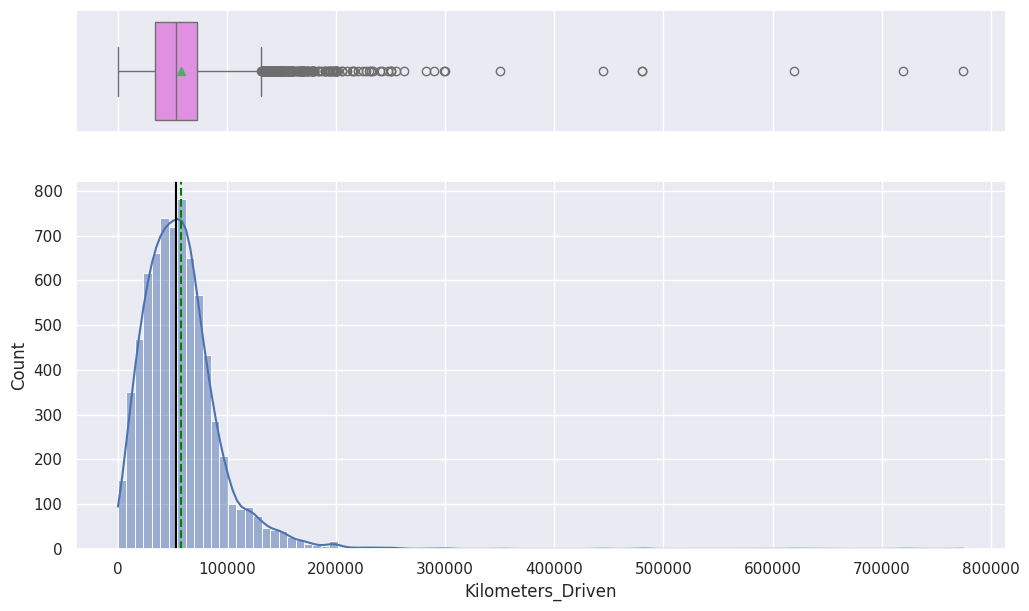


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,57818.61
Median (Q2),53442.00
Q1 (25th Percentile),34000.00
Q3 (75th Percentile),73000.00
IQR,39000.00
Kurtosis,47.17
Skewness,3.83
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-24500.00


In [130]:
histogram_boxplot(df1, "Kilometers_Driven", bins=100, kde=True)

**Observations**

* This is another highly skewed distribution.
* Let us use log transformation on this column too.

In [131]:
df1["kilometers_driven_log"] = np.log(df1["Kilometers_Driven"])

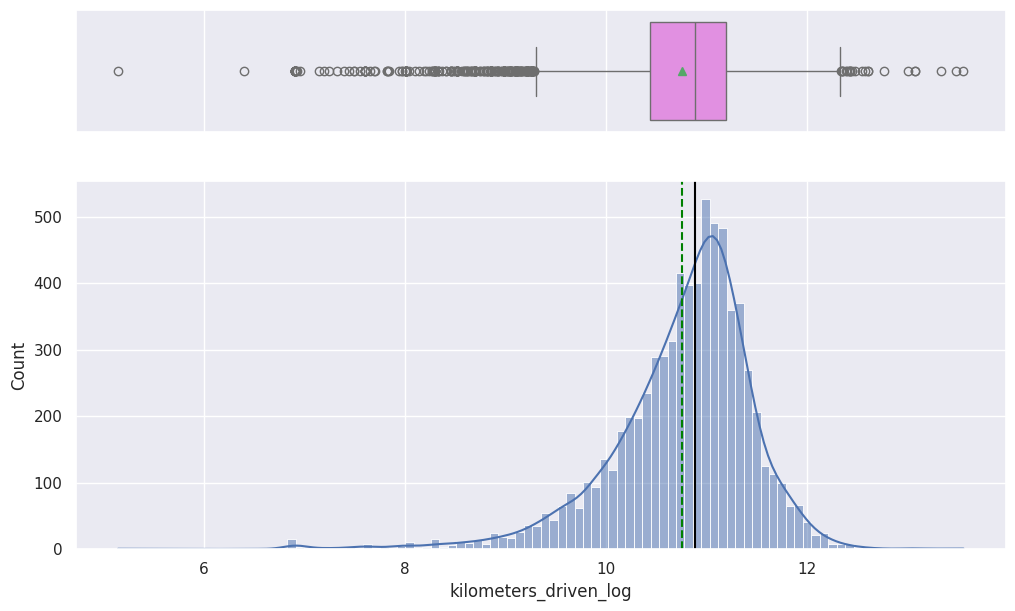


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,10.76
Median (Q2),10.89
Q1 (25th Percentile),10.43
Q3 (75th Percentile),11.20
IQR,0.76
Kurtosis,4.37
Skewness,-1.35
Tail Distribution,Left-skewed (Long left tail)
Lower Boundary (Outliers),9.29


In [132]:
histogram_boxplot(df1, "kilometers_driven_log", bins=100, kde=True)

* Transformation has reduced the extreme skewness.

#### `mileage_num`

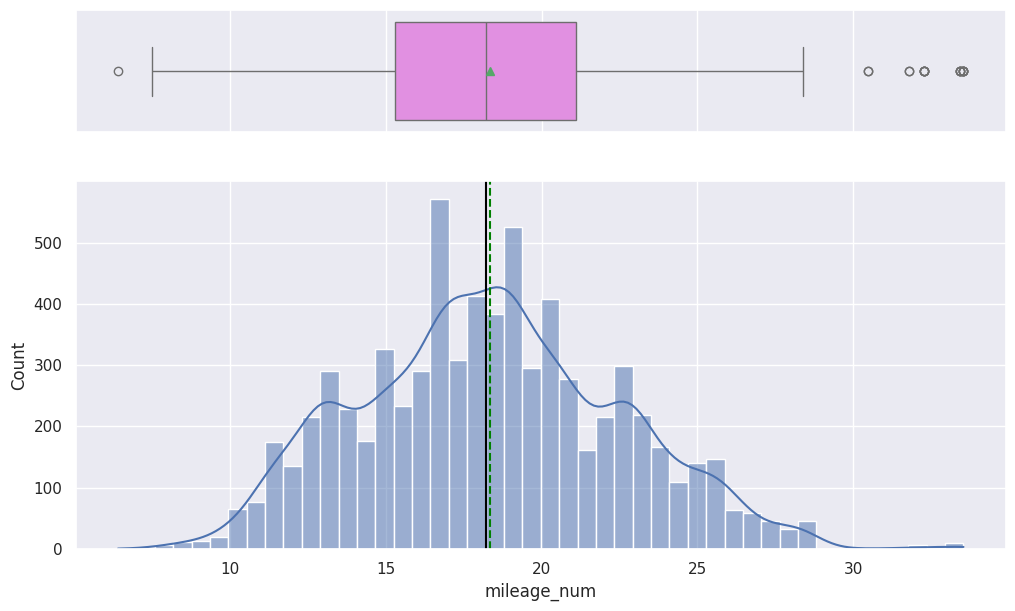


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,18.35
Median (Q2),18.20
Q1 (25th Percentile),15.30
Q3 (75th Percentile),21.10
IQR,5.80
Kurtosis,-0.27
Skewness,0.21
Tail Distribution,Approximately symmetric
Lower Boundary (Outliers),6.60


In [133]:
histogram_boxplot(df1, "mileage_num", kde=True)

**Observations**

* This is a close to normally distributed attribute.

#### `engine_num`

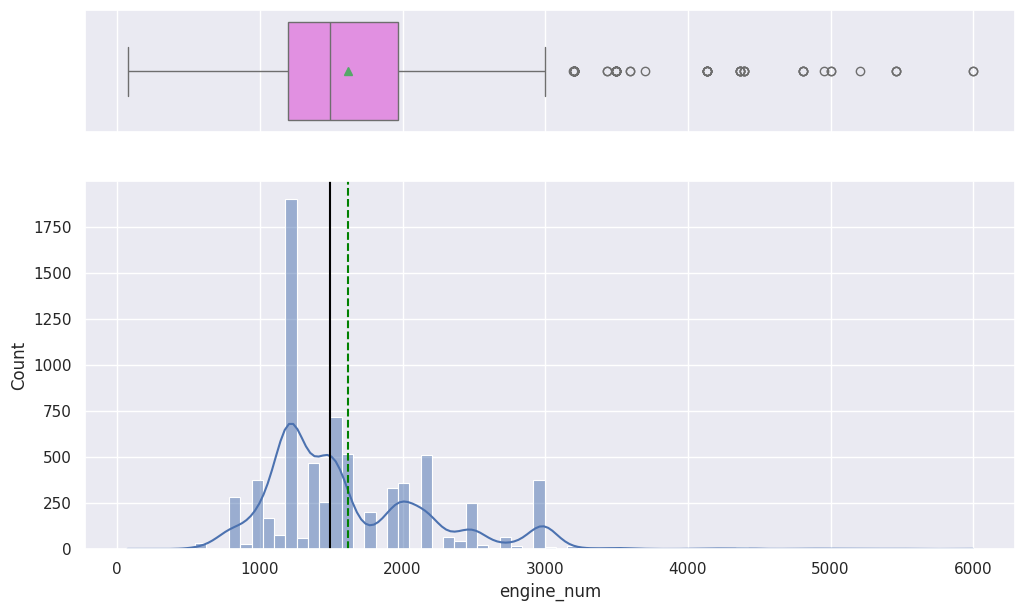


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,1616.72
Median (Q2),1493.00
Q1 (25th Percentile),1198.00
Q3 (75th Percentile),1968.00
IQR,770.00
Kurtosis,3.18
Skewness,1.41
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),43.00


In [134]:
histogram_boxplot(df1, "engine_num", kde=True)

**Observations**

* There are a few car with a higher engine displacement volume.

#### `power_num`

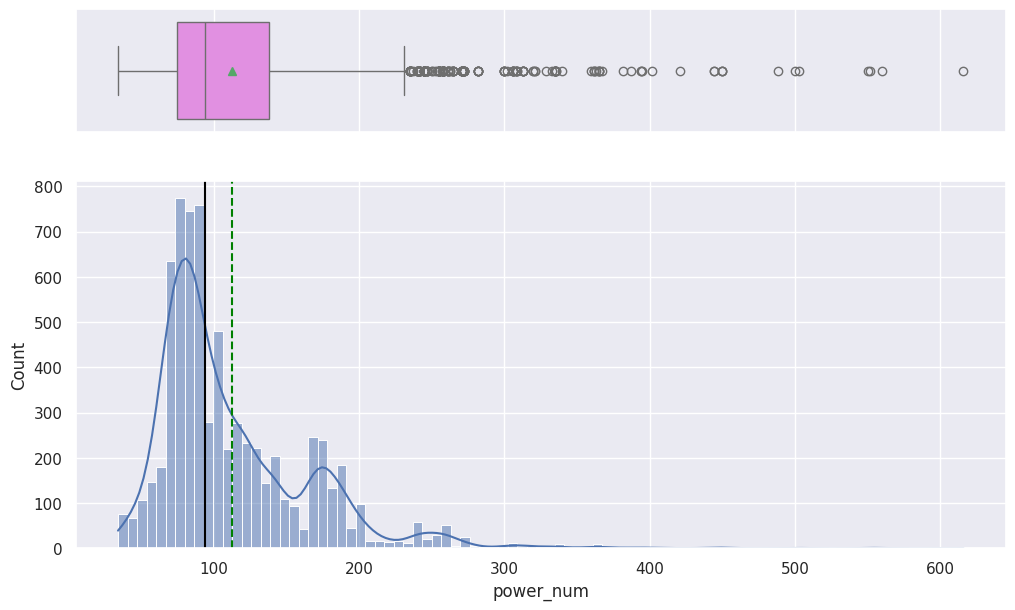


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,112.78
Median (Q2),94.00
Q1 (25th Percentile),75.00
Q3 (75th Percentile),138.10
IQR,63.10
Kurtosis,7.13
Skewness,1.96
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-19.65


In [135]:
histogram_boxplot(df1, "power_num", kde=True)

**Observations**

* There are a few car with a higher engine power.

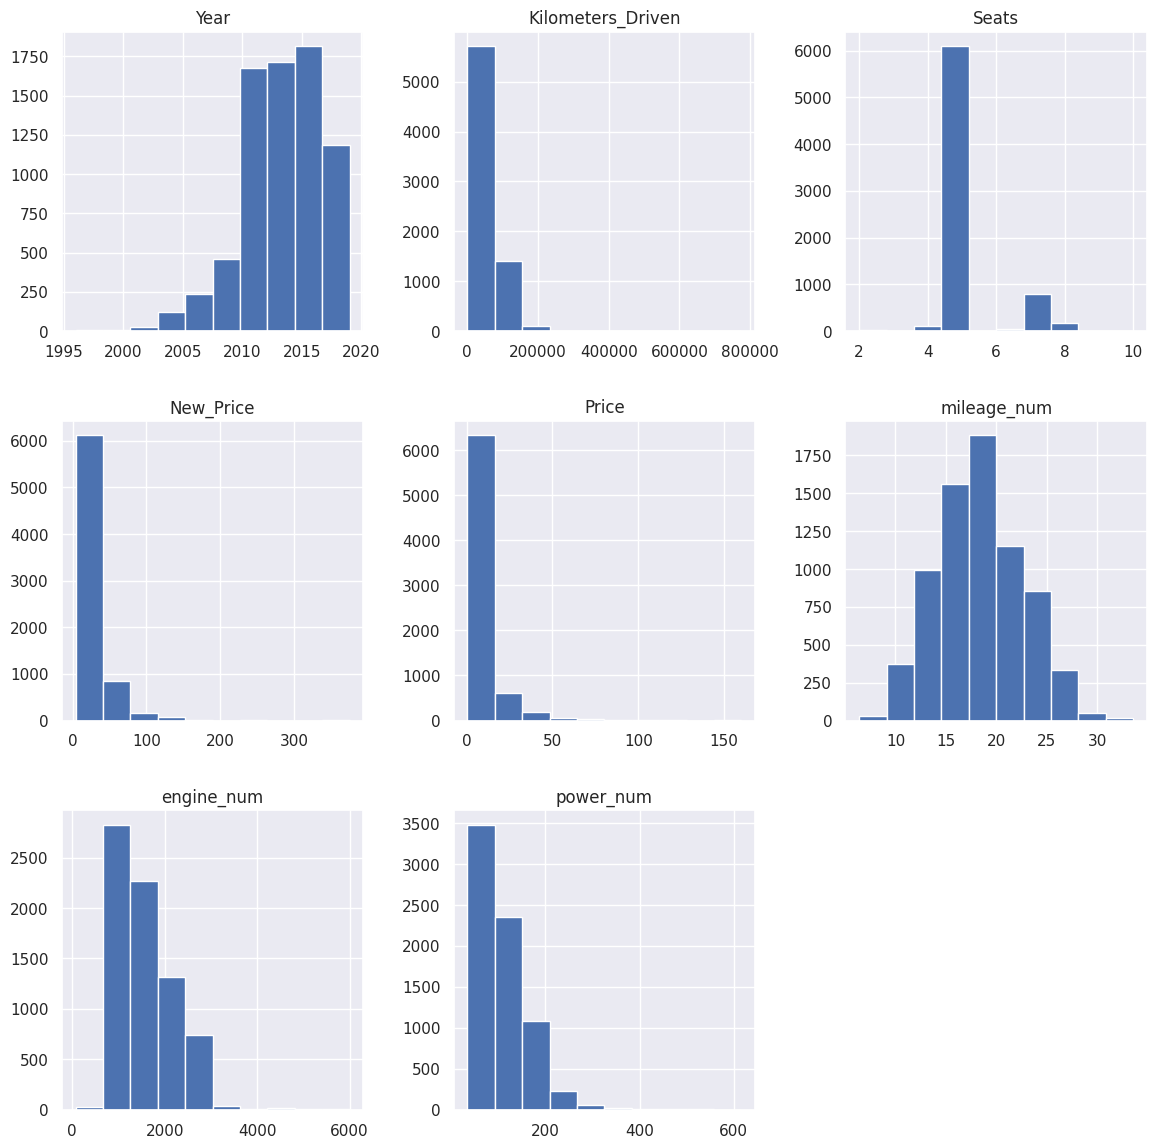

In [136]:
# creating histograms
df.hist(figsize=(14, 14))
plt.show()

- `Price`: The price of a used car is the target variable and has a highly skewed distribution, with a median value of around 53.5 lakh INR. The log transformation was applied on this column to reduce skewness. The displacement volume of the engine, the maximum power of the engine and the price of a new car of the same model is highly correlated with the price of a used car.
- `Mileage`: This attribute has a close to normally distribution. With increase in mileage, the engine displacement and power decrease.
- `Engine`: There are a few upper outliers, indicating that there are a few car with a higher engine displacement volume. Higher priced cars have higher engine displacement. It is also highly correlated with the maximum engine power.
- `Power`: There are a few upper outliers, indicating that there are a few car with a higher power. Higher priced cars have higher maximum power. It is also highly correlated with the engine displacement volume.
- `Kilometers_driven`: The number of kilometers a used car is driven has a highly skewed distribution, with a median value of around 53.5 thousand. The log transformation was applied on this column to reduce skewness.
- `New_Price`: The price of a used car is the target variable and has a highly skewed distribution, with a median value of around 11.3 lakh INR. The log transformation was applied on this column to reduce skewness.
- `Seats`: 84% of the cars in the dataset are 5-seater cars.
- `Year`: More than half the cars in the data were manufactured in or after 2014. The price of used cars has increased over the years.
- `Brand`: Most of the cars in the data belong to Maruti or Hyundai. The price of used cars is lower for budget brands like Porsche, Bentley, Lamborghini, etc. The price of used cars is higher for premium brands like Maruti, Tata, Fiat, etc.
- `Model`: Maruti Swift is the most common car up for resale. The dataset contains used cars from luxury as well as budget-friendly brands.
- `Location`: Hyderabad and Mumbai have the most demand for used cars. The price of used cars has a large IQR in Coimbatore and Bangalore.
- `Fuel_Type`: Around 1% of the cars in the dataset do not run on diesel or petrol. Electric cars have the highest median price, followed by diesel cars.
- `Transmission`: More than 70% of the cars have manual transmission. The price is higher for used cars with automatic transmission.
- `Owner_Type`: More than 80% of the used cars are being sold for the first time. The price of cars decreases as they keep getting resold.

#### `Model`

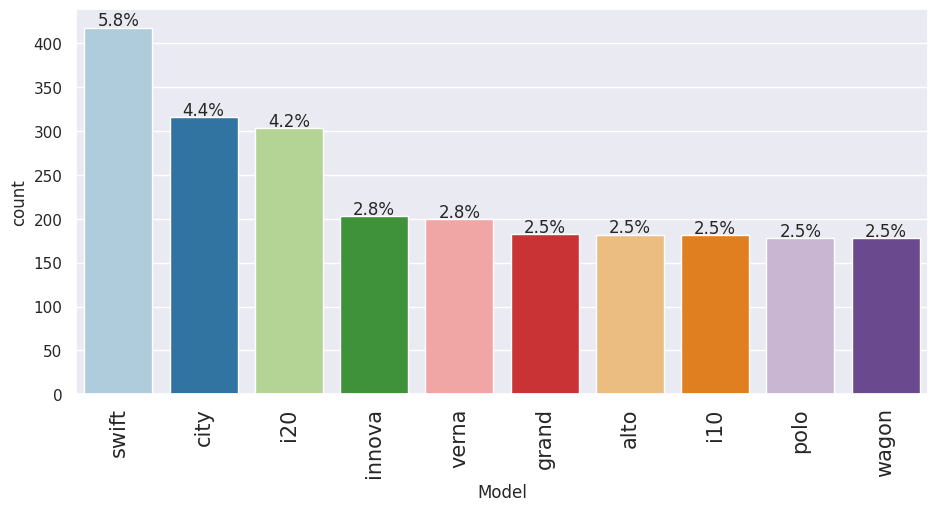

In [137]:
labeled_barplot(df1, "Model", perc=True, n=10)

**Observations**

* Maruti Swift is the most common car up for resale.

* It is clear from the above charts that our dataset contains used cars from luxury as well as budget-friendly brands.

* We can create a new variable using this information. We can consider binning all our cars into the following 3 categories later:

    1. Budget-Friendly
    2. Mid Range
    3. Luxury Cars

#### `Seats`

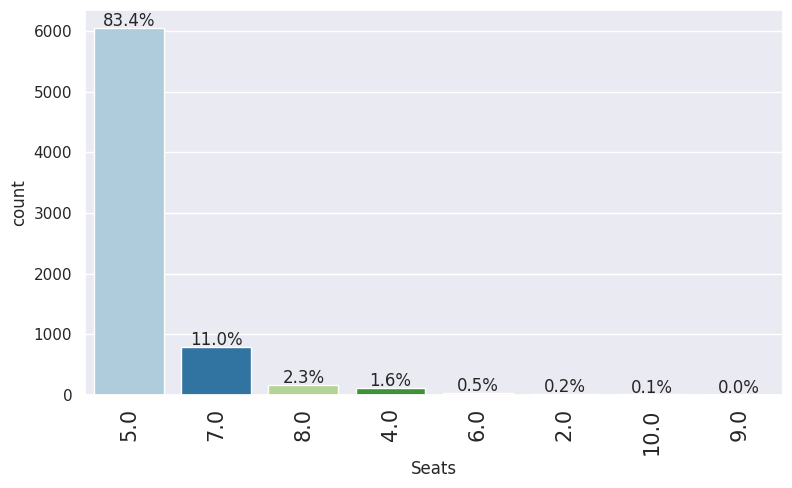

In [138]:
labeled_barplot(df1, "Seats", perc=True)

* 84% of the cars in the dataset are 5-seater cars.

#### `Year`

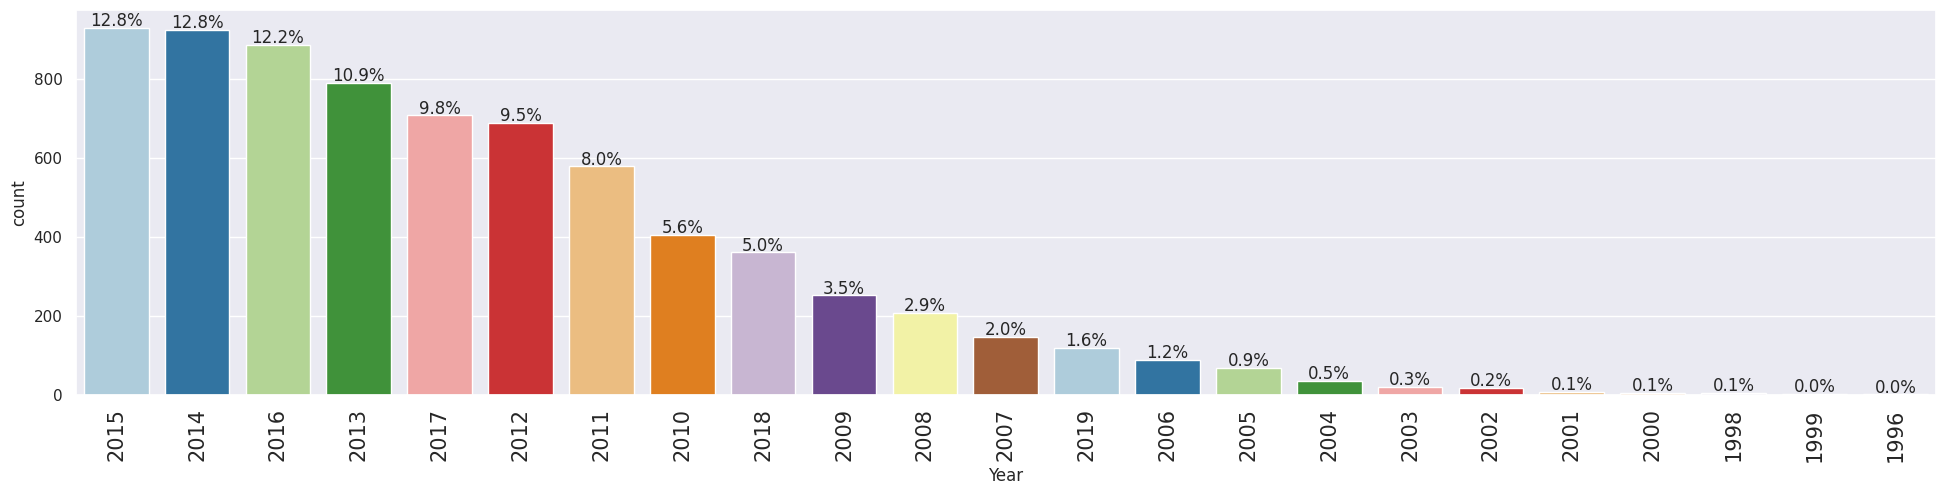

In [139]:
labeled_barplot(df1, "Year", perc=True)

* More than half the cars in the data were manufactured in or after 2014.

#### `Transmission`

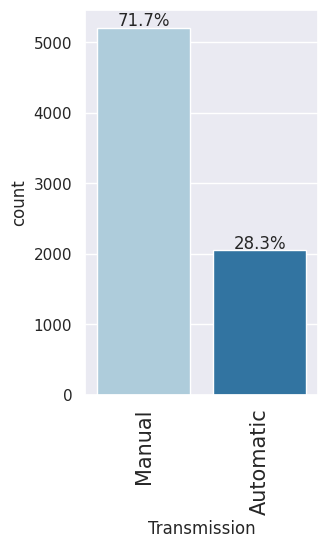

In [140]:
labeled_barplot(df1, "Transmission", perc=True)

* More than 70% of the cars have manual transmission.

#### `Owner_Type`

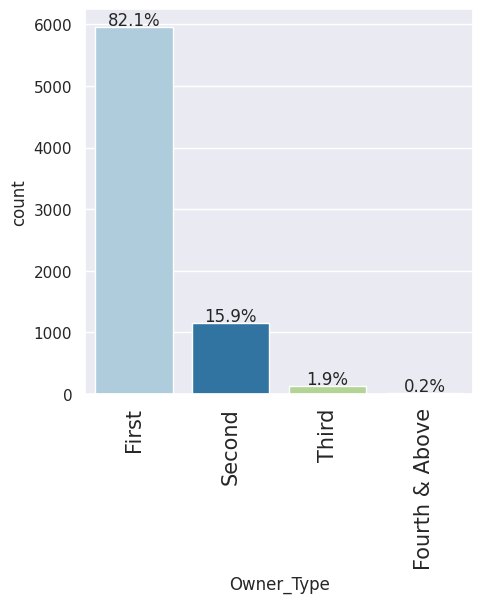

In [141]:
labeled_barplot(df1, "Owner_Type", perc=True)

* More than 80% of the used cars are being sold for the first time.

### Bivariate Analysis

**Let's check the variation in Price with some of the other variables.**

#### `Price` vs `Transmission`

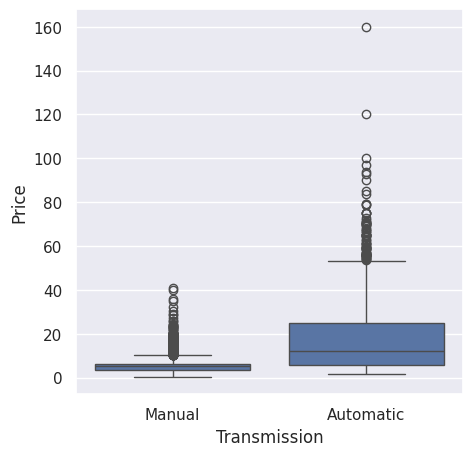

In [142]:
plt.figure(figsize=(5, 5))
sns.boxplot(x="Transmission", y="Price", data=df)
plt.show()

* The price is higher for used cars with automatic transmission.

#### `Price` vs `Fuel_Type`

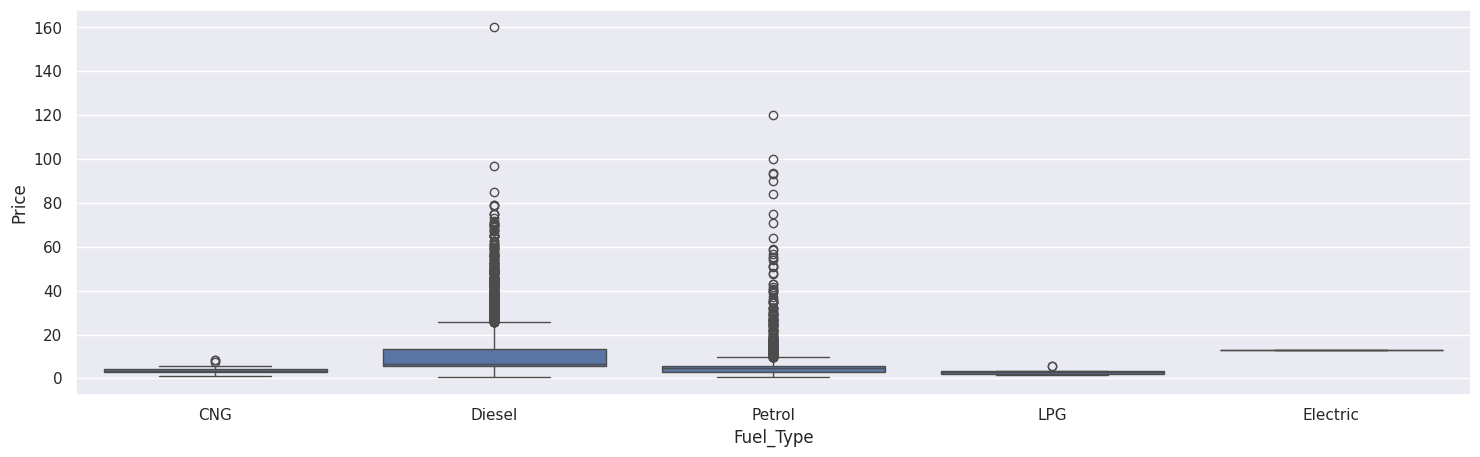

In [143]:
plt.figure(figsize=(18, 5))
sns.boxplot(x="Fuel_Type", y="Price", data=df)
plt.show()

* Electric cars have the highest median price, followed by diesel cars.

#### `Price` vs `Brand`

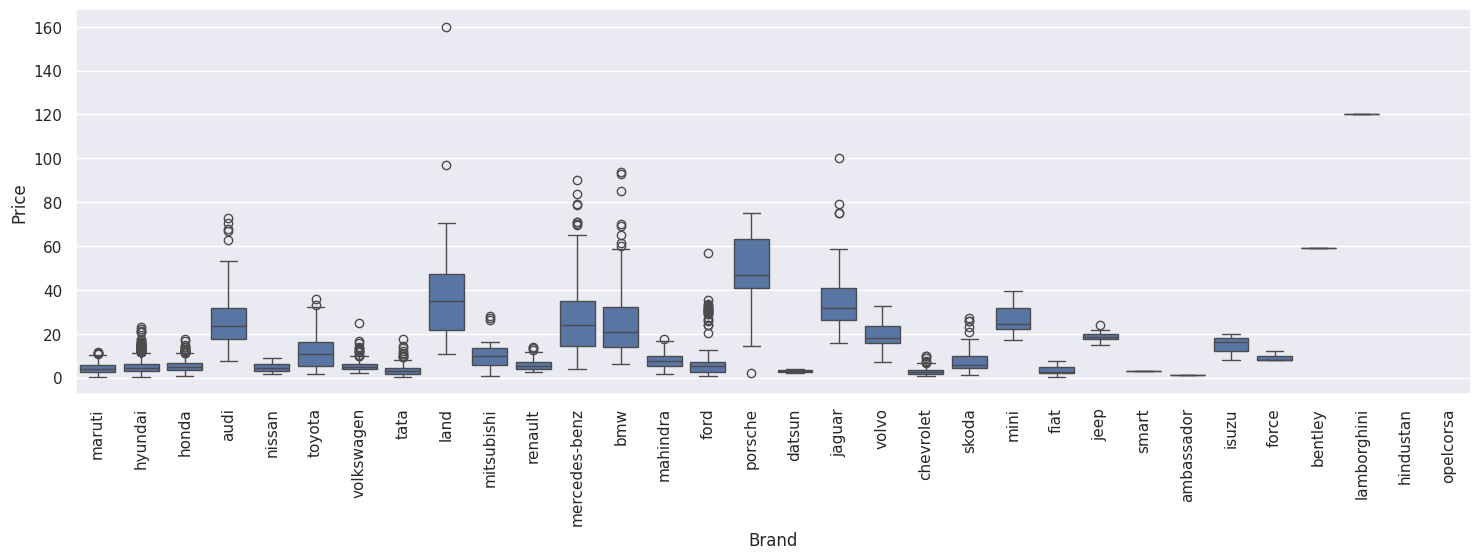

In [144]:
plt.figure(figsize=(18, 5))
sns.boxplot(x="Brand", y="Price", data=df1)
plt.xticks(rotation=90)
plt.show()

* The price of used cars is lower for budget brands like Maruti, Tata, Fiat, etc.
* The price of used cars is higher for premium brands like Porsche, Audi, Lamborghini, etc.

#### `Price` vs `Transmission`

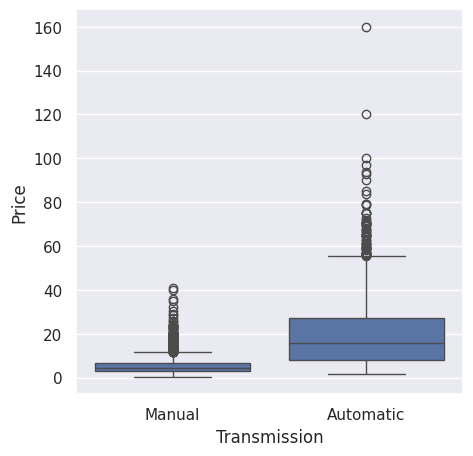

In [145]:
plt.figure(figsize=(5, 5))
sns.boxplot(x="Transmission", y="Price", data=df1)
plt.show()

* The price is higher for used cars with automatic transmission.

#### `Price` vs `Fuel_Type`

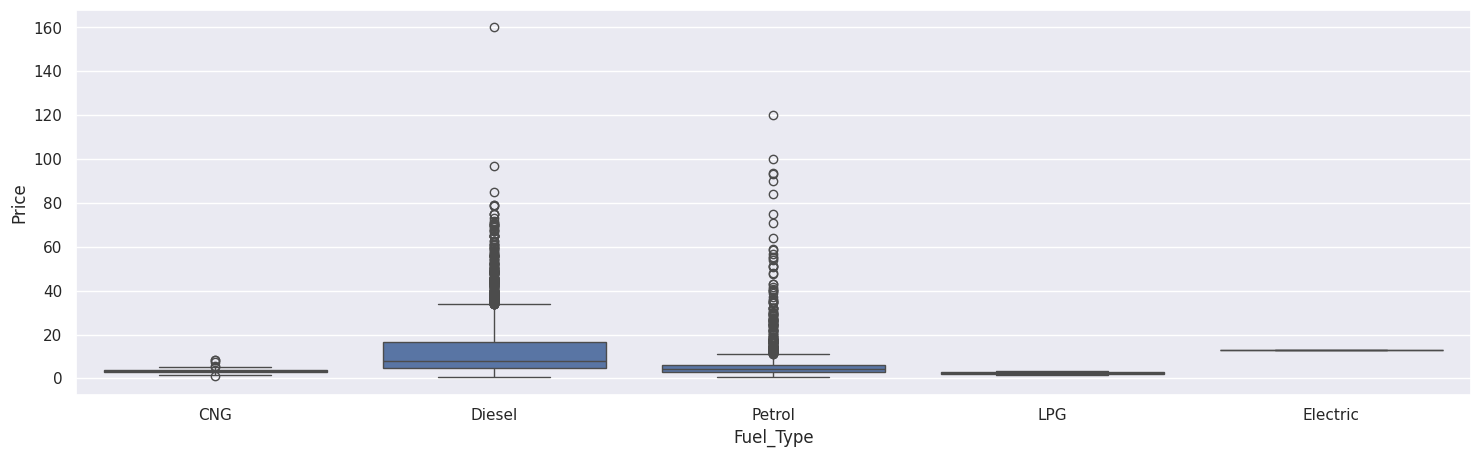

In [146]:
plt.figure(figsize=(18, 5))
sns.boxplot(x="Fuel_Type", y="Price", data=df1)
plt.show()

* Electric cars have the highest median price, followed by diesel cars.

#### `Price` vs `Owner_Type`

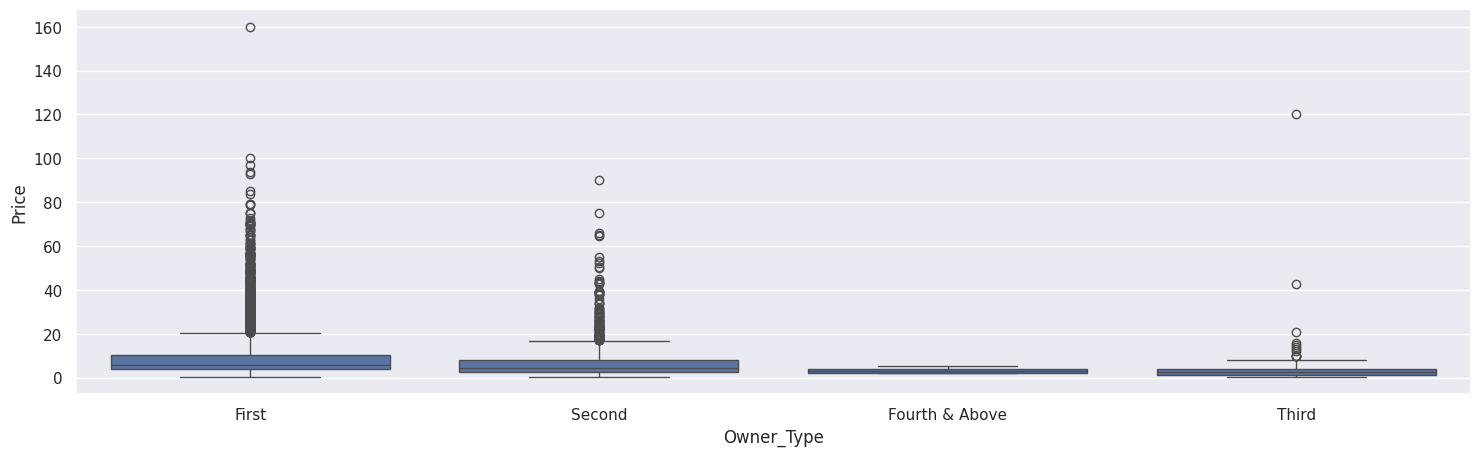

In [147]:
plt.figure(figsize=(18, 5))
sns.boxplot(x="Owner_Type", y="Price", data=df1)
plt.show()

* The price of cars decreases as they keep getting resold.

#### Pairplot for relations between numerical variables

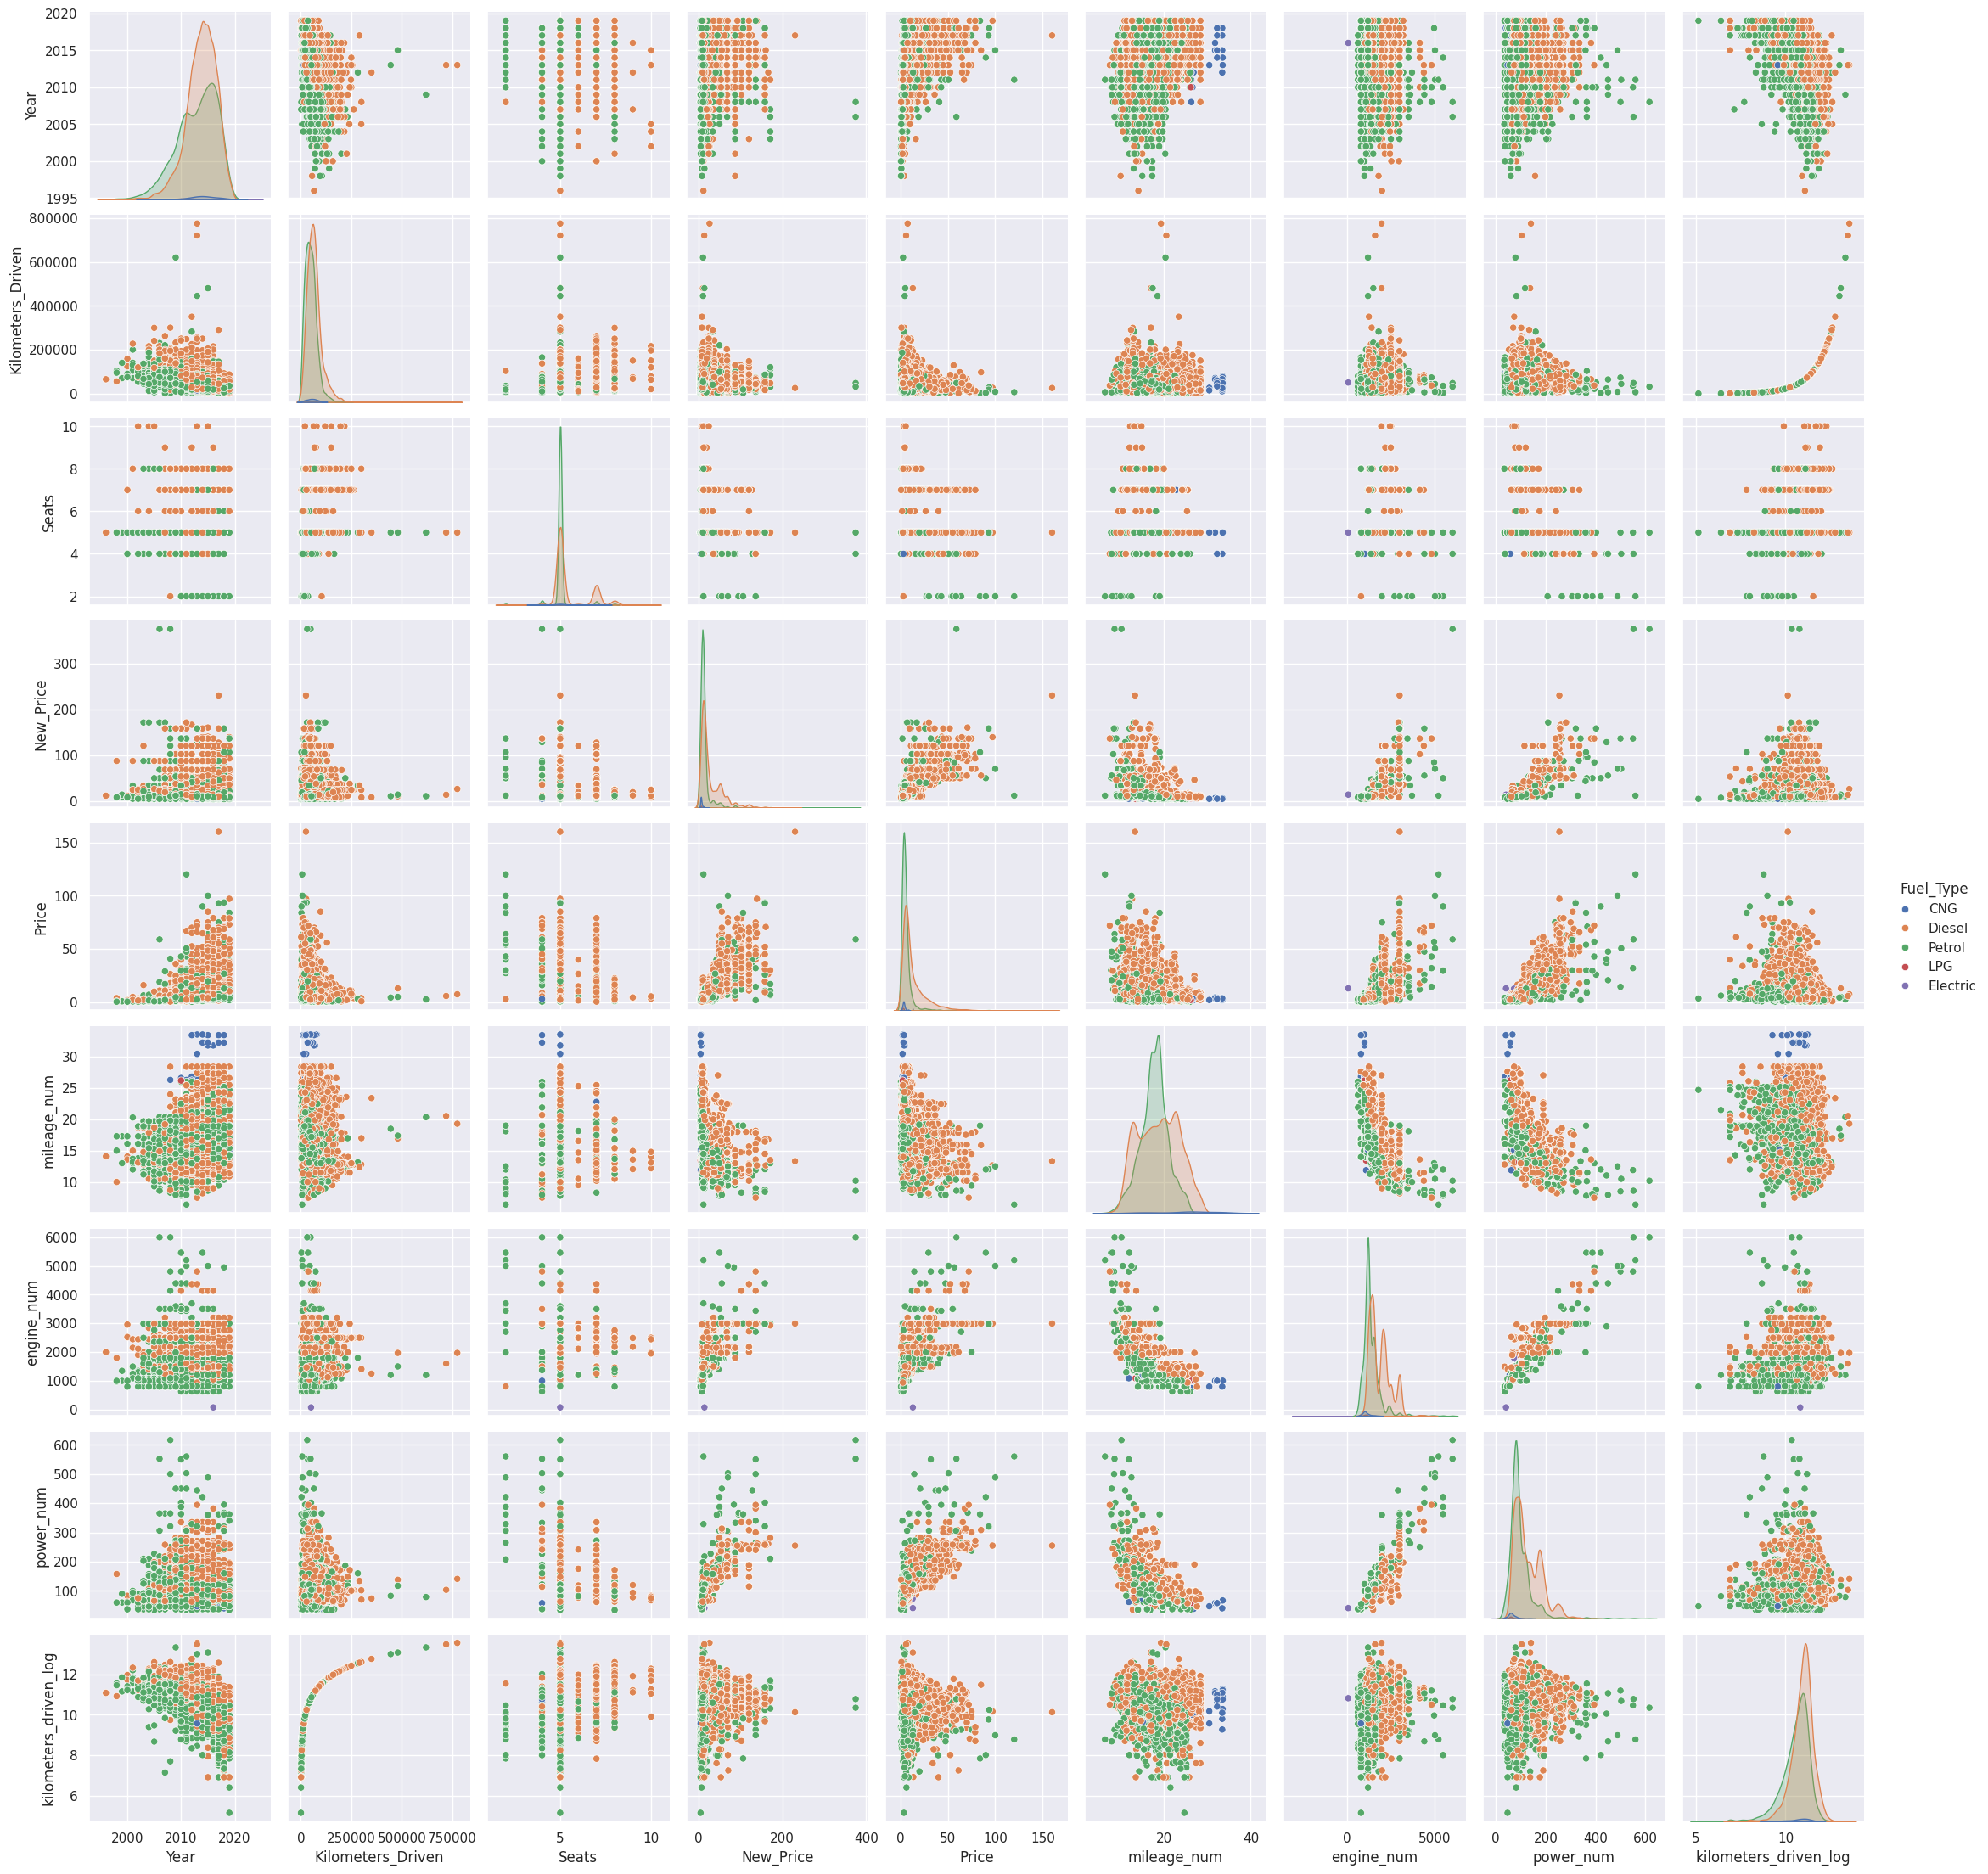

In [148]:
sns.pairplot(data=df1, hue="Fuel_Type")
plt.show()


Zooming into these plots gives us a lot of information.

- Contrary to intuition, `Kilometers_Driven` does not seem to have a relationship with the price.
- `Price` has a positive relationship with `Year`, i.e., the newer the car, the higher the price.
    - The temporal element of variation is captured in the year column.

- 2 seater cars are all luxury variants. Cars with 8-10 seats are exclusively mid to high range.
- Mileage does not seem to show much relationship with the price of used cars.
- Engine displacement and power of the car have a positive relationship with the price.
- `New_Price` and used car price are also positively correlated, which is expected.
- `Kilometers_Driven` has a peculiar relationship with the `Year` variable. Generally, the newer the car lesser the distance it has traveled, but this is not always true.
- CNG cars are conspicuous outliers when it comes to `Mileage`. The mileage of these cars is very high.
- The mileage and power of newer cars are increasing owing to advancements in technology.
- Mileage has a negative correlation with engine displacement and power. More powerful the engine, the more fuel it consumes in general.

### To jump back to the EDA summary section, click <a href = #link2>here</a>.

Anime Ratings Case Study
Supervised Learning Regression Project: Anime Rating
Problem Statement
Business Context
Streamist is a streaming company that streams web series and movies for a worldwide audience. Every content on their portal is rated by the viewers, and the portal also provides other information for the content like the number of people who have watched it, the number of people who want to watch it, the number of episodes, duration of an episode, etc.

They are currently focusing on the anime available in their portal, and want to identify the most important factors involved in rating an anime. You as a data scientist at Streamist are tasked with identifying the important factors and building a predictive model to predict the rating on an anime.

Objective
To analyze the data and build a linear regression model to predict the ratings of anime.

Key Questions
What are the key factors influencing the rating of an anime?
Is there a good predictive model for the rating of an anime? What does the performance assessment look like for such a model?
Data Description
Each record in the database provides a description of an anime. A detailed data dictionary can be found below.

Data Dictionary

title - the title of anime
description - the synopsis of the plot
mediaType - format of publication
eps - number of episodes (movies are considered 1 episode)
duration - duration of an episode in minutes
ongoing - whether it is ongoing
sznOfRelease - the season of release (Winter, Spring, Fall)
years_running - number of years the anime ran/is running
studio_primary - primary studio of production
studios_colab - whether there was a collaboration between studios to produce the anime
contentWarn - whether anime has a content warning
watched - number of users that completed it
watching - number of users that are watching it
wantWatch - number of users that want to watch it
dropped - number of users that dropped it before completion
rating - average user rating
votes - number of votes that contribute to rating
tag_Based_on_a_Manga - whether the anime is based on a manga
tag_Comedy - whether the anime is of Comedy genre
tag_Action - whether the anime is of Action genre
tag_Fantasy - whether the anime is of Fantasy genre
tag_Sci_Fi - whether the anime is of Sci-Fi genre
tag_Shounen - whether the anime has a tag Shounen
tag_Original_Work - whether the anime is an original work
tag_Non_Human_Protagonists - whether the anime has any non-human protagonists
tag_Drama - whether the anime is of Drama genre
tag_Adventure - whether the anime is of Adventure genre
tag_Family_Friendly - whether the anime is family-friendly
tag_Short_Episodes - whether the anime has short episodes
tag_School_Life - whether the anime is regarding school life
tag_Romance - whether the anime is of Romance genre
tag_Shorts - whether the anime has a tag Shorts
tag_Slice_of_Life - whether the anime has a tag Slice of Life
tag_Seinen - whether the anime has a tag Seinen
tag_Supernatural - whether the anime has a tag Supernatural
tag_Magic - whether the anime has a tag Magic
tag_Animal_Protagonists - whether the anime has animal protagonists
tag_Ecchi - whether the anime has a tag Ecchi
tag_Mecha - whether the anime has a tag Mecha
tag_Based_on_a_Light_Novel - whether the anime is based on a light novel
tag_CG_Animation - whether the anime has a tag CG Animation
tag_Superpowers - whether the anime has a tag Superpowers
tag_Others - whether the anime has other tags
tag_is_missing - whether tag is missing or not
Installing and Importing thenecessary libraries

In [149]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
from sklearn.linear_model import LinearRegression

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [150]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [152]:

# loading the dataset
df = pd.read_csv("/content/drive/MyDrive/anime_data.csv")

In [153]:
# to view first 5 rows of the dataset
df.head()

,title,description,mediaType,eps,duration,ongoing,sznOfRelease,years_running,studio_primary,studios_colab,contentWarn,watched,watching,wantWatch,dropped,rating,votes,tag_Based_on_a_Manga,tag_Comedy,tag_Action,tag_Fantasy,tag_Sci_Fi,tag_Shounen,tag_Original_Work,tag_Non_Human_Protagonists,tag_Drama,tag_Adventure,tag_Family_Friendly,tag_Short_Episodes,tag_School_Life,tag_Romance,tag_Shorts,tag_Slice_of_Life,tag_Seinen,tag_Supernatural,tag_Magic,tag_Animal_Protagonists,tag_Ecchi,tag_Mecha,tag_Based_on_a_Light_Novel,tag_CG_Animation,tag_Superpowers,tag_Others,tag_missing
0,Fullmetal Alchemist: Brotherhood,The foundation of alchemy is based on the law ...,TV,64,NaN,False,Spring,1,Bones,0,1,103707.0,14351,25810,2656,4.702,86547,1,0,1,1,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,your name.,Mitsuha and Taki are two total strangers livin...,Movie,1,107.0,False,is_missing,0,Others,0,0,58831.0,1453,21733,124,4.663,43960,0,0,0,0,0,0,1,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0
2,A Silent Voice,"After transferring into a new school, a deaf g...",Movie,1,130.0,False,is_missing,0,Kyoto Animation,0,1,45892.0,946,17148,132,4.661,33752,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,Haikyuu!! Karasuno High School vs Shiratorizaw...,"Picking up where the second season ended, the ...",TV,10,NaN,False,Fall,0,Production I.G,0,0,25134.0,2183,8082,167,4.660,17422,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,Attack on Titan 3rd Season: Part II,The battle to retake Wall Maria begins now! Wi...,TV,10,NaN,False,Spring,0,Others,0,1,21308.0,3217,7864,174,4.650,15789,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [155]:
# checking shape of the data
print(f"There are {df.shape[0]} rows and {df.shape[1]} columns.")

There are 12101 rows and 44 columns.


In [156]:
# let's create a copy of the data to avoid any changes to original data
data = df.copy()

In [157]:
# checking column datatypes and number of non-null values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12101 entries, 0 to 12100
Data columns (total 44 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   title                       12101 non-null  object 
 1   description                 7633 non-null   object 
 2   mediaType                   12101 non-null  object 
 3   eps                         12101 non-null  int64  
 4   duration                    7465 non-null   float64
 5   ongoing                     12101 non-null  bool   
 6   sznOfRelease                12101 non-null  object 
 7   years_running               12101 non-null  int64  
 8   studio_primary              12101 non-null  object 
 9   studios_colab               12101 non-null  int64  
 10  contentWarn                 12101 non-null  int64  
 11  watched                     12101 non-null  float64
 12  watching                    12101 non-null  int64  
 13  wantWatch                   121

Dependent variable is the rating of an anime, which if of float type.
title, description, mediaType, sznOfRelease, studio_primary are of object type.
ongoing column is of bool type.
All other columns are numeric in nature.
There are missing values in the description and duration columns.
Checking for duplicate values

In [158]:
# checking for duplicate values in the data
data.duplicated().sum()

np.int64(0)

In [159]:
# Let's look at the statistical summary of the data
data.describe().T

,count,mean,std,min,25%,50%,75%,max
eps,12101.0,13.393356,57.925097,1.000,1.000,2.000,12.000,2527.000
duration,7465.0,24.230141,31.468171,1.000,4.000,8.000,30.000,163.000
years_running,12101.0,0.283200,1.152234,0.000,0.000,0.000,0.000,51.000
studios_colab,12101.0,0.051649,0.221326,0.000,0.000,0.000,0.000,1.000
contentWarn,12101.0,0.115362,0.319472,0.000,0.000,0.000,0.000,1.000
watched,12101.0,2862.605694,7724.347024,0.000,55.000,341.000,2026.000,161567.000
watching,12101.0,256.334435,1380.840902,0.000,2.000,14.000,100.000,74537.000
wantWatch,12101.0,1203.681431,2294.327380,0.000,49.000,296.000,1275.000,28541.000
dropped,12101.0,151.568383,493.931710,0.000,3.000,12.000,65.000,19481.000
rating,12101.0,2.949037,0.827385,0.844,2.304,2.965,3.616,4.702


We can see that the anime ratings vary between 0.844 and 4.702, which suggests that the anime were rated on a scale of 0-5.

50% of the anime in the data have a runtime less than or equal to 8 minutes.

Some anime even have a runtime of 1 minute.

This seems strange at first, but a Google search can reveal that there are indeed such anime.
At least 75% of the anime have run for less than a year.

This may be because the listed anime has few episodes only.
At least 75% of the anime have no content warnings.

The number of views for the anime in the data has a very wide range (0 to more than 160,000).

Checking the unique values in each of the columns

In [160]:
# filtering non-numeric columns
cat_columns = data.select_dtypes(exclude=np.number).columns
cat_columns

Index(['title', 'description', 'mediaType', 'ongoing', 'sznOfRelease',
       'studio_primary'],
      dtype='object')

In [162]:
# we will skip the title and description columns as they will have a lot of unique values
cat_col = ["mediaType", "ongoing", "sznOfRelease", "studio_primary"]

# printing a tabular summary of count and % share for each categorical column
for column in cat_col:
    count = data[column].value_counts(dropna=False)
    percentage = data[column].value_counts(dropna=False, normalize=True) * 100

    summary_df = pd.DataFrame({
        'Count': count,
        'Percentage (%)': percentage.round(2)
    })

    print(f"Tabular Summary for {column}:")
    display(summary_df)
    print("-" * 50)

Tabular Summary for mediaType:


,Count,Percentage (%)
mediaType,,
TV,3993,33.00
Movie,1928,15.93
OVA,1770,14.63
Music Video,1290,10.66
Web,1170,9.67
DVD Special,803,6.64
Other,580,4.79
TV Special,504,4.16
is_missing,63,0.52


--------------------------------------------------
Tabular Summary for ongoing:


,Count,Percentage (%)
ongoing,,
False,11986,99.05
True,115,0.95


--------------------------------------------------
Tabular Summary for sznOfRelease:


,Count,Percentage (%)
sznOfRelease,,
is_missing,8554,70.69
Spring,1135,9.38
Fall,1011,8.35
Winter,717,5.93
Summer,684,5.65


--------------------------------------------------
Tabular Summary for studio_primary:


,Count,Percentage (%)
studio_primary,,
Others,4340,35.86
is_missing,3208,26.51
Toei Animation,636,5.26
Sunrise,430,3.55
J.C. Staff,341,2.82
MADHOUSE,337,2.78
TMS Entertainment,317,2.62
Production I.G,271,2.24
Studio Deen,260,2.15


--------------------------------------------------


Most of the anime in the data are either TV series or movies.
Most of the anime in the data are not ongoing.
The season of release is missing for most of the anime in the data.
Toei Animation and Sunrise are the top two studios (excluding other studios and missing studios).
Checking the missing values

In [163]:
# checking for missing values in the data
data.isnull().sum()

,0
title,0
description,4468
mediaType,0
eps,0
duration,4636
ongoing,0
sznOfRelease,0
years_running,0
studio_primary,0
studios_colab,0


type: int64
duration column has 4636 missing values, and description column has 4468 missing values.
No other column has missing values.
We will drop the missing values in the dataset

In [164]:
data.dropna(inplace=True)
data.shape

(3712, 44)

In [174]:
import pandas as pd
import numpy as np

# ========================================== #
# STEP 1: LOAD AND CLEAN THE DATA             #
# ========================================== #
# Load the anime dataset containing titles, descriptions, and tag columns
df_anime = pd.read_csv('/content/drive/MyDrive/anime_data.csv')

# Remove any entries that are missing titles or descriptions to prevent processing errors
df_anime.dropna(subset=['description', 'title'], inplace=True)

# ========================================== #
# STEP 2: DEFINE KEYWORDS FOR GENRE MATCHING  #
# ========================================== #
# We define dictionaries of keywords representing each of our 8 target genres.
# If these words appear in an anime's description, they count as matches for that genre.
genre_keywords = {
    'thriller': ['thriller', 'suspense', 'mystery', 'psychological', 'crime', 'investigation', 'tension', 'detective', 'police', 'murder', 'killer', 'death', 'dark'],
    'horror': ['horror', 'scary', 'spooky', 'ghost', 'blood', 'monster', 'dark', 'creepy', 'nightmare', 'gore', 'zombie', 'demon', 'vampire', 'curse'],
    'comedy': ['comedy', 'funny', 'humor', 'hilarious', 'laugh', 'parody', 'joke', 'comic', 'gag', 'slice of life', 'school', 'fun', 'amusing'],
    'love': ['love', 'romance', 'romantic', 'couple', 'boyfriend', 'girlfriend', 'dating', 'affection', 'heart', 'marry', 'marriage', 'relationship', 'shoujo'],
    'action': ['action', 'fight', 'battle', 'combat', 'war', 'sword', 'gun', 'martial', 'hero', 'villain', 'ninja', 'soldier', 'army', 'power'],
    'fantasy': ['fantasy', 'magic', 'supernatural', 'spell', 'wizard', 'mythical', 'spirit', 'demon', 'fairy', 'god', 'isekai', 'adventure', 'world'],
    'sci-fi': ['sci-fi', 'science fiction', 'space', 'robot', 'future', 'futuristic', 'alien', 'technology', 'mecha', 'machine', 'cyberpunk'],
    'inspirational': ['emotional', 'inspirational', 'sad', 'cry', 'tears', 'heartwarming', 'touching', 'drama', 'tragedy', 'feelings', 'melodrama', 'inspire', 'hope']
}

# Create a starting scoreboard (initialized to 0.0) for each genre for every anime
keyword_counts = pd.DataFrame(0.0, index=df_anime.index, columns=genre_keywords.keys())

# Convert descriptions to lowercase so we don't miss matches due to capitalization
desc_lower = df_anime['description'].str.lower()

# Count occurrences of our specified words in the lowercase descriptions
for genre, keywords in genre_keywords.items():
    for word in keywords:
        keyword_counts[genre] += desc_lower.str.count(rf'\b{word}\b')

# ========================================== #
# STEP 3: BLEND IN EXPLICIT DATABASE TAGS     #
# ========================================== #
# If the database already has active binary tags for these genres, we map them here.
# This boosts accuracy by leveraging pre-existing metadata tags alongside description keywords.
tag_mapping = {
    'thriller': 'tag_missing', # default column if thriller tag is absent
    'horror': 'tag_Supernatural',
    'comedy': 'tag_Comedy',
    'love': 'tag_Romance',
    'action': 'tag_Action',
    'fantasy': 'tag_Fantasy',
    'sci-fi': 'tag_Sci_Fi',
    'inspirational': 'tag_Drama'
}

# If an anime explicitly has the genre tag active, we add a strong weight of +2 to its score
for genre, tag_col in tag_mapping.items():
    if tag_col in df_anime.columns:
        keyword_counts[genre] += df_anime[tag_col].astype(float) * 2.0

# ========================================== #
# STEP 4: CALCULATE THE PERCENTAGE SHARE     #
# ========================================== #
# We find the total score sum for each anime (row) across all 8 genres
row_sums = keyword_counts.sum(axis=1)

# Divide each genre's score by the total sum to get its percentage share (decimal)
keyword_counts_norm = keyword_counts.div(row_sums, axis=0)

# ========================================== #
# STEP 5: HANDLE ZERO MATCHES (FALLBACK PRIOR)#
# ========================================== #
# If a movie had zero keyword or tag matches, its row sum is 0, which results in 'NaN' (not a number).
# We fall back to a realistic general distribution based on common genre frequencies including our new genre.
prior_weights = pd.Series({
    'thriller': 0.09,
    'horror': 0.10,
    'comedy': 0.22,
    'love': 0.14,
    'action': 0.16,
    'fantasy': 0.11,
    'sci-fi': 0.06,
    'inspirational': 0.12
})

# Fill any NaN records with these realistic prior shares
for col in keyword_counts_norm.columns:
    keyword_counts_norm[col] = keyword_counts_norm[col].fillna(prior_weights[col])

# Convert decimals to clean percentages (rounded to 2 decimal places)
genre_percentages = (keyword_counts_norm * 100).round(2)

# Combine the anime titles together with their final genre splits
df_anime_processed = pd.concat([df_anime[['title']], genre_percentages], axis=1)

# ========================================== #
# STEP 6: CONVENIENCE LOOKUP FUNCTIONS       #
# ========================================== #

# Function to search and find the percentage breakdown for a specific title
def get_movie_genre_split(title_name):
    match = df_anime_processed[df_anime_processed['title'].str.lower() == title_name.lower()]
    if match.empty:
        match = df_anime_processed[df_anime_processed['title'].str.lower().str.contains(title_name.lower())]
    if match.empty:
        return f"No matching anime found for '{title_name}'"
    return match

# Function to calculate dataset-wide genre statistics above a minimum representation threshold
def get_global_genre_split(threshold=15.0):
    counts = (genre_percentages > threshold).sum()
    total_animes = len(df_anime_processed)
    pcts = (counts / total_animes * 100).round(2)
    summary_df = pd.DataFrame({
        'Anime Count': counts,
        'Percentage (%)': pcts
    }).sort_values(by='Anime Count', ascending=False)

    print(f"\nOverall Genre-wise Count and Percentage Split (Threshold > {threshold}%):\n")
    display(summary_df)

# Execute global distribution overview
get_global_genre_split()

# Show a quick demonstration lookup for 'your name.'
print("\nExample Lookup for 'your name.':")
display(get_movie_genre_split('your name.'))



Overall Genre-wise Count and Percentage Split (Threshold > 15.0%):



,Anime Count,Percentage (%)
action,3695,48.41
comedy,3424,44.86
fantasy,2834,37.13
sci-fi,1926,25.23
love,1328,17.40
inspirational,1298,17.01
horror,997,13.06
thriller,596,7.81



Example Lookup for 'your name.':


,title,thriller,horror,comedy,love,action,fantasy,sci-fi,inspirational
1,your name.,0.0,33.33,0.0,33.33,0.0,0.0,0.0,33.33


In [175]:
# ========================================== #
# STEP 7: DISPLAY GENRE BREAKDOWNS FOR SAMPLE#
# ========================================== #
# We take the unique movie/anime titles and extract the first 30 titles
sample_movie_titles = df_anime_processed['title'].drop_duplicates().head(30)

# Filter the processed dataset to only show these 30 sample titles with our new 8-genre setup
sample_genre_breakdowns = df_anime_processed[df_anime_processed['title'].isin(sample_movie_titles)]

# Display the final beautiful summary table
print("Genre % Split for 30 Sample Movies/Animes (Including 'Inspirational'):")
pd.set_option('display.max_rows', 35)
display(sample_genre_breakdowns.reset_index(drop=True))

Genre % Split for 30 Sample Movies/Animes (Including 'Inspirational'):


,title,thriller,horror,comedy,love,action,fantasy,sci-fi,inspirational
0,Fullmetal Alchemist: Brotherhood,0.0,0.00,0.00,0.00,33.33,33.33,0.00,33.33
1,your name.,0.0,33.33,0.00,33.33,0.00,0.00,0.00,33.33
2,A Silent Voice,0.0,0.00,33.33,0.00,0.00,0.00,0.00,66.67
3,Haikyuu!! Karasuno High School vs Shiratorizaw...,0.0,0.00,100.00,0.00,0.00,0.00,0.00,0.00
4,Attack on Titan 3rd Season: Part II,0.0,0.00,0.00,0.00,57.14,42.86,0.00,0.00
5,Demon Slayer: Kimetsu no Yaiba,0.0,9.09,18.18,0.00,18.18,36.36,0.00,18.18
6,Haikyuu!! Second Season,9.0,10.00,22.00,14.00,16.00,11.00,6.00,12.00
7,Hunter x Hunter (2011),0.0,0.00,0.00,0.00,28.57,42.86,0.00,28.57
8,Gintama Kanketsu-hen: Yorozuya yo Eien Nare,0.0,0.00,18.18,0.00,18.18,18.18,18.18,27.27
9,Gintama (2015),0.0,0.00,25.00,0.00,25.00,0.00,25.00,25.00


In [177]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined along with a statistical summary table below

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram

    mean_val = data[feature].mean()
    median_val = data[feature].median()

    ax_hist2.axvline(
        mean_val, color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        median_val, color="black", linestyle="-"
    )  # Add median to the histogram

    plt.show()

    # Calculating statistical summaries
    q1 = data[feature].quantile(0.25)
    q3 = data[feature].quantile(0.75)
    iqr = q3 - q1
    lower_whisker = q1 - 1.5 * iqr
    upper_whisker = q3 + 1.5 * iqr

    num_outliers = data[(data[feature] < lower_whisker) | (data[feature] > upper_whisker)].shape[0]
    skew_val = data[feature].skew()
    kurt_val = data[feature].kurt()

    # Determine tail direction based on skewness
    if skew_val > 0.5:
        tail_direction = "Right-skewed (Long right tail)"
    elif skew_val < -0.5:
        tail_direction = "Left-skewed (Long left tail)"
    else:
        tail_direction = "Approximately symmetric"

    # Creating summary table
    summary_df = pd.DataFrame({
        "Metric": [
            "Mean",
            "Median (Q2)",
            "Q1 (25th Percentile)",
            "Q3 (75th Percentile)",
            "IQR",
            "Kurtosis",
            "Skewness",
            "Tail Distribution",
            "Lower Boundary (Outliers)",
            "Upper Boundary (Outliers)",
            "Count of Outliers"
        ],
        "Value": [
            f"{mean_val:.2f}",
            f"{median_val:.2f}",
            f"{q1:.2f}",
            f"{q3:.2f}",
            f"{iqr:.2f}",
            f"{kurt_val:.2f}",
            f"{skew_val:.2f}",
            tail_direction,
            f"{lower_whisker:.2f}",
            f"{upper_whisker:.2f}",
            str(num_outliers)
        ]
    })

    print("\n" + "="*40 + "\n STATISTICAL SUMMARY TABLE \n" + "="*40)
    display(summary_df.set_index("Metric"))


In [178]:
# function to create labeled barplots

def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot



Plotting distribution for: eps


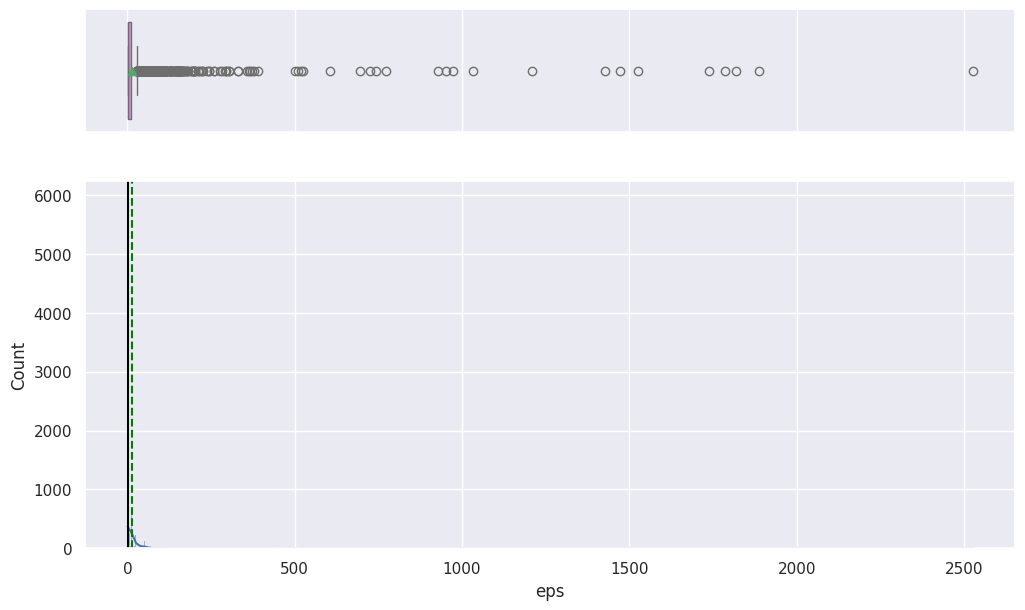


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,13.39
Median (Q2),2.00
Q1 (25th Percentile),1.00
Q3 (75th Percentile),12.00
IQR,11.00
Kurtosis,749.98
Skewness,24.16
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-15.50



Plotting distribution for: duration


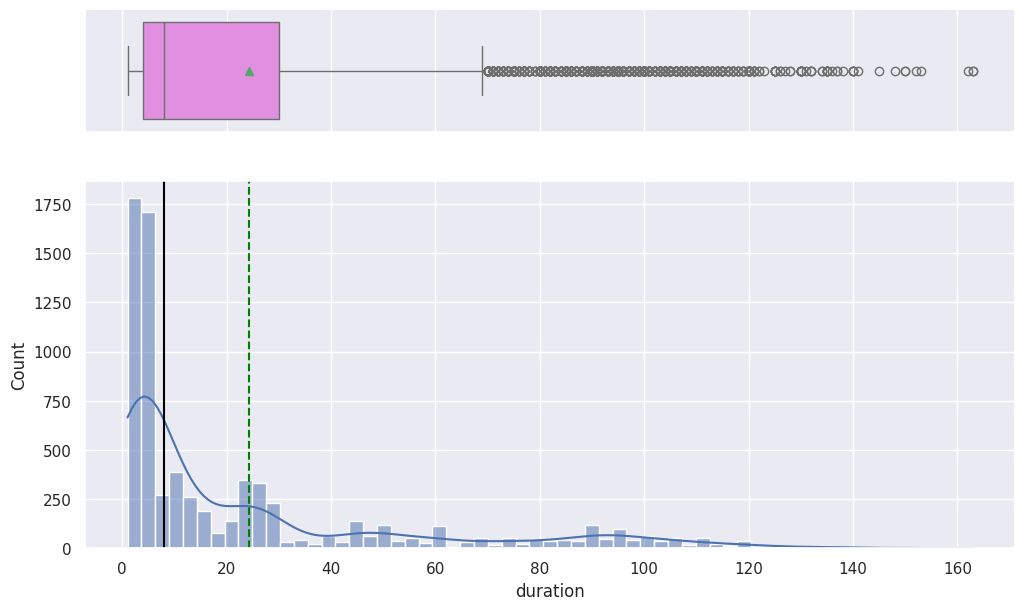


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,24.23
Median (Q2),8.00
Q1 (25th Percentile),4.00
Q3 (75th Percentile),30.00
IQR,26.00
Kurtosis,1.78
Skewness,1.66
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-35.00



Plotting distribution for: years_running


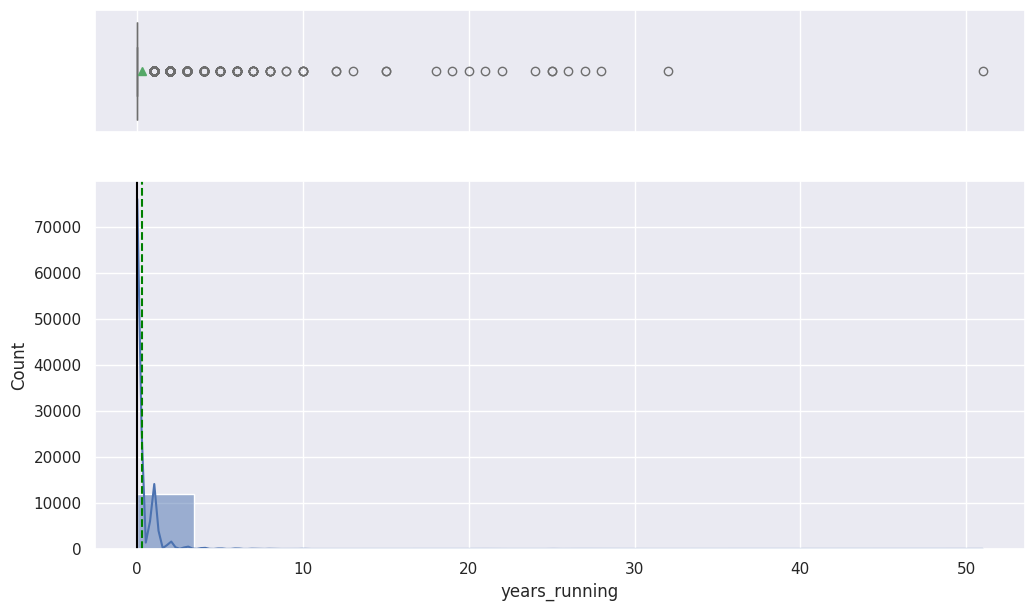


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.28
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,526.78
Skewness,18.08
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: studios_colab


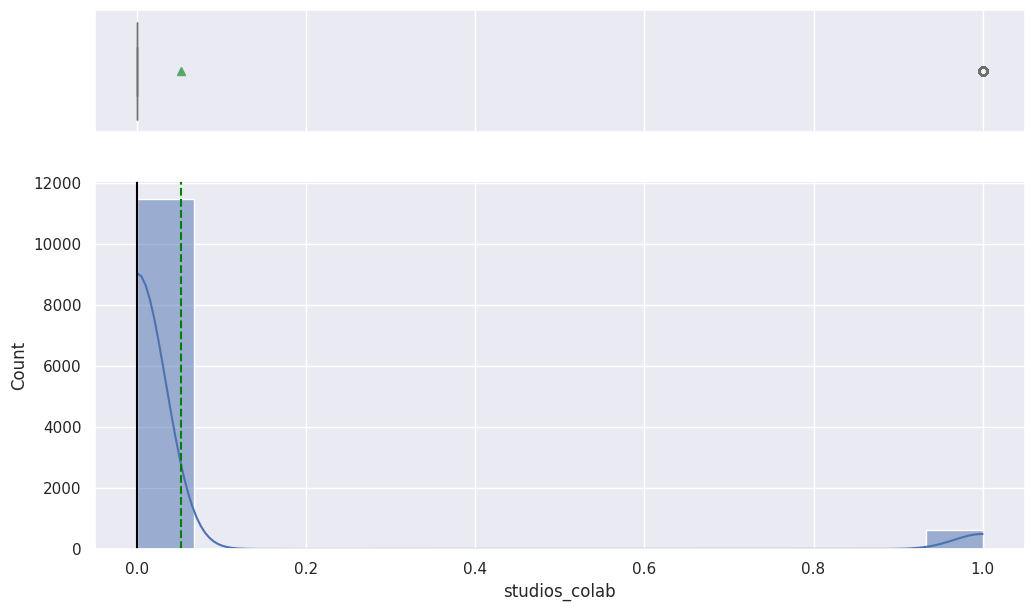


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.05
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,14.42
Skewness,4.05
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: contentWarn


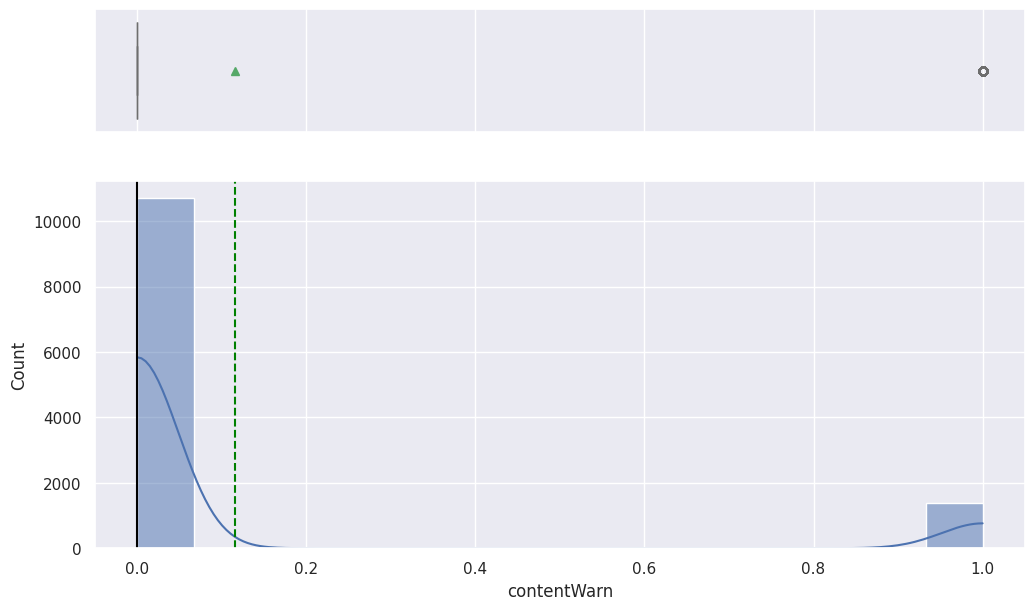


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.12
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,3.80
Skewness,2.41
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: watched


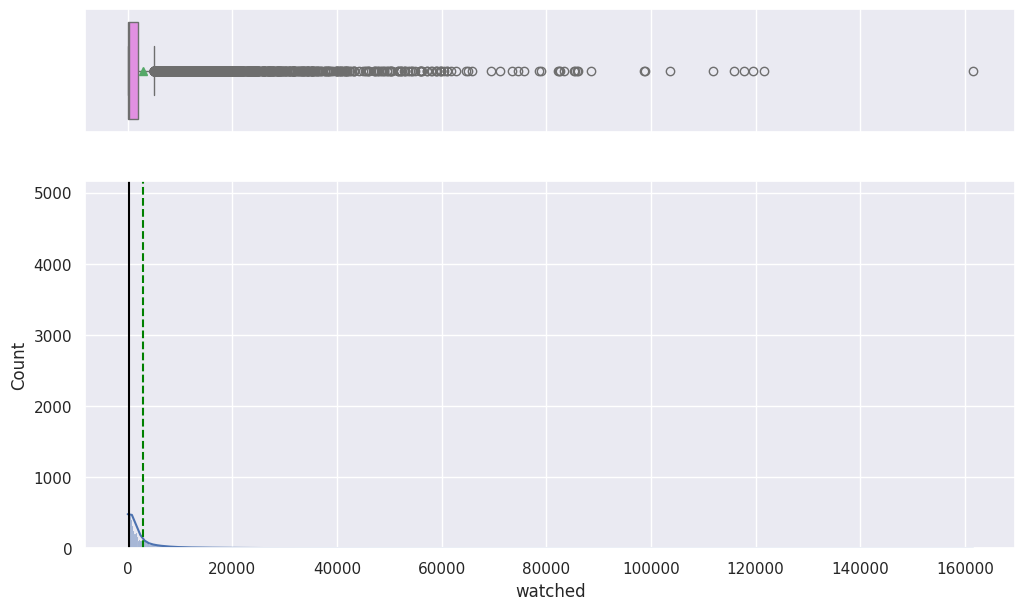


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,2862.61
Median (Q2),341.00
Q1 (25th Percentile),55.00
Q3 (75th Percentile),2026.00
IQR,1971.00
Kurtosis,66.23
Skewness,6.58
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-2901.50



Plotting distribution for: watching


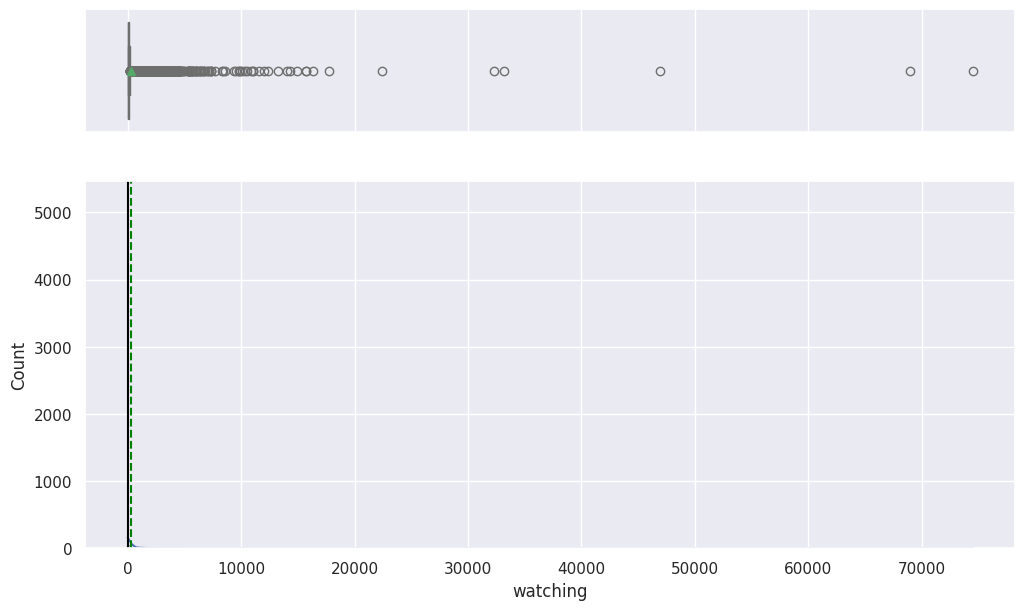


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,256.33
Median (Q2),14.00
Q1 (25th Percentile),2.00
Q3 (75th Percentile),100.00
IQR,98.00
Kurtosis,1376.85
Skewness,30.64
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-145.00



Plotting distribution for: wantWatch


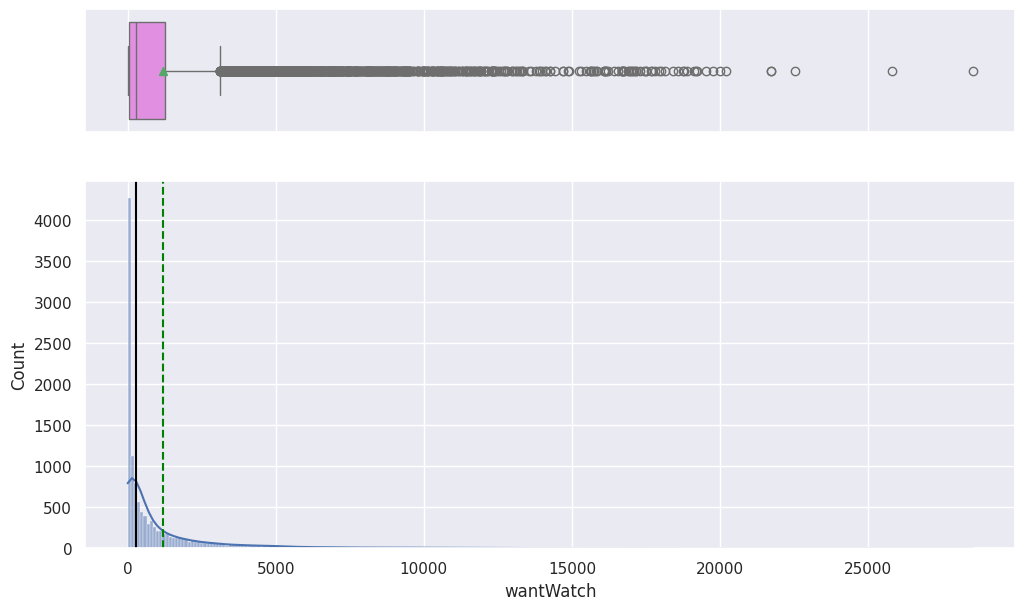


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,1203.68
Median (Q2),296.00
Q1 (25th Percentile),49.00
Q3 (75th Percentile),1275.00
IQR,1226.00
Kurtosis,19.99
Skewness,3.85
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-1790.00



Plotting distribution for: dropped


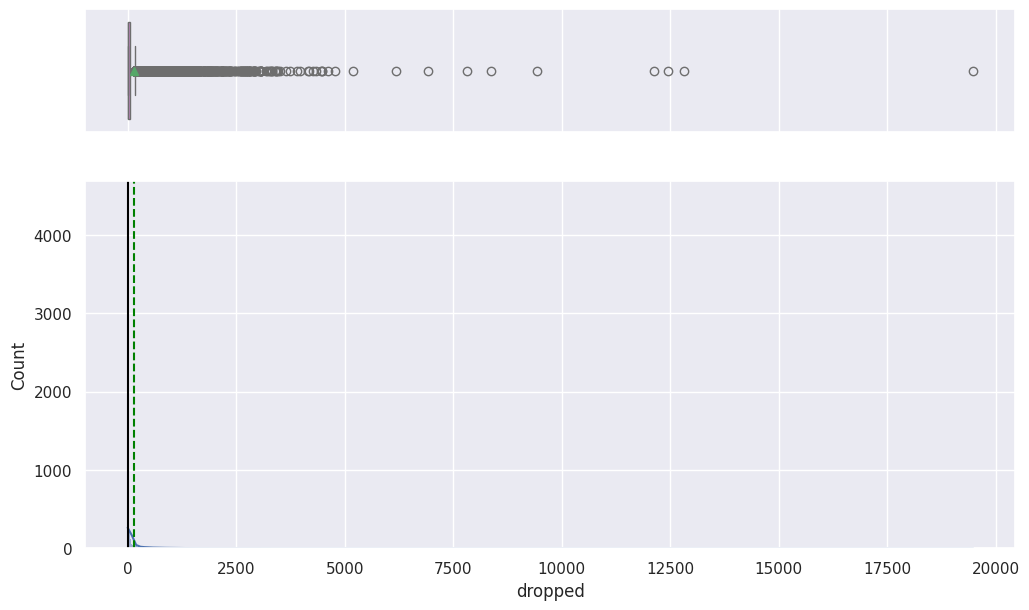


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,151.57
Median (Q2),12.00
Q1 (25th Percentile),3.00
Q3 (75th Percentile),65.00
IQR,62.00
Kurtosis,327.02
Skewness,12.82
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-90.00



Plotting distribution for: rating


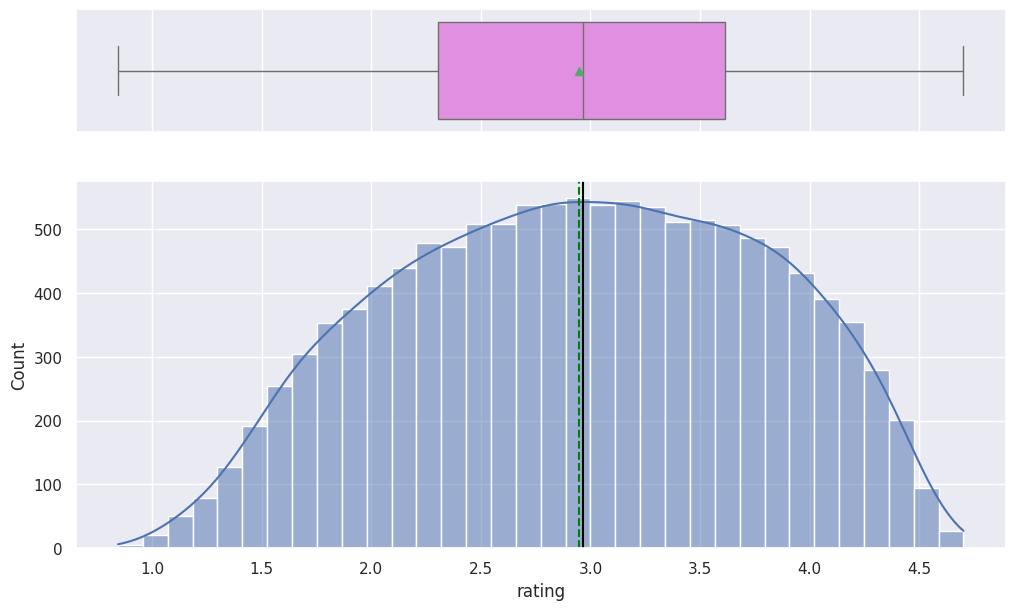


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,2.95
Median (Q2),2.96
Q1 (25th Percentile),2.30
Q3 (75th Percentile),3.62
IQR,1.31
Kurtosis,-0.89
Skewness,-0.10
Tail Distribution,Approximately symmetric
Lower Boundary (Outliers),0.34



Plotting distribution for: votes


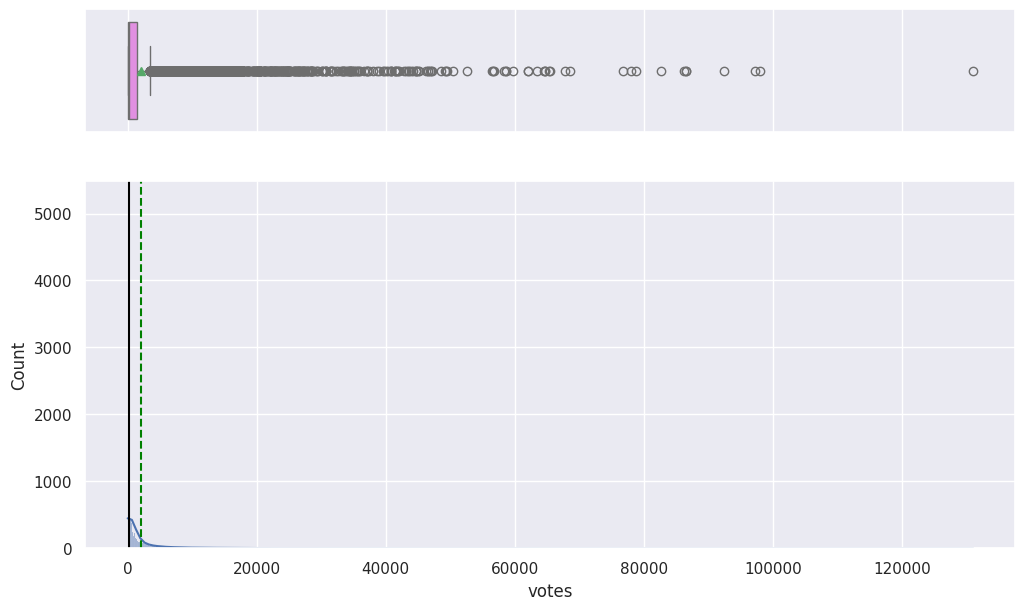


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,2088.12
Median (Q2),219.00
Q1 (25th Percentile),34.00
Q3 (75th Percentile),1414.00
IQR,1380.00
Kurtosis,78.57
Skewness,7.19
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-2036.00



Plotting distribution for: tag_Based_on_a_Manga


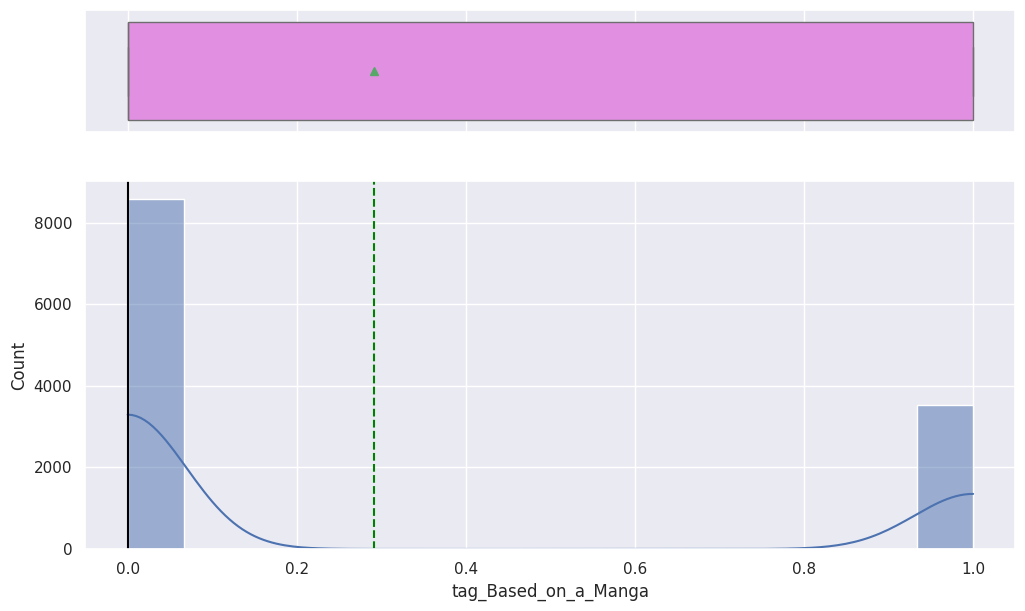


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.29
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),1.00
IQR,1.00
Kurtosis,-1.15
Skewness,0.92
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-1.50



Plotting distribution for: tag_Comedy


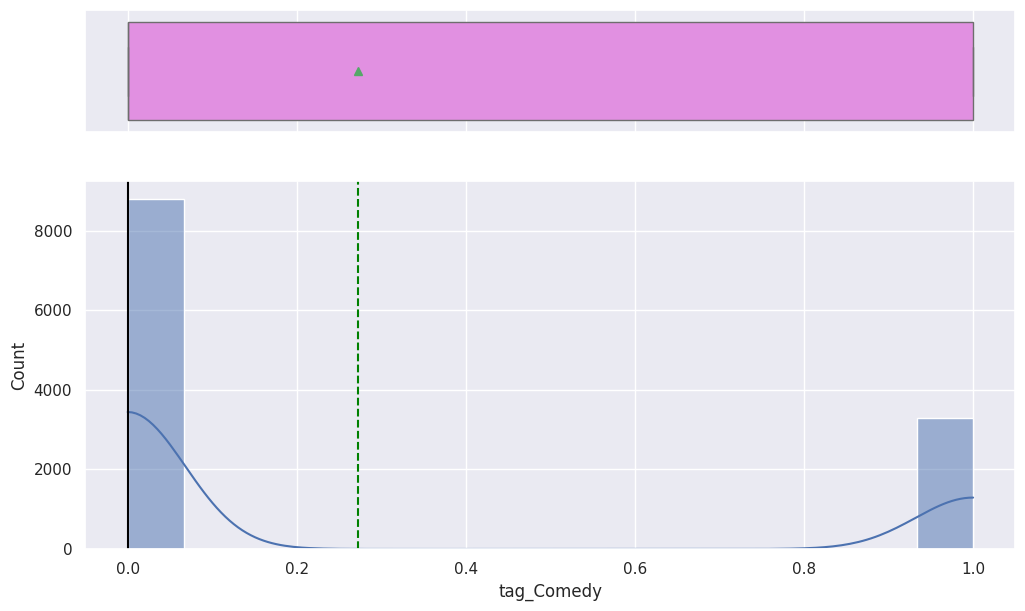


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.27
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),1.00
IQR,1.00
Kurtosis,-0.96
Skewness,1.02
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),-1.50



Plotting distribution for: tag_Action


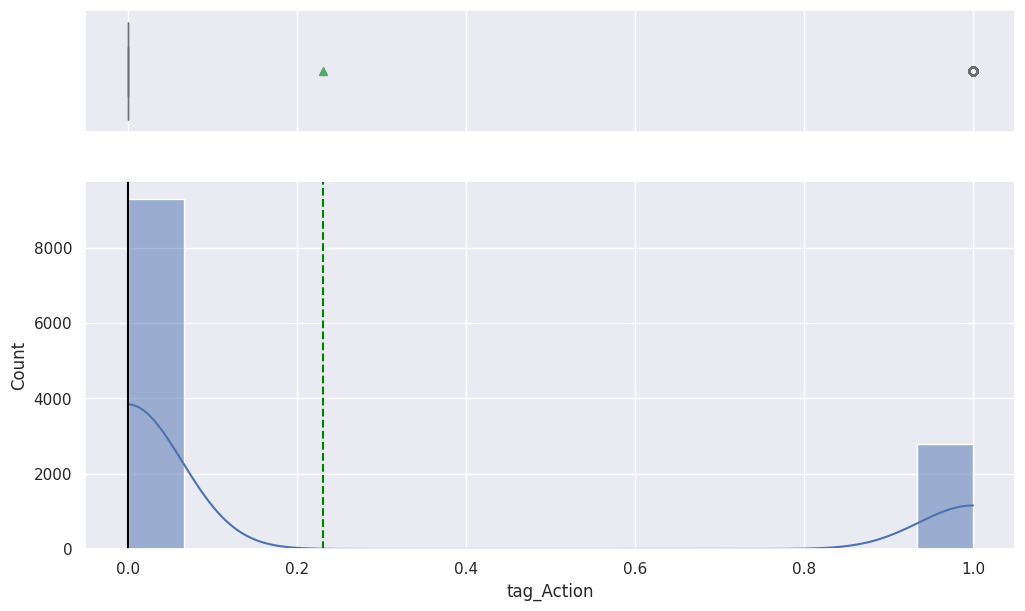


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.23
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,-0.37
Skewness,1.28
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Fantasy


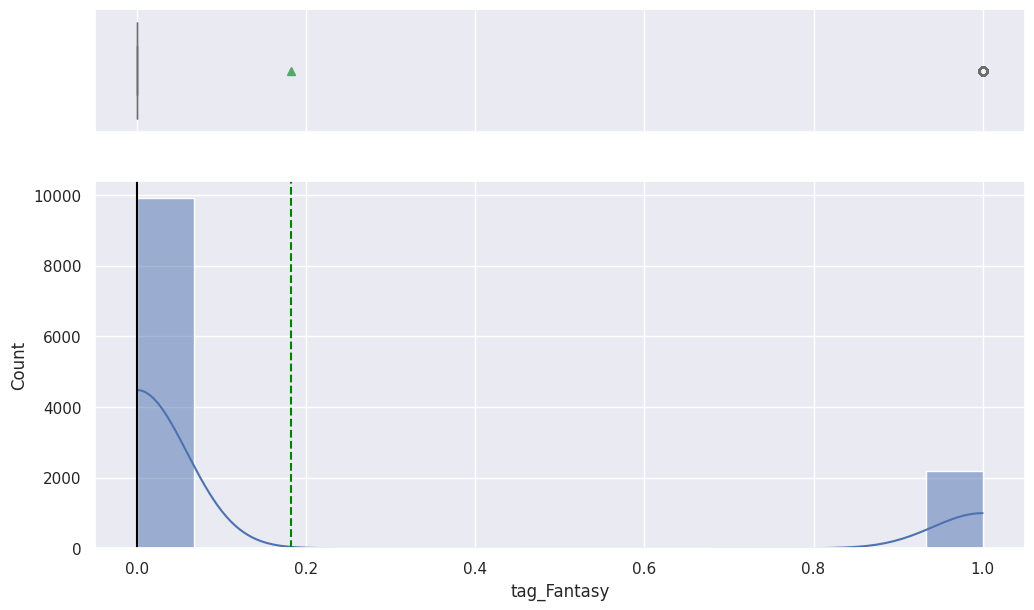


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.18
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,0.73
Skewness,1.65
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Sci_Fi


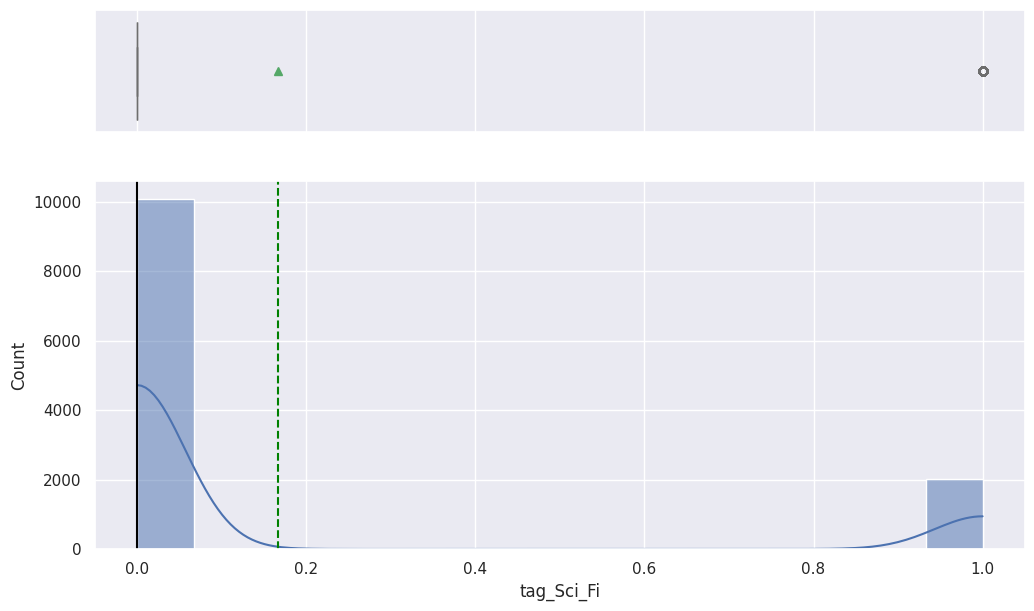


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.17
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,1.21
Skewness,1.79
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Shounen


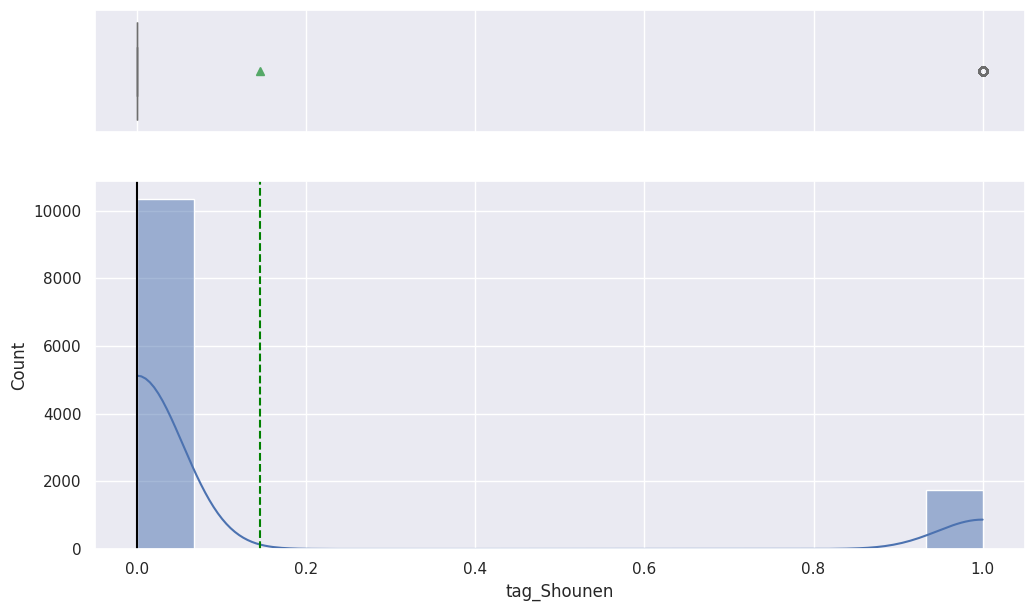


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.14
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,2.07
Skewness,2.02
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Original_Work


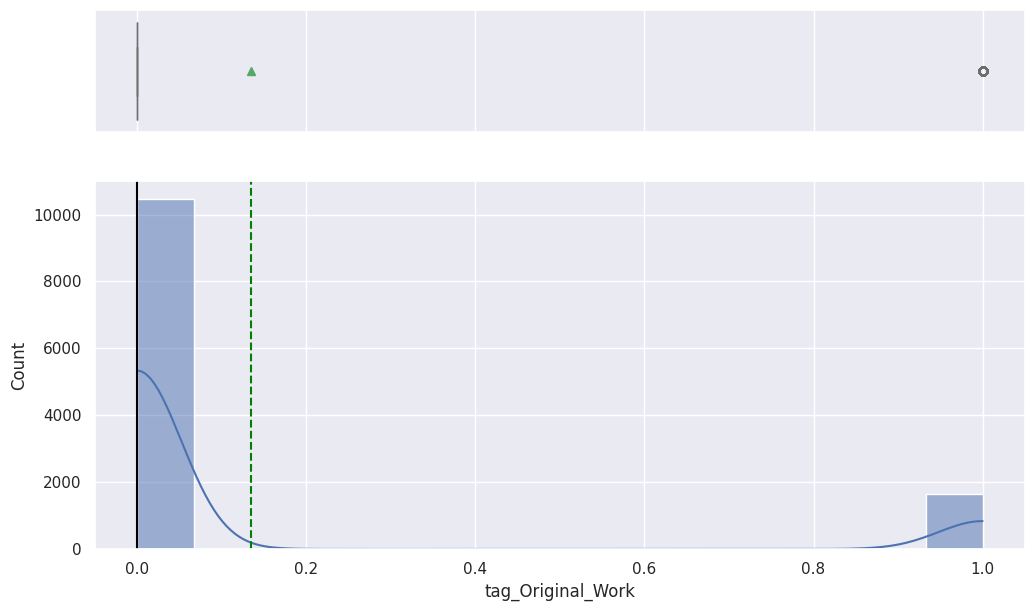


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.14
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,2.55
Skewness,2.13
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Non_Human_Protagonists


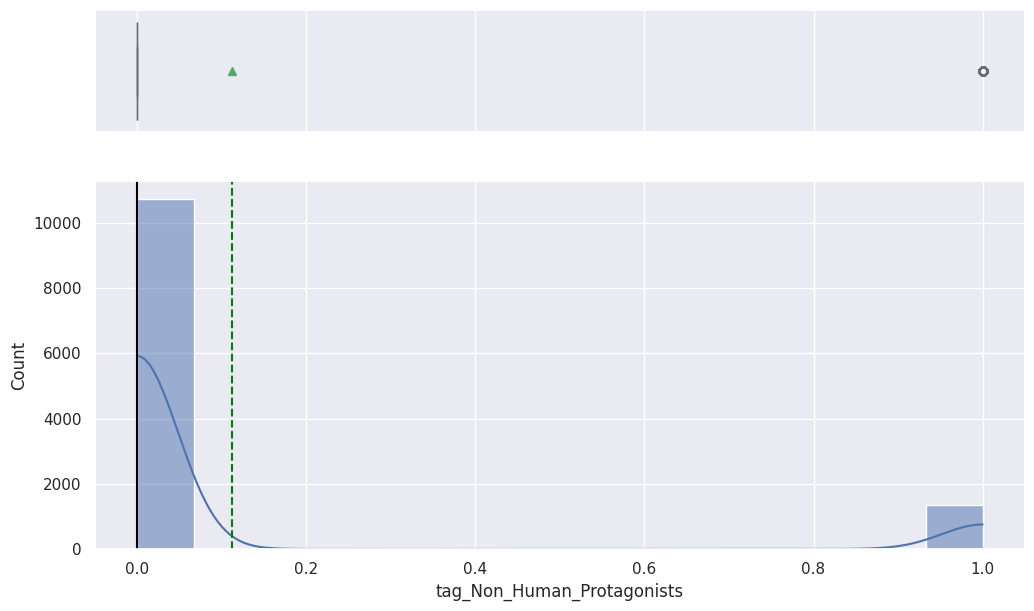


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.11
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,4.02
Skewness,2.45
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Drama


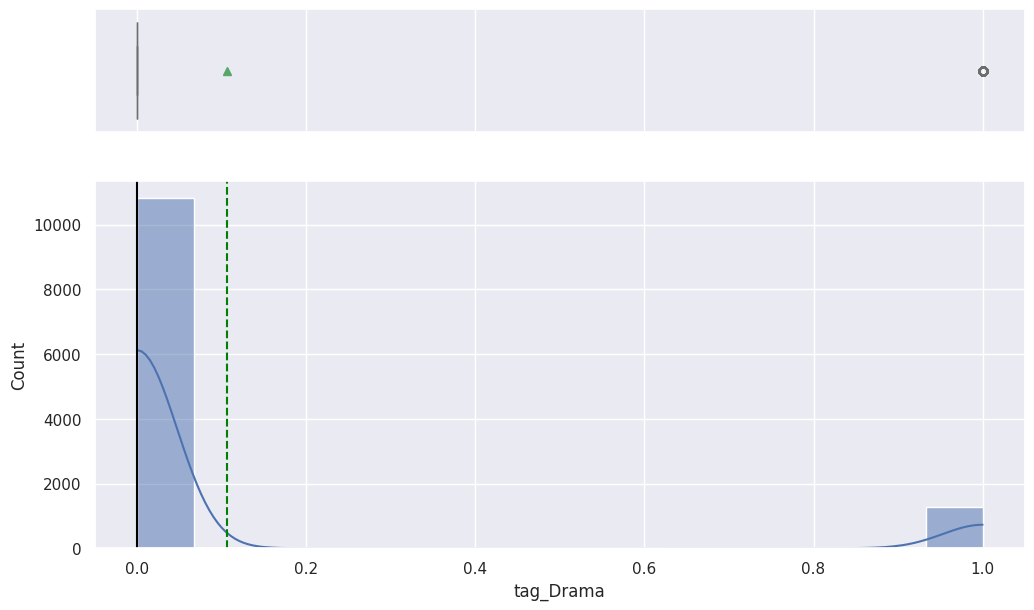


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.11
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,4.55
Skewness,2.56
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Adventure


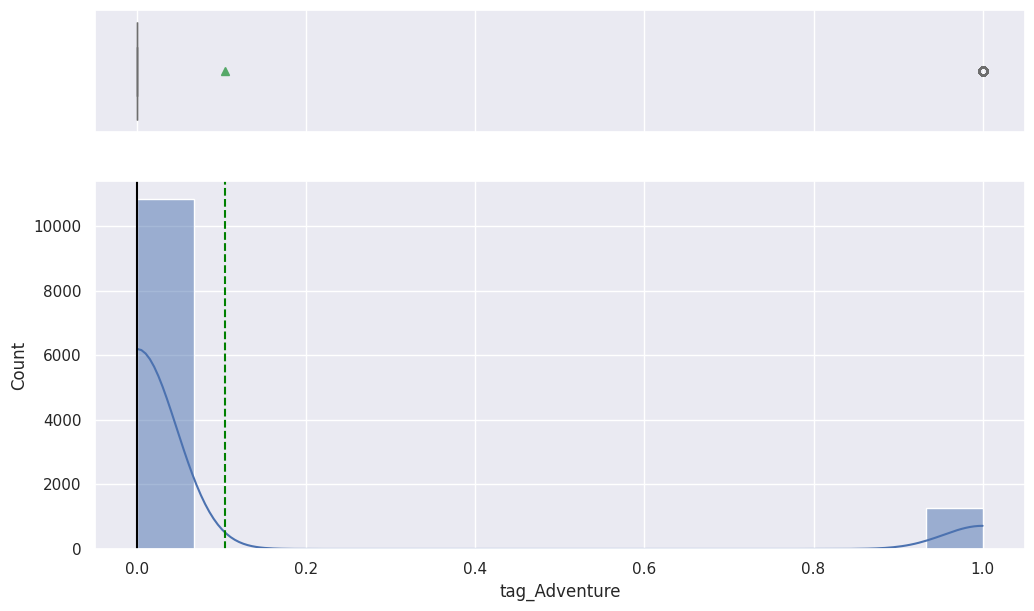


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.10
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,4.75
Skewness,2.60
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Family_Friendly


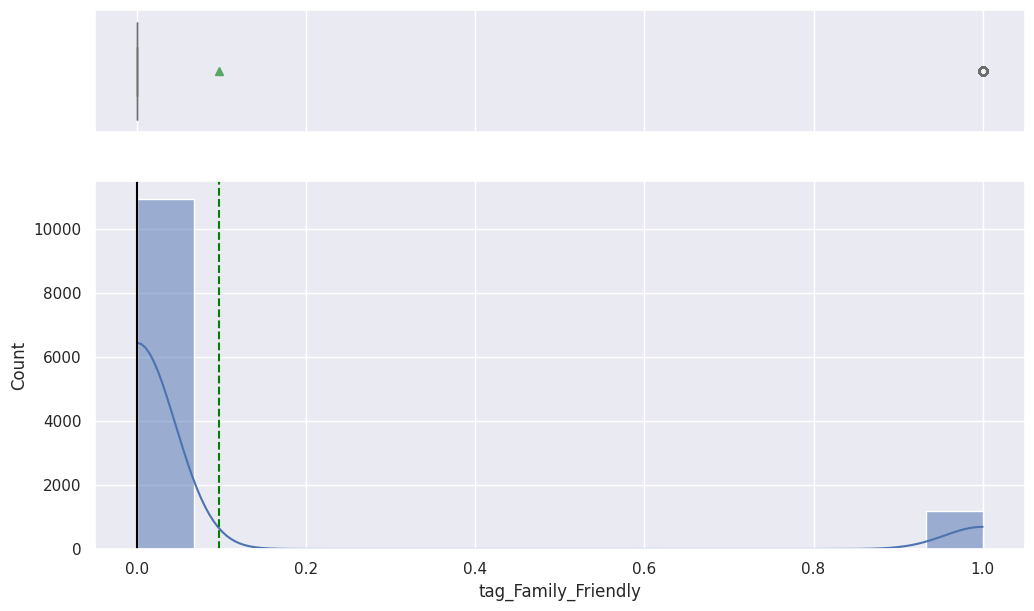


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.10
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,5.42
Skewness,2.72
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Short_Episodes


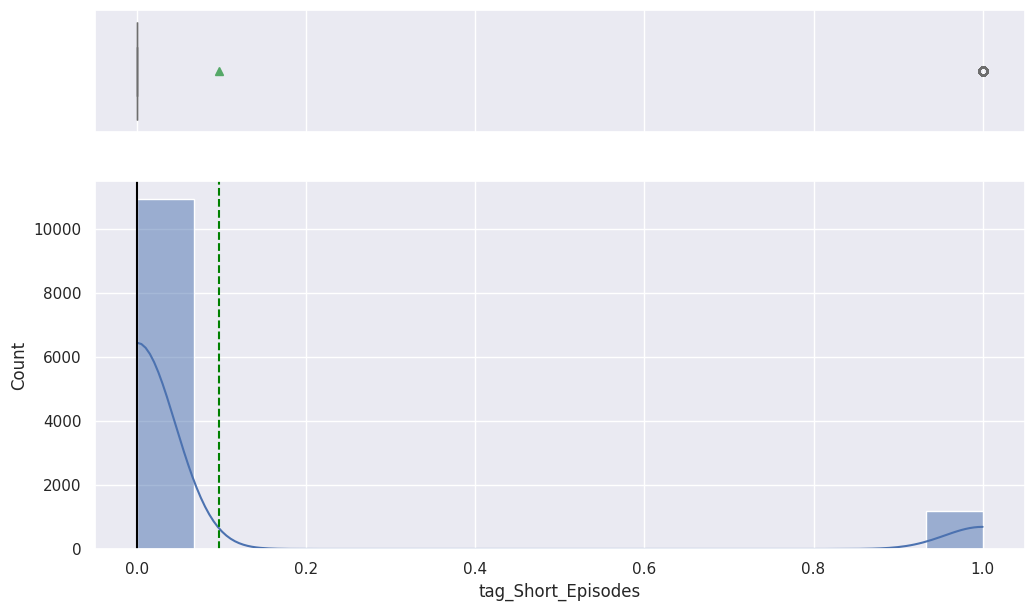


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.10
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,5.43
Skewness,2.72
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_School_Life


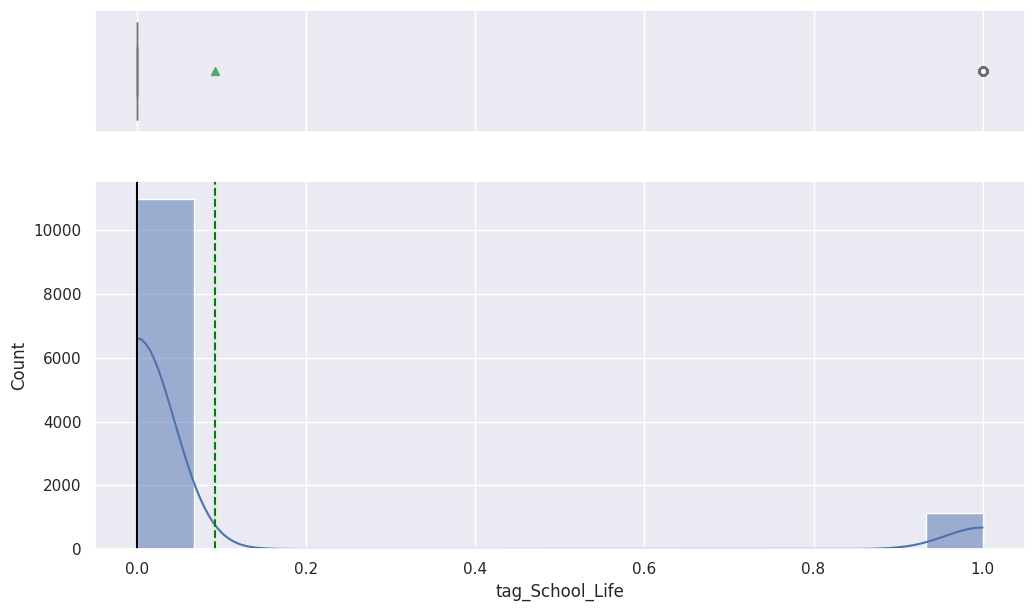


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.09
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,5.94
Skewness,2.82
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Romance


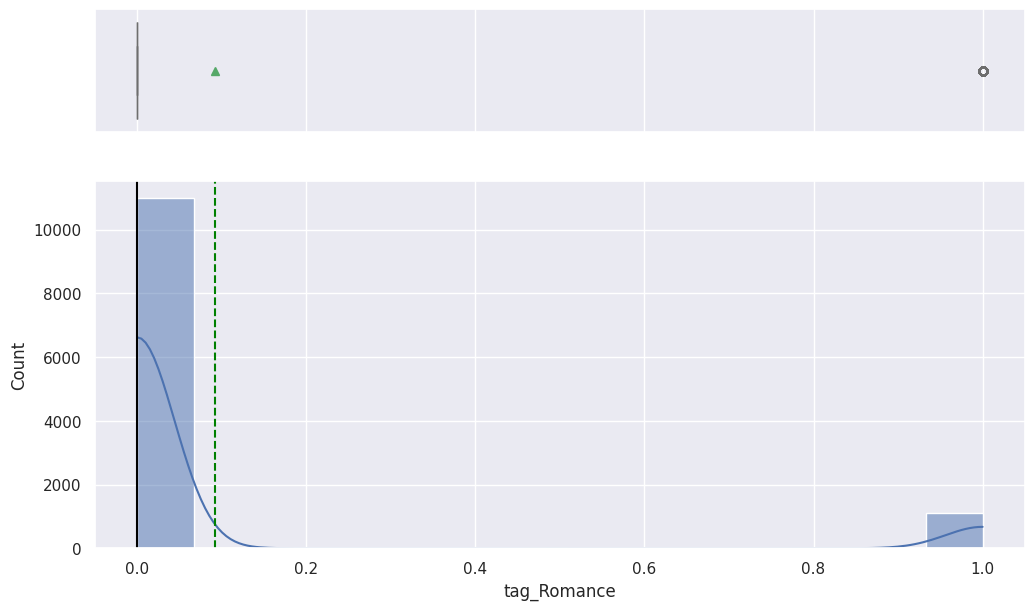


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.09
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,5.96
Skewness,2.82
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Shorts


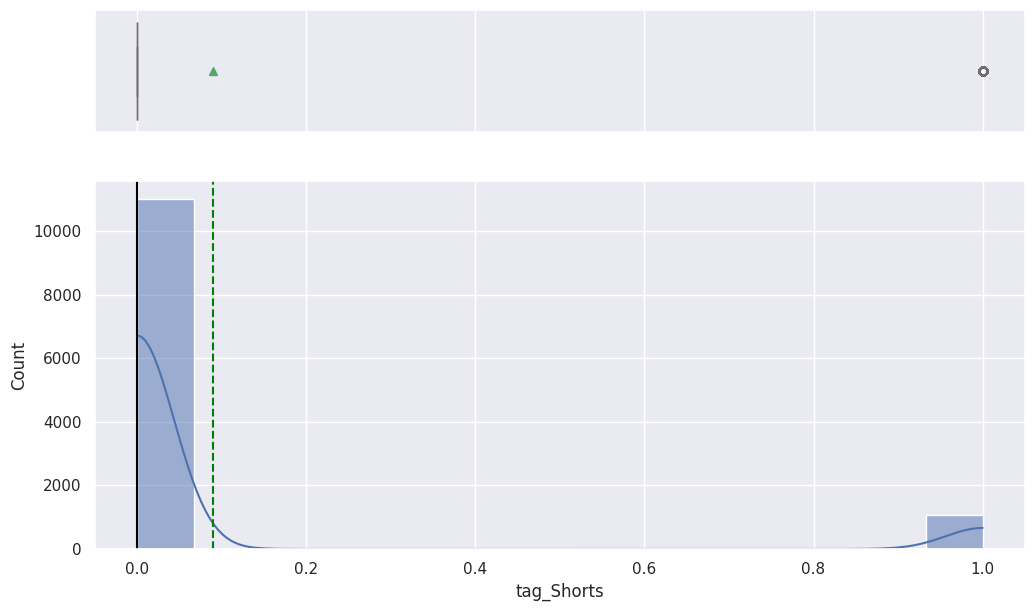


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.09
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,6.25
Skewness,2.87
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Slice_of_Life


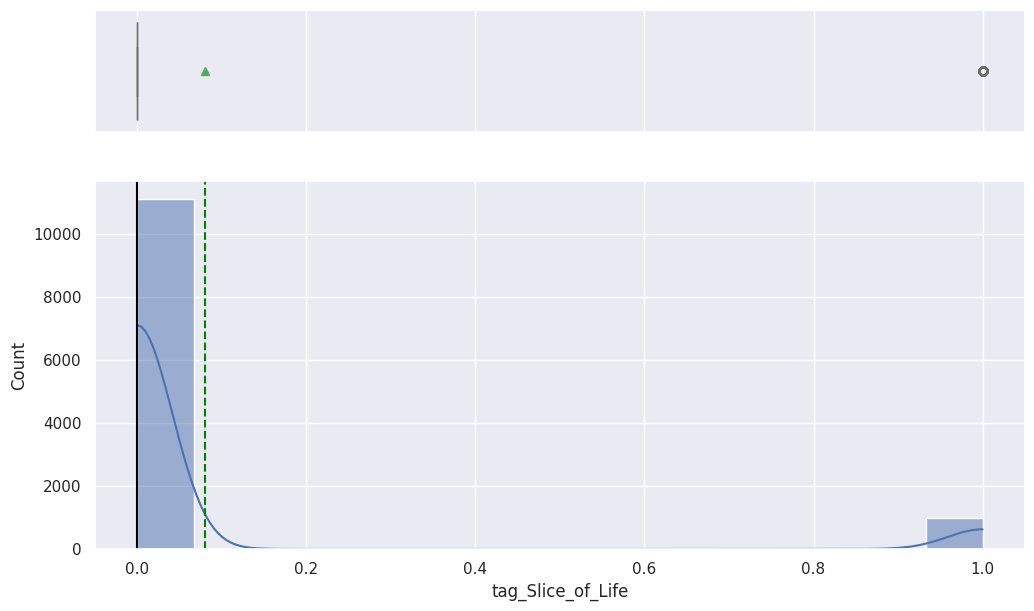


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.08
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,7.46
Skewness,3.08
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Seinen


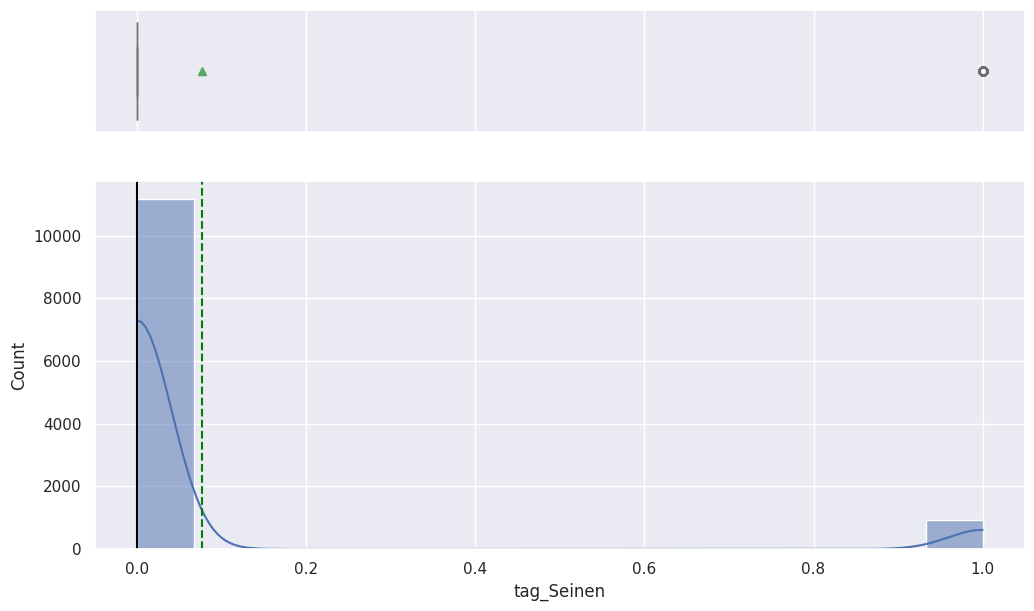


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.08
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,8.06
Skewness,3.17
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Supernatural


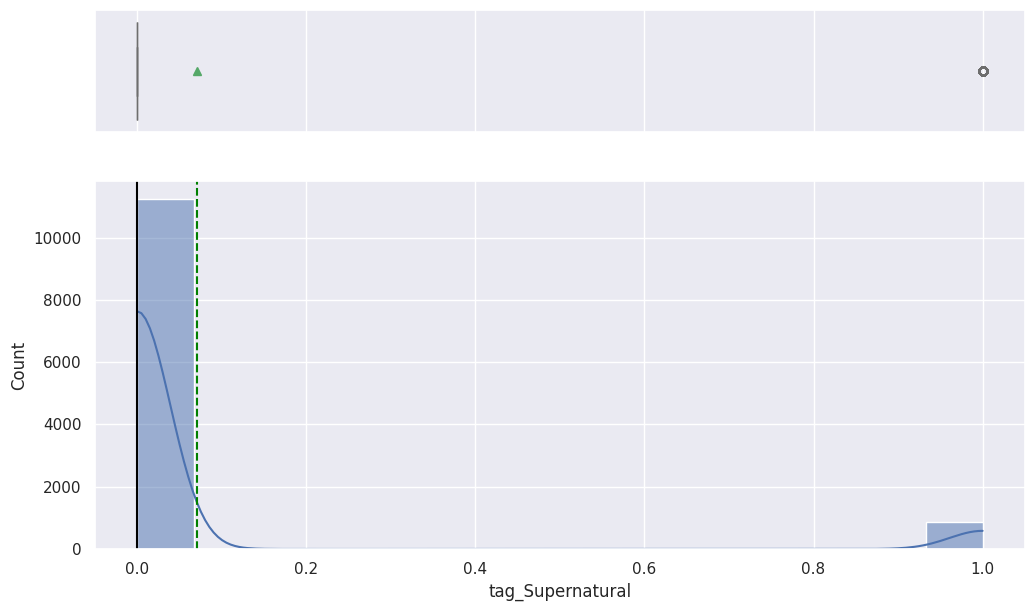


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.07
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,9.18
Skewness,3.34
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Magic


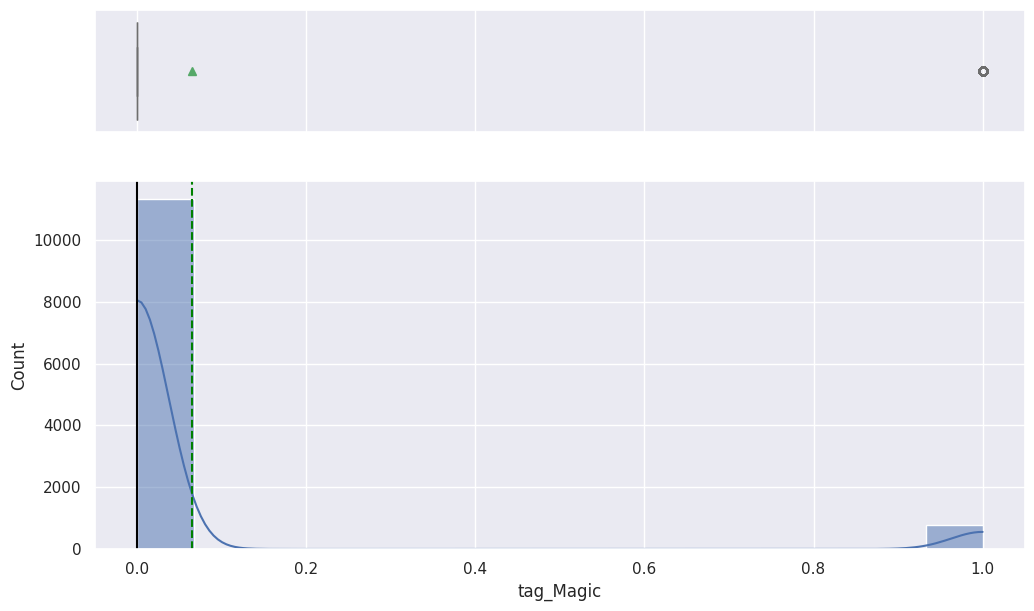


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.06
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,10.63
Skewness,3.55
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Animal_Protagonists


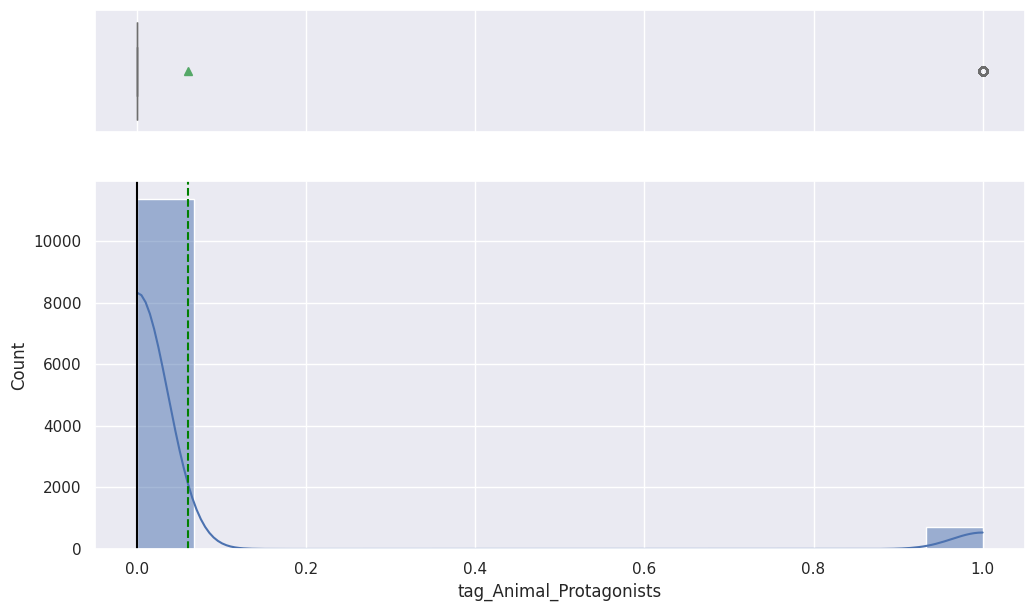


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.06
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,11.65
Skewness,3.69
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Ecchi


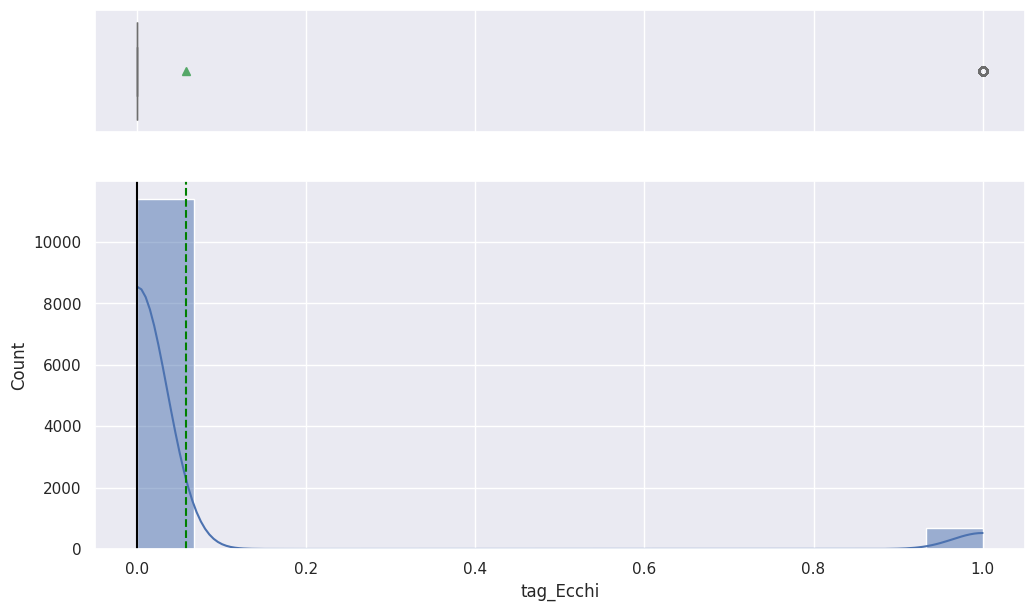


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.06
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,12.48
Skewness,3.80
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Mecha


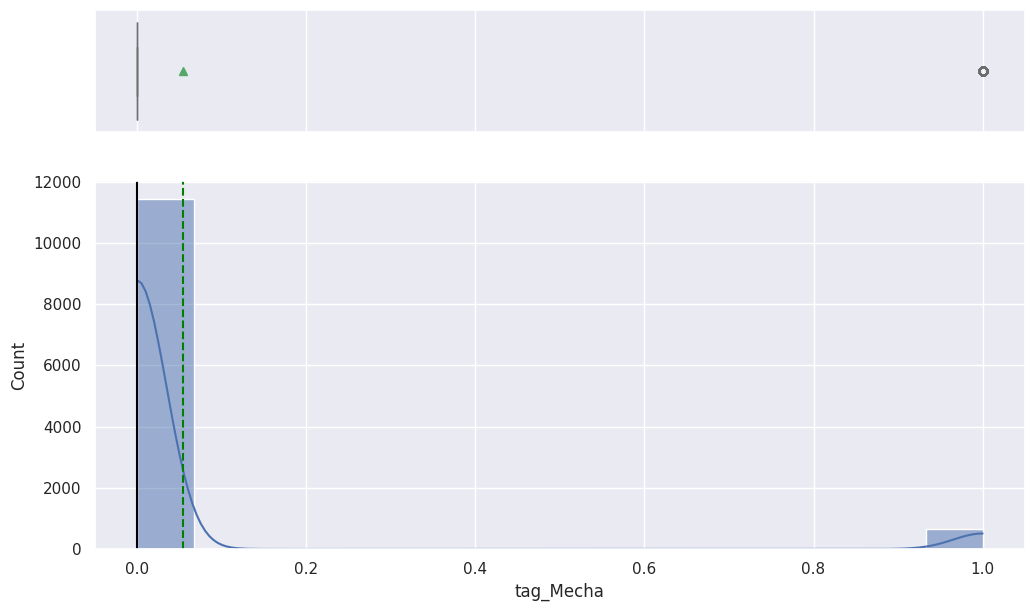


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.05
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,13.40
Skewness,3.92
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Based_on_a_Light_Novel


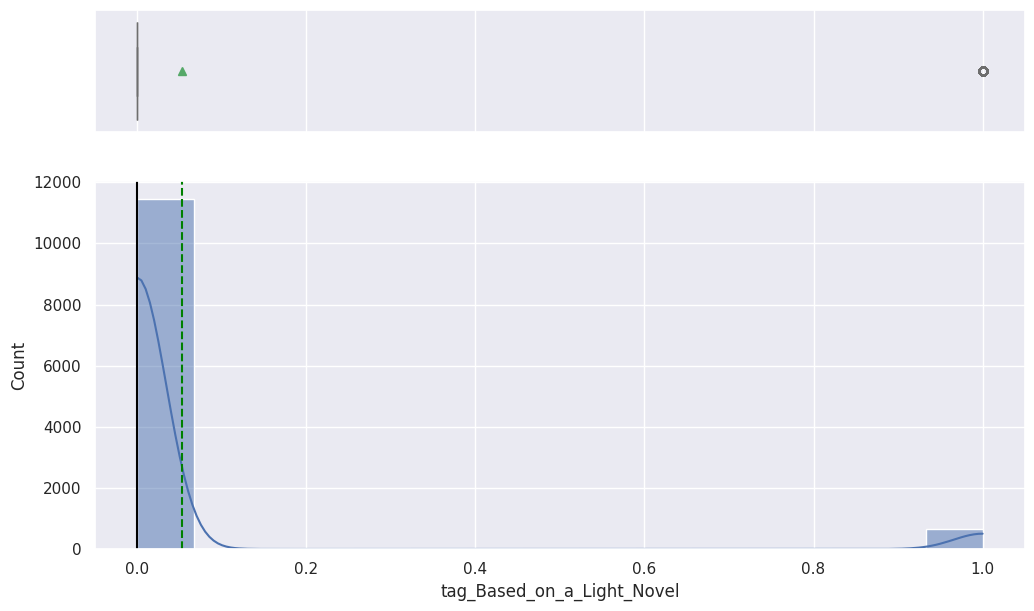


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.05
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,13.79
Skewness,3.97
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_CG_Animation


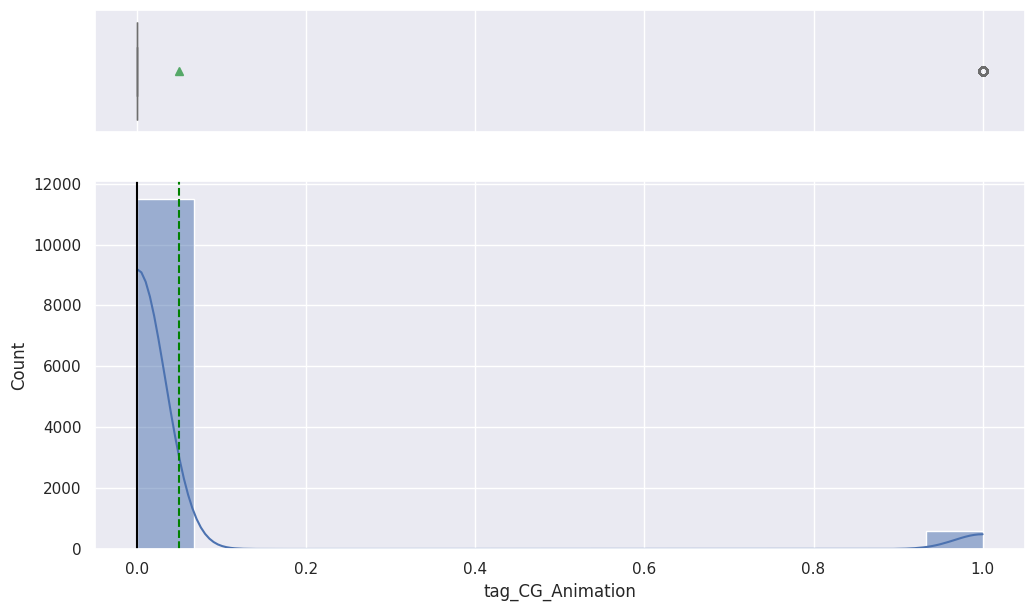


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.05
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,15.03
Skewness,4.13
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Superpowers


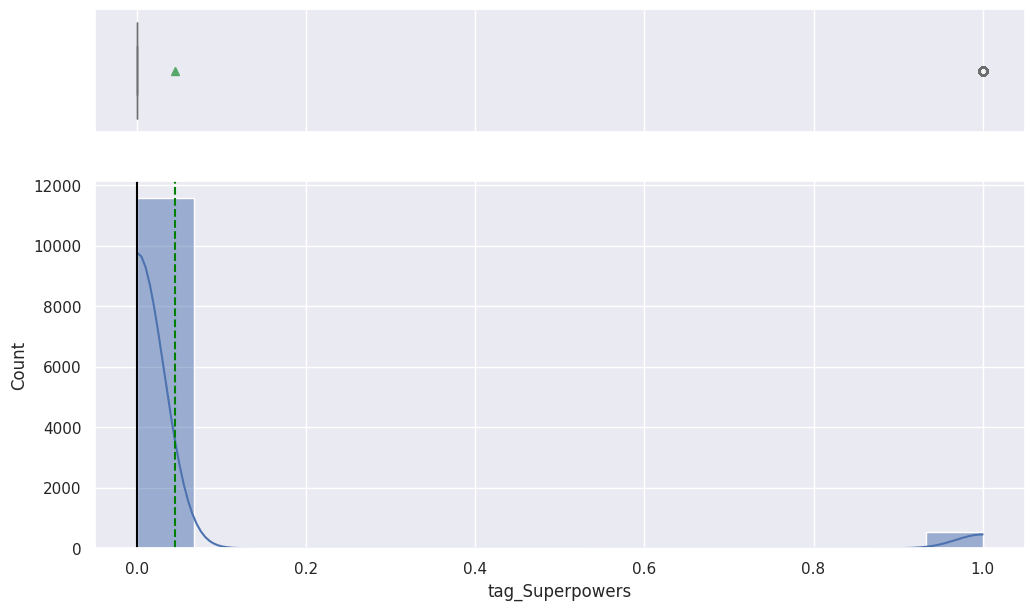


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.04
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,17.46
Skewness,4.41
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_Others


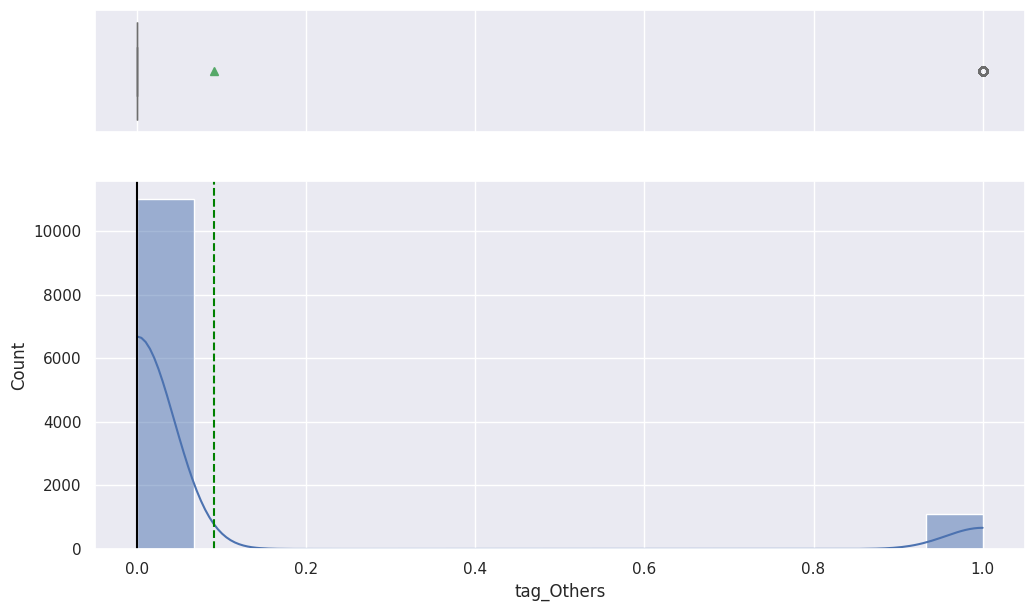


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.09
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,6.13
Skewness,2.85
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00



Plotting distribution for: tag_missing


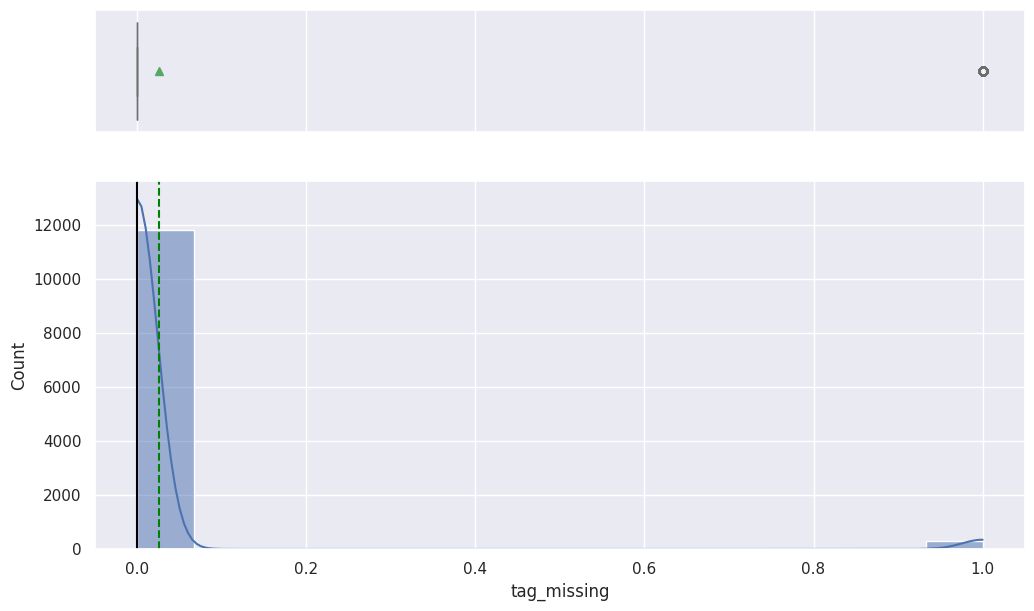


 STATISTICAL SUMMARY TABLE 


,Value
Metric,
Mean,0.03
Median (Q2),0.00
Q1 (25th Percentile),0.00
Q3 (75th Percentile),0.00
IQR,0.00
Kurtosis,33.70
Skewness,5.97
Tail Distribution,Right-skewed (Long right tail)
Lower Boundary (Outliers),0.00


In [179]:
# Identify all numerical columns in the dataset
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Loop through each numerical variable and plot its combined boxplot and histogram
for col in numeric_cols:
    print(f"\nPlotting distribution for: {col}")
    histogram_boxplot(df, feature=col, figsize=(12, 7), kde=True)

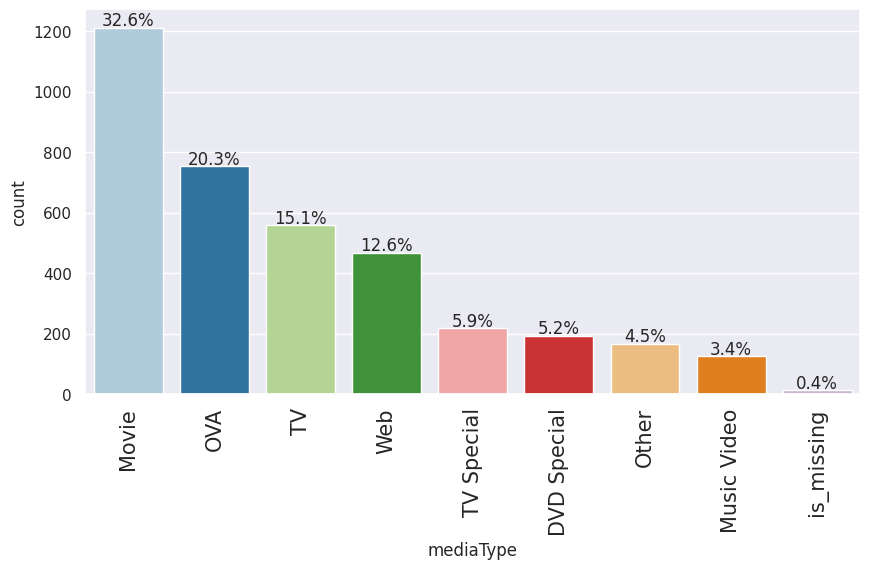

In [180]:
labeled_barplot(data, "mediaType", perc=True)

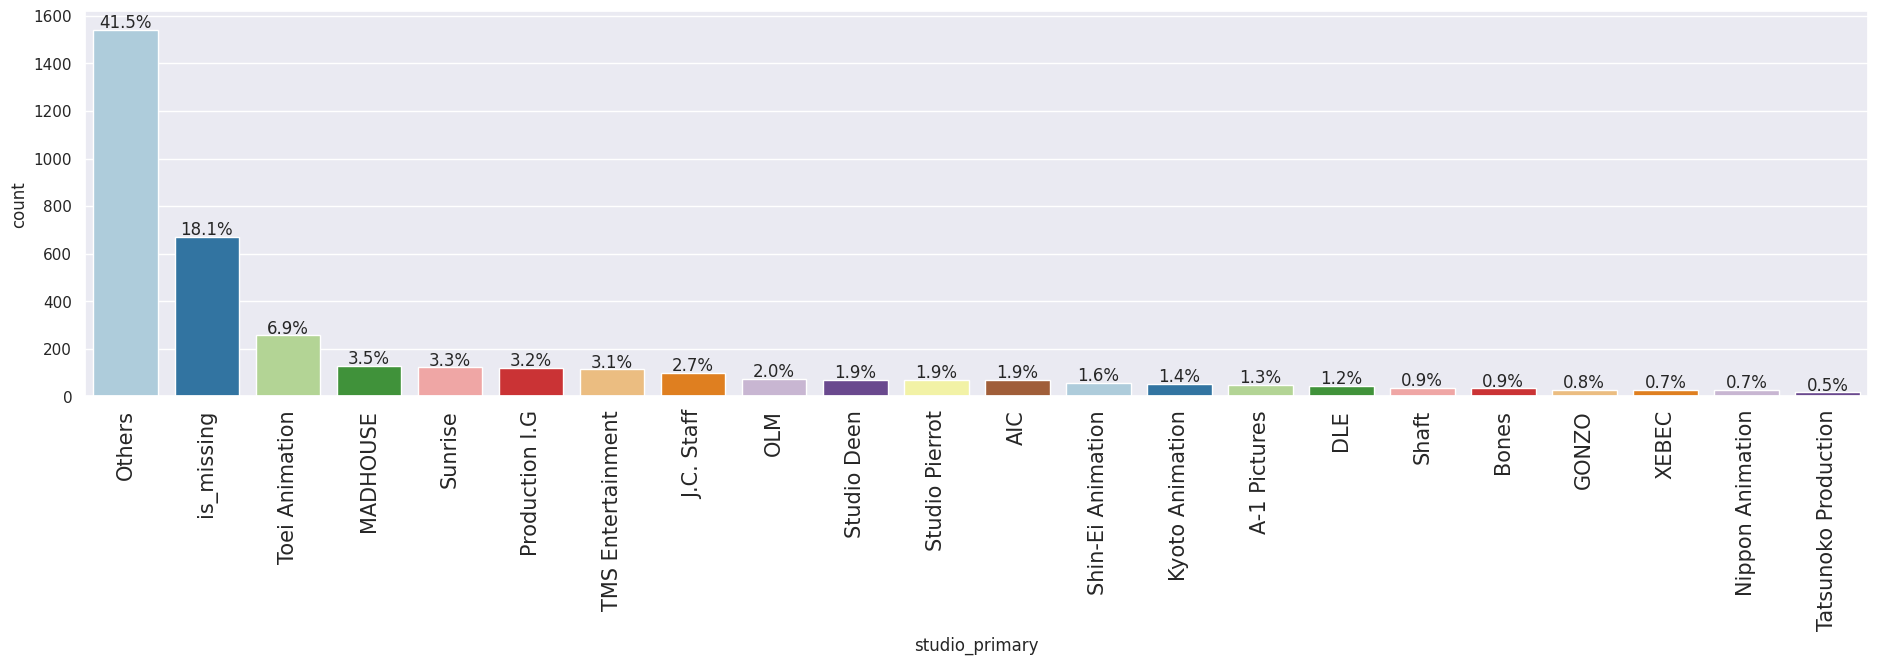

In [181]:
labeled_barplot(data, "studio_primary", perc=True)

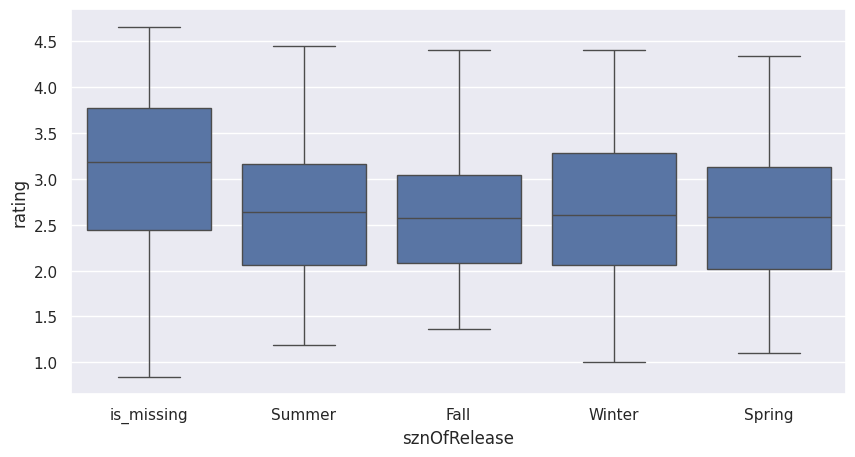

In [182]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="sznOfRelease", y="rating", data=data)
plt.show()

Project-2:

Anime ratings have a similar distribution across all the seasons of release.
Summary of EDA
Data Description:

The target variable (rating) is of float type.
title, description, mediaType, sznOfRelease, and studio_primary are of object type.
ongoing column is of bool type.
All other columns are numeric in nature.
The title and description columns are dropped for modeling as they are highly textual in nature.
There are no duplicate values in the data.
There are missing values in the data. The rows with missing data have been dropped.
Observations from EDA:

rating: The anime ratings are close to normally distributed, with a mean rating of 2.74. The rating increases with an increase in the number of people who have watched or want to watch the anime.
eps: The distribution is heavily right-skewed as there are many anime movies in the data (at least 50%), and they are considered to be of only one episode as per data description. The number of episodes increases as the anime runs for more years.
duration: The distribution is right-skewed with a median anime runtime of less than 10 minutes. With the increase in rating, the duration increases.
years_running: The distribution is heavily right-skewed, and at least 75% of the anime have run for less than 1 year.
watched: The distribution is heavily right-skewed, and most of the anime have less than 500 viewers. This attribute is highly correlated with the wantWatch and votes attributes.
watching: The distribution is heavily right-skewed and highly correlated with the dropped attribute.
wantWatch: The distribution is heavily right-skewed with a median value of 132 potential watchers.
dropped: The distribution is heavily right-skewed with a drop of 25 viewers on average.
votes: The distribution is heavily right-skewed, and few shows have more than 5000 votes.
mediaType: 23% of the anime are published for TV, 17% as music videos, and 14% as web series. Anime available as TV series, web series, or music videos have a lower rating in general
ongoing: Less than 1% of the anime in the data are ongoing.
sznOfRelease: The season of release is missing for nearly 90% of the anime in the data, and is spread out almost evenly across all seasons when available. Anime ratings have a similar distribution across all the seasons of release.
studio_primary: Nearly 40% of the anime in the data are produced by studios not listed in the data. Toei Animation is the most common studio among the available studio names. In general, the ratings are low for anime produced by DLE studios and studios other than the ones listed in the data.
studios_colab: More than 95% of the anime in the data do not involve collaboration between studios.
contentWarn: Less than 10% of the anime in the data have an associated content warning.
tag_<tag/genre>: There are 1747 anime that are based on manga, 1920 of the Comedy genre, 1238 of the Action genre, 1079 anime of the Romance genre, and more.
Note: The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the appendix section.
Model Building
Define independent and dependent variables

In [183]:
X = data.drop(["rating"], axis=1)
y = data["rating"]

In [184]:
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=True,
)
X.head()

,eps,duration,ongoing,years_running,studios_colab,contentWarn,watched,watching,wantWatch,dropped,votes,tag_Based_on_a_Manga,tag_Comedy,tag_Action,tag_Fantasy,tag_Sci_Fi,tag_Shounen,tag_Original_Work,tag_Non_Human_Protagonists,tag_Drama,tag_Adventure,tag_Family_Friendly,tag_Short_Episodes,tag_School_Life,tag_Romance,tag_Shorts,tag_Slice_of_Life,tag_Seinen,tag_Supernatural,tag_Magic,tag_Animal_Protagonists,tag_Ecchi,tag_Mecha,tag_Based_on_a_Light_Novel,tag_CG_Animation,tag_Superpowers,tag_Others,tag_missing,mediaType_Movie,mediaType_Music Video,mediaType_OVA,mediaType_Other,mediaType_TV,mediaType_TV Special,mediaType_Web,mediaType_is_missing,sznOfRelease_Spring,sznOfRelease_Summer,sznOfRelease_Winter,sznOfRelease_is_missing,studio_primary_AIC,studio_primary_Bones,studio_primary_DLE,studio_primary_GONZO,studio_primary_J.C. Staff,studio_primary_Kyoto Animation,studio_primary_MADHOUSE,studio_primary_Nippon Animation,studio_primary_OLM,studio_primary_Others,studio_primary_Production I.G,studio_primary_Shaft,studio_primary_Shin-Ei Animation,studio_primary_Studio Deen,studio_primary_Studio Pierrot,studio_primary_Sunrise,studio_primary_TMS Entertainment,studio_primary_Tatsunoko Production,studio_primary_Toei Animation,studio_primary_XEBEC,studio_primary_is_missing
1,1,107.0,False,0,0,0,58831.0,1453,21733,124,43960,0,0,0,0,0,0,1,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
2,1,130.0,False,0,0,1,45892.0,946,17148,132,33752,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
8,1,111.0,False,0,0,0,8454.0,280,6624,150,6254,1,1,1,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
27,1,125.0,False,0,0,0,115949.0,589,12388,161,82752,0,0,0,1,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
31,1,117.0,False,0,0,0,35896.0,538,15651,130,26465,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False


In [185]:
X.shape

(3712, 71)

In [186]:
# splitting the data in 70:30 ratio for train to test data

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [187]:
print("Number of rows in train data =", x_train.shape[0])
print("Number of rows in test data =", x_test.shape[0])

Number of rows in train data = 2598
Number of rows in test data = 1114


In [188]:
lin_reg_model = LinearRegression()
lin_reg_model.fit(x_train, y_train)

LinearRegression()

Model performance check
We will be using metric functions defined in sklearn for RMSE, MAE, and R2
.

We will define functions to calculate adjusted R2
 and MAPE.

The mean absolute percentage error (MAPE) measures the accuracy of predictions as a percentage, and can be calculated as the average absolute percent error for each predicted value minus actual values divided by actual values. It works best if there are no extreme values in the data and none of the actual values are 0.
We will create a function that will print out all the above metrics in one go.

In [189]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mape_score(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

In [190]:
# Checking model performance on train set
print("Training Performance\n")
lin_reg_model_train_perf = model_performance_regression(lin_reg_model, x_train, y_train)
lin_reg_model_train_perf

Training Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.567087,0.455491,0.534514,0.52143,17.654509


In [191]:
# Checking model performance on test set
print("Test Performance\n")
lin_reg_model_test_perf = model_performance_regression(lin_reg_model, x_test, y_test)
lin_reg_model_test_perf

Test Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.592959,0.476744,0.492206,0.457606,18.213034


Observations

The train and test R2
 are 0.522 and 0.516, indicating that the model explains 52.2% and 51.6% of the total variation in the train and test sets respectively. Also, both scores are comparable.

RMSE values on the train and test sets are also comparable.

This shows that the model is not overfitting.

MAE indicates that our current model is able to predict anime ratings within a mean error of 0.46

MAPE of 19.4 on the test data means that we are able to predict within 19.4% of the anime rating.

However, the overall performance is not so great.

Conclusions
We have been able to build a predictive model that can be used by Streamist to predict the rating of an anime with an R2
 of 0.52 on the training set.

Streamist can use this model to predict the anime ratings within a mean error of 0.46

From the analysis, we found that the duration of each episode, and whether or not an anime is ongoing are some of the factors which tend to increase the rating of an anime. And factors like content warnings tend to decrease the rating of an anime.

We can also explore improving the linear model by applying non-linear transformations to some of the attributes. This might help us better identify the patterns in the data to predict the anime ratings more accurately.

Additional: Forward Feature Selection using SequentialFeatureSelector
We will see how to select a subset of important features with forward feature selection using SequentialFeatureSelector.

Why should we do feature selection?

Reduces dimensionality
Discards deceptive features (Deceptive features appear to aid learning on the training set, but impair generalization)
Speeds training/testing
How does forward feature selection work?

It starts with an empty model and adds variables one by one.
In each forward step, you add the one variable that gives the highest improvement to your model.
We'll use forward feature selection on all the variables

In [192]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

reg = LinearRegression()

# Build step forward feature selection
sfs = SFS(
    reg,
    k_features=x_train.shape[1],
    forward=True,  # k_features denotes the number of features to select
    floating=False,
    scoring="r2",
    n_jobs=-1,  # n_jobs=-1 means all processor cores will be used
    verbose=2,
    cv=5,
)

# Perform SFFS
sfs = sfs.fit(x_train, y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  67 tasks      | elapsed:    4.3s
[Parallel(n_jobs=-1)]: Done  71 out of  71 | elapsed:    4.3s finished

[2026-10-23 09:42:27] Features: 1/71 -- score: 0.2569464425015187[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  70 out of  70 | elapsed:    1.2s finished

[2026-10-23 09:42:28] Features: 2/71 -- score: 0.34901268492854703[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  69 out of  69 | elapsed:    1.2s finished

[2026-10-23 09:42:29] Features: 3/71 -- score: 0.3781512849224713[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  68 out of  68 | elapsed:    1.2s finished

[2026-10-23 09:42:30] Features: 4/71 -- score: 0.39724804571489447[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Paralle

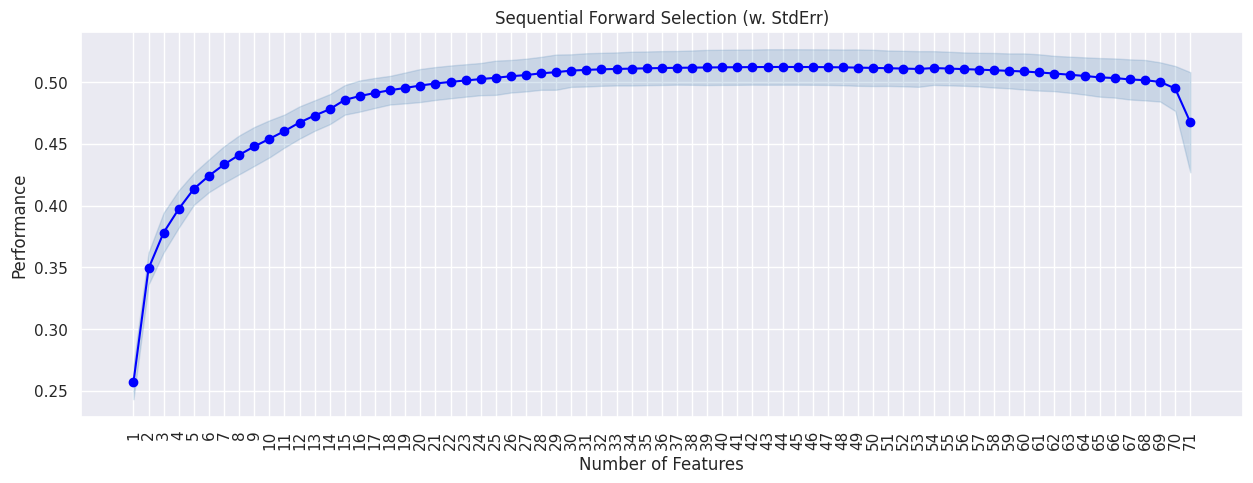

In [193]:
# to plot the performance with addition of each feature
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs

fig1 = plot_sfs(sfs.get_metric_dict(), kind="std_err", figsize=(15, 5))
plt.title("Sequential Forward Selection (w. StdErr)")
plt.xticks(rotation=90)
plt.show()

We can see that performance increases till the 30th feature and then slowly becomes constant, and then drops sharply after the 70th feature is added.
The decision to choose the k_features now depends on the adjusted R2
 vs the complexity of the model.
With 30 features, we are getting an adjusted R2
 of 0.506
With 48 features, we are getting an adjusted R2
 of 0.509.
With 71 features, we are getting an adjusted R2
 of 0.477.
The increase in adjusted R2
 is not very significant as we are getting the same values with a less complex model.
So we'll use 30 features only to build our model, but you can experiment by taking a different number.
Number of features chosen will also depend on the business context and use case of the model

In [194]:
reg = LinearRegression()

# Build step forward feature selection
sfs = SFS(
    reg,
    k_features=30,
    forward=True,
    floating=False,
    scoring="r2",
    n_jobs=-1,
    verbose=2,
    cv=5,
)

# Perform SFFS
sfs = sfs.fit(x_train, y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  71 out of  71 | elapsed:    1.1s finished

[2026-10-23 09:46:43] Features: 1/30 -- score: 0.2569464425015187[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  70 out of  70 | elapsed:    1.3s finished

[2026-10-23 09:46:44] Features: 2/30 -- score: 0.34901268492854703[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  66 out of  69 | elapsed:    2.4s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  69 out of  69 | elapsed:    2.5s finished

[2026-10-23 09:46:47] Features: 3/30 -- score: 0.3781512849224713[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  68 out of  68 | elapsed:    2.5s finished

[2026-10-23 09:46:49] Features: 4/30 -- score: 0.39724804571489447[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurren

In [195]:
# let us select the features which are important
feat_cols = list(sfs.k_feature_idx_)
print(feat_cols)

[1, 2, 3, 5, 8, 9, 11, 12, 14, 16, 19, 22, 25, 26, 28, 31, 33, 38, 40, 41, 42, 43, 44, 46, 51, 52, 60, 65, 66, 70]


In [196]:
# let us look at the names of the important features
x_train.columns[feat_cols]

Index(['duration', 'ongoing', 'years_running', 'contentWarn', 'wantWatch',
       'dropped', 'tag_Based_on_a_Manga', 'tag_Comedy', 'tag_Fantasy',
       'tag_Shounen', 'tag_Drama', 'tag_Short_Episodes', 'tag_Shorts',
       'tag_Slice_of_Life', 'tag_Supernatural', 'tag_Ecchi',
       'tag_Based_on_a_Light_Novel', 'mediaType_Movie', 'mediaType_OVA',
       'mediaType_Other', 'mediaType_TV', 'mediaType_TV Special',
       'mediaType_Web', 'sznOfRelease_Spring', 'studio_primary_Bones',
       'studio_primary_DLE', 'studio_primary_Production I.G',
       'studio_primary_Sunrise', 'studio_primary_TMS Entertainment',
       'studio_primary_is_missing'],
      dtype='object')

In [197]:
x_train_final = x_train[x_train.columns[feat_cols]]

In [198]:
# Creating new x_test with the same 20 variables that we selected for x_train
x_test_final = x_test[x_train_final.columns]

In [199]:
# Fitting linear model
lin_reg_model2 = LinearRegression()
lin_reg_model2.fit(x_train_final, y_train)

LinearRegression()

In [200]:
# model performance on train set
print("Training Performance\n")
lin_reg_model2_train_perf = model_performance_regression(
    lin_reg_model2, x_train_final, y_train
)
lin_reg_model2_train_perf

Training Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.574093,0.459393,0.522941,0.517366,17.841131


In [201]:
# model performance on test set
print("Test Performance\n")
lin_reg_model2_test_perf = model_performance_regression(
    lin_reg_model2, x_test_final, y_test
)
lin_reg_model2_test_perf

Test Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.604961,0.487066,0.471442,0.4568,18.566453


In [202]:
# training performance comparison

models_train_comp_df = pd.concat(
    [lin_reg_model_train_perf.T, lin_reg_model2_train_perf.T], axis=1,
)

models_train_comp_df.columns = [
    "Linear Regression sklearn",
    "Linear Regression sklearn (SFS features)",
]

print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Linear Regression sklearn,Linear Regression sklearn (SFS features)
RMSE,0.567087,0.574093
MAE,0.455491,0.459393
R-squared,0.534514,0.522941
Adj. R-squared,0.521430,0.517366
MAPE,17.654509,17.841131


In [203]:
# test performance comparison

models_test_comp_df = pd.concat(
    [lin_reg_model_test_perf.T, lin_reg_model2_test_perf.T], axis=1,
)

models_test_comp_df.columns = [
    "Linear Regression sklearn",
    "Linear Regression sklearn (SFS features)",
]

print("Test performance comparison:")
models_test_comp_df

Test performance comparison:


,Linear Regression sklearn,Linear Regression sklearn (SFS features)
RMSE,0.592959,0.604961
MAE,0.476744,0.487066
R-squared,0.492206,0.471442
Adj. R-squared,0.457606,0.456800
MAPE,18.213034,18.566453


The new model (lin_reg_model2) uses less than half the number of features as the previous model (lin_reg_model).
The performance of the new model, however, is close to our previous model.
Depending upon time sensitivity and storage restrictions, we can choose between the models.
We will be moving forward with lin_reg_model as it shows better performance.
Appendix: Detailed Exploratory Data Analysis (EDA)
Univariate Analysis
years_running

Project 3:

In [204]:
# let's check the coefficients and intercept of the model

coef_df = pd.DataFrame(
    np.append(lin_reg_model.coef_, lin_reg_model.intercept_),
    index=_train.columns.tolist() + ["Intercept"],
    columns=["Coefficients"],
)

coef_df

,Coefficients
eps,-0.000349
duration,0.004776
ongoing,0.707705
years_running,0.068320
studios_colab,0.017241
...,...
studio_primary_Tatsunoko Production,0.090424
studio_primary_Toei Animation,-0.024124
studio_primary_XEBEC,0.250472
studio_primary_is_missing,-0.323457


In [205]:
# Let us write the equation of linear regression

Equation = "rating = " + str(lin_reg_model.intercept_)
print(Equation, end=" ")

for i in range(len(x_train.columns)):
    if i != len(x_train.columns) - 1:
        print(
            "+ (",
            lin_reg_model.coef_[i],
            ")*(",
            x_train.columns[i],
            ")",
            end="  ",
        )
    else:
        print("+ (", lin_reg_model.coef_[i], ")*(", x_train.columns[i], ")")

rating = 2.788202205022887 + ( -0.0003487657940235794 )*( eps )  + ( 0.004775539877865444 )*( duration )  + ( 0.7077046043062502 )*( ongoing )  + ( 0.06831984933086209 )*( years_running )  + ( 0.017240967831576023 )*( studios_colab )  + ( -0.24716835885738667 )*( contentWarn )  + ( 6.3829119060832e-05 )*( watched )  + ( 9.710222070124369e-05 )*( watching )  + ( 0.00018163780712547595 )*( wantWatch )  + ( -0.0003326893700119071 )*( dropped )  + ( -0.00010253850946021631 )*( votes )  + ( 0.15250227939657413 )*( tag_Based_on_a_Manga )  + ( 0.08272900572407699 )*( tag_Comedy )  + ( 0.03738837728255229 )*( tag_Action )  + ( 0.13711688216270382 )*( tag_Fantasy )  + ( -0.0016697425441699054 )*( tag_Sci_Fi )  + ( 0.19031464724814887 )*( tag_Shounen )  + ( -0.06472170254932733 )*( tag_Original_Work )  + ( 0.07742829668771022 )*( tag_Non_Human_Protagonists )  + ( 0.26565602814680955 )*( tag_Drama )  + ( -0.02514959445331111 )*( tag_Adventure )  + ( -0.07434283308055628 )*( tag_Family_Friendly ) 

Practice Exercise - Linear Regression Assumptions and Statistical Inference
Problem Statement
The problem at hand is to predict the housing prices of a town or a suburb based on the features of the locality provided to us. In the process, we need to identify the most important features in the dataset. We need to employ techniques of data preprocessing and build a linear regression model that predicts the prices for us.

Data Information
Each record in the database describes a Boston suburb or town. The data was drawn from the Boston Standard Metropolitan Statistical Area (SMSA) in 1970. Detailed attribute information can be found below-

Attribute Information (in order):

CRIM: per capita crime rate by town
ZN: proportion of residential land zoned for lots over 25,000 sq. ft.
INDUS: proportion of non-retail business acres per town
CHAS: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
NX: nitric oxides concentration (parts per 10 million)
RM: average number of rooms per dwelling
AGE: proportion of owner-occupied units built prior to 1940
DIS: weighted distances to five Boston employment centers
RAD: index of accessibility to radial highways
TAX: full-value property-tax rate per 10,000 dollars
PTRATIO: pupil-teacher ratio by town
LSTAT: %lower status of the population
MEDV: Median value of owner-occupied homes in 1000 dollars.
Import Necessary Libraries

In [207]:

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model using statsmodels
import statsmodels.api as sm

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error

# to compute VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [208]:
df = pd.read_csv("/content/drive/MyDrive/boston (1).csv")
df.head()

,CRIM,ZN,INDUS,CHAS,NX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [209]:
df.shape

(506, 13)

In [210]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NX       506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  LSTAT    506 non-null    float64
 12  MEDV     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [212]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


In [213]:
df["CHAS"] = df["CHAS"].replace({1: "yes", 0: "no"})
df.head()

,CRIM,ZN,INDUS,CHAS,NX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,no,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,no,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,no,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,no,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,no,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


Split the dataset
Split the data into the dependent and independent variables, create dummy variables for the categorical variables, add a constant to the independent variables, and further split it in a ratio of 70:30 for train and test sets.

In [214]:
# splitting the data into the dependent and independent variables
X = df.drop("MEDV", axis=1)
y = df["MEDV"]

In [215]:
# creating dummy variables
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=True,
)

X.head()

,CRIM,ZN,INDUS,NX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,CHAS_yes
0,0.00632,18.0,2.31,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,False
1,0.02731,0.0,7.07,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,False
2,0.02729,0.0,7.07,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,False
3,0.03237,0.0,2.18,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,False
4,0.06905,0.0,2.18,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,False


In [216]:
# this adds the constant term to the dataset
X = sm.add_constant(X)
# splitting the data in 70:30 ratio for train to test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1
)

In [217]:
model = sm.OLS(y_train, X_train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.707
Model:                            OLS   Adj. R-squared:                  0.697
Method:                 Least Squares   F-statistic:                     68.69
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.38e-83
Time:                        10:11:29   Log-Likelihood:                -1063.0
No. Observations:                 354   AIC:                             2152.
Df Residuals:                     341   BIC:                             2202.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         49.8852      6.107      8.168      0.0

Here is a detailed analysis of the five classical assumptions of linear regression and what the specific values in the OLS regression results table indicate about them.   1. No MulticollinearityThe Assumption: The independent variables should not be too highly correlated with each other. Severe multicollinearity makes coefficient estimates unstable and inflates standard errors.What the Table Signifies:Condition Number (Cond. No. = 1.17e+04): The table reports a very high condition number of $11,700$.   Explicit Warning Note: The notes section explicitly states: "The condition number is large, 1.17e+04. This might indicate that there are strong multicollinearity or other numerical problems."   Insight: This assumption is violated. Variables like TAX, RAD, and INDUS share high collinearity, which requires feature reduction (such as checking Variance Inflation Factors) to stabilize the model.2. Independence of Errors (No Autocorrelation)The Assumption: The residual errors should be independent of one another (no serial correlation), meaning the error of one observation is not correlated with the error of another.What the Table Signifies:Durbin-Watson Statistic (1.847): The Durbin-Watson statistic tests for autocorrelation in residuals, with a benchmark value of $2.0$ indicating zero autocorrelation (acceptable range typically between $1.5$ and $2.5$).   Insight: At $1.847$, the value is very close to $2.0$. Therefore, this assumption is satisfied, indicating no significant autocorrelation among the error terms.   3. Normality of ResidualsThe Assumption: The residuals (errors) of the model should follow a normal distribution. This is essential for reliable hypothesis testing, confidence intervals, and $p$-values.What the Table Signifies:Omnibus (134.560, $p = 0.000$) & Jarque-Bera (545.280, $p = 3.93e-119$): Both normality tests yield $p$-values of $0.000$, strongly rejecting the null hypothesis of normality.   Skewness (1.626) & Kurtosis (8.137): A normal distribution has a skewness of $0$ and a kurtosis of $3$. The high positive skew ($1.626$) and heavy-tailed kurtosis ($8.137$) show significant deviation from a normal curve.   Insight: This assumption is violated. The residuals are heavily right-skewed with extreme outliers, suggesting that transforming the dependent variable (e.g., using a log-transformation on MEDV) may be necessary.4. LinearityThe Assumption: The true relationship between the dependent variable and the independent variables must be linear.What the Table Signifies:Model Specification & $R^2$ (0.707): The OLS framework assumes a linear specification, allowing the model to capture $70.7\%$ of the variance in home values (MEDV).   Table Limitation: Statistical summary tables do not directly test linearity; evaluating this assumption requires inspecting residual-versus-fitted plots rather than scalar metrics in the OLS output.5. Homoscedasticity (Constant Variance)The Assumption: The variance of the residuals should be constant across all levels of the independent variables (errors should not fan out or form a funnel shape).What the Table Signifies:Covariance Type (nonrobust): The summary specifies non-robust standard errors, which assume homoscedasticity.   Table Limitation: While the table does not run a formal Breusch-Pagan or White test, the severe non-normality of residuals (indicated by the Jarque-Bera test) frequently coincides with heteroscedasticity in real estate datasets. Using robust standard errors (e.g., HC3/HC1) is recommended to ensure reliable $p$-values.Summary ChecklistAssumptionTable Indicator / MetricStatusNo MulticollinearityCondition Number ($1.17e+04$)   ❌ Violated (High Collinearity)Independence of ErrorsDurbin-Watson ($1.847$)   ✅ SatisfiedNormality of ResidualsOmnibus / Jarque-Bera ($p = 0.000$)   ❌ ViolatedLinearityImplied by OLS specification ($R^2 = 0.707$)   ⚠️ Requires residual plots to verifyHomoscedasticityAssumed via nonrobust covariance   ⚠️ Likely violated given non-normality

Checking Linear Regression Assumptions
We will be checking the following Linear Regression assumptions:

No Multicollinearity

Linearity of variables

Independence of error terms

Normality of error terms

No Heteroscedasticity

TEST FOR MULTICOLLINEARITY
We will test for multicollinearity using VIF.

General Rule of thumb:

If VIF is 1 then there is no correlation between the k
th predictor and the remaining predictor variables.
If VIF exceeds 5 or is close to exceeding 5, we say there is moderate multicollinearity.
If VIF is 10 or exceeding 10, it shows signs of high multicollinearity.

In [218]:
# we will define a function to check VIF
def checking_vif(predictors):
    vif = pd.DataFrame()
    vif["feature"] = predictors.columns

    # calculating VIF for each feature
    vif["VIF"] = [
        variance_inflation_factor(predictors.values, i)
        for i in range(len(predictors.columns))
    ]
    return vif

In [219]:
checking_vif(X_train)

,feature,VIF
0,const,1.000000
1,CRIM,1.924114
2,ZN,2.743574
3,INDUS,3.999538
4,NX,4.396157
5,RM,1.860950
6,AGE,3.150170
7,DIS,4.355469
8,RAD,8.345247
9,TAX,10.191941


Removing Multicollinearity
To remove multicollinearity

Drop every column one by one that has a VIF score greater than 5.
Look at the adjusted R-squared and RMSE of all these models.
Drop the variable that makes the least change in adjusted R-squared.
Check the VIF scores again.
Continue till you get all VIF scores under 5.
Let's define a function that will help us do this.

In [220]:
def treating_multicollinearity(predictors, target, high_vif_columns):
    """
    Checking the effect of dropping the columns showing high multicollinearity
    on model performance (adj. R-squared and RMSE)

    predictors: independent variables
    target: dependent variable
    high_vif_columns: columns having high VIF
    """
    # empty lists to store adj. R-squared and RMSE values
    adj_r2 = []
    rmse = []

    # build ols models by dropping one of the high VIF columns at a time
    # store the adjusted R-squared and RMSE in the lists defined previously
    for cols in high_vif_columns:
        # defining the new train set
        train = predictors.loc[:, ~predictors.columns.str.startswith(cols)]

        # create the model
        olsmodel = sm.OLS(target, train).fit()

        # adding adj. R-squared and RMSE to the lists
        adj_r2.append(olsmodel.rsquared_adj)
        rmse.append(np.sqrt(olsmodel.mse_resid))

    # creating a dataframe for the results
    temp = pd.DataFrame(
        {
            "col": high_vif_columns,
            "Adj. R-squared after_dropping col": adj_r2,
            "RMSE after dropping col": rmse,
        }
    ).sort_values(by="Adj. R-squared after_dropping col", ascending=False)
    temp.reset_index(drop=True, inplace=True)

    return temp

In [221]:
col_list = ["RAD", "TAX"]

res = treating_multicollinearity(X_train, y_train, col_list)
res

,col,Adj. R-squared after_dropping col,RMSE after dropping col
0,TAX,0.693267,4.997394
1,RAD,0.687451,5.044546


In [222]:
col_to_drop = "TAX"
X_train2 = X_train.loc[:, ~X_train.columns.str.startswith(col_to_drop)]
X_test2 = X_test.loc[:, ~X_test.columns.str.startswith(col_to_drop)]

# Check VIF now
vif = checking_vif(X_train2)
print("VIF after dropping ", col_to_drop)
vif

VIF after dropping  TAX


,feature,VIF
0,const,1.000000
1,CRIM,1.923159
2,ZN,2.483399
3,INDUS,3.270983
4,NX,4.361847
5,RM,1.857918
6,AGE,3.149005
7,DIS,4.333734
8,RAD,2.942862
9,PTRATIO,1.909750


None of the variables show moderate or high multicollinearity.
Dropping high p-value variables
We will drop the predictor variables having a p-value greater than 0.05 as they do not significantly impact the target variable.
But sometimes p-values change after dropping a variable. So, we'll not drop all variables at once.
Instead, we will do the following:
Build a model, check the p-values of the variables, and drop the column with the highest p-value.
Create a new model without the dropped feature, check the p-values of the variables, and drop the column with the highest p-value.
Repeat the above two steps till there are no columns with p-value > 0.05.
The above process can also be done manually by picking one variable at a time that has a high p-value, dropping it, and building a model again. But that might be a little tedious and using a loop will be more efficient.

In [223]:
# initial list of columns
cols = X_train2.columns.tolist()

# setting an initial max p-value
max_p_value = 1

while len(cols) > 0:
    # defining the train set
    x_train_aux = X_train2[cols]

    # fitting the model
    model = sm.OLS(y_train, x_train_aux).fit()

    # getting the p-values and the maximum p-value
    p_values = model.pvalues
    max_p_value = max(p_values)

    # name of the variable with maximum p-value
    feature_with_p_max = p_values.idxmax()

    if max_p_value > 0.05:
        cols.remove(feature_with_p_max)
    else:
        break

selected_features = cols
print(selected_features)

['const', 'CRIM', 'ZN', 'NX', 'RM', 'DIS', 'RAD', 'PTRATIO', 'LSTAT', 'CHAS_yes']


In [224]:
X_train3 = X_train2[selected_features]
X_test3 = X_test2[selected_features]

In [225]:
olsmodel2 = sm.OLS(y_train, X_train3).fit()
print(olsmodel2.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.703
Model:                            OLS   Adj. R-squared:                  0.695
Method:                 Least Squares   F-statistic:                     90.34
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           4.34e-85
Time:                        10:56:04   Log-Likelihood:                -1065.8
No. Observations:                 354   AIC:                             2152.
Df Residuals:                     344   BIC:                             2190.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         48.8196      6.092      8.014      0.0

Observations

Dropping the high p-value predictor variables has not adversely affected the model performance.
This shows that these variables do not significantly impact the target variable.
TEST FOR LINEARITY AND INDEPENDENCE
We will test for linearity and independence by making a plot of fitted values vs residuals and checking for patterns.
If there is no pattern, then we say the model is linear and residuals are independent.
Otherwise, the model is showing signs of non-linearity and residuals are not independent.

TEST FOR LINEARITY AND INDEPENDENCE
We will test for linearity and independence by making a plot of fitted values vs residuals and checking for patterns.
If there is no pattern, then we say the model is linear and residuals are independent.
Otherwise, the model is showing signs of non-linearity and residuals are not independent

In [226]:
# let us create a dataframe with actual, fitted and residual values
df_pred = pd.DataFrame()

df_pred["Actual Values"] = y_train  # actual values
df_pred["Fitted Values"] = olsmodel2.fittedvalues  # predicted values
df_pred["Residuals"] = olsmodel2.resid  # residuals

df_pred.head()

,Actual Values,Fitted Values,Residuals
13,20.4,19.428323,0.971677
61,16.0,17.881985,-1.881985
377,13.3,18.672515,-5.372515
39,30.8,31.377965,-0.577965
365,27.5,16.946181,10.553819


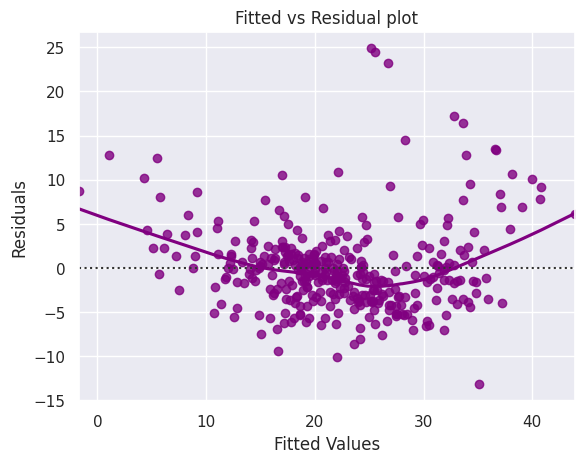

In [227]:
# let's plot the fitted values vs residuals

sns.residplot(
    data=df_pred, x="Fitted Values", y="Residuals", color="purple", lowess=True
)
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Fitted vs Residual plot")
plt.show()

Observations

We see no pattern in the plot above.
Hence, the assumptions of linearity and independence are satisfied.
TEST FOR NORMALITY
We will test for normality by checking the distribution of residuals, by checking the Q-Q plot of residuals, and by using the Shapiro-Wilk test.
If the residuals follow a normal distribution, they will make a straight line plot, otherwise not.
If the p-value of the Shapiro-Wilk test is greater than 0.05, we can say the residuals are normally distributed.

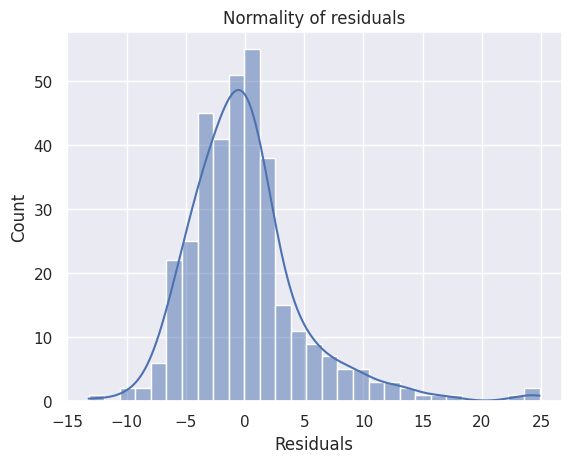

In [228]:
sns.histplot(data=df_pred, x="Residuals", kde=True)
plt.title("Normality of residuals")
plt.show()

Observations

The histogram of residuals almost has a bell shape structure.
Let's check the Q-Q plot.

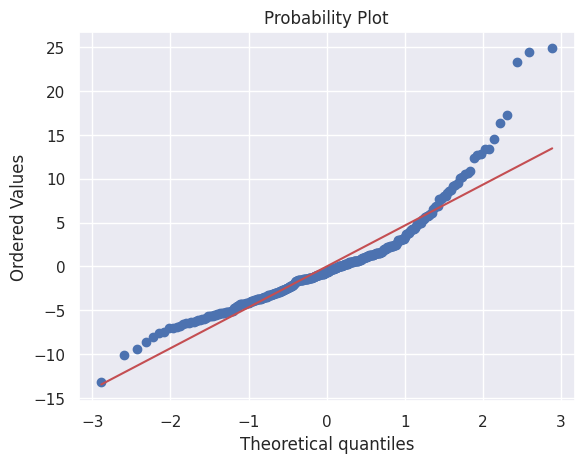

In [229]:
import pylab
import scipy.stats as stats

stats.probplot(df_pred["Residuals"], dist="norm", plot=pylab)
plt.show()


Observations

The residuals almost follow a straight line.
Let's check the results of the Shapiro-Wilk test.

In [230]:
stats.shapiro(df_pred["Residuals"])

ShapiroResult(statistic=np.float64(0.8942404983171556), pvalue=np.float64(5.916196239196863e-15))

Observations

Since p-value < 0.05, the residuals are not normal as per the Shapiro-Wilk test.
However, based on the distribution plot and Q-Q plot, we can consider the distribution to be a good approximation of the normal distribution.
So, the assumption is satisfied.

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     126.9
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.24e-103
Time:                        11:07:18   Log-Likelihood:                 76.475
No. Observations:                 354   AIC:                            -133.0
Df Residuals:                     344   BIC:                            -94.26
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6294      0.242     19.152      0.0

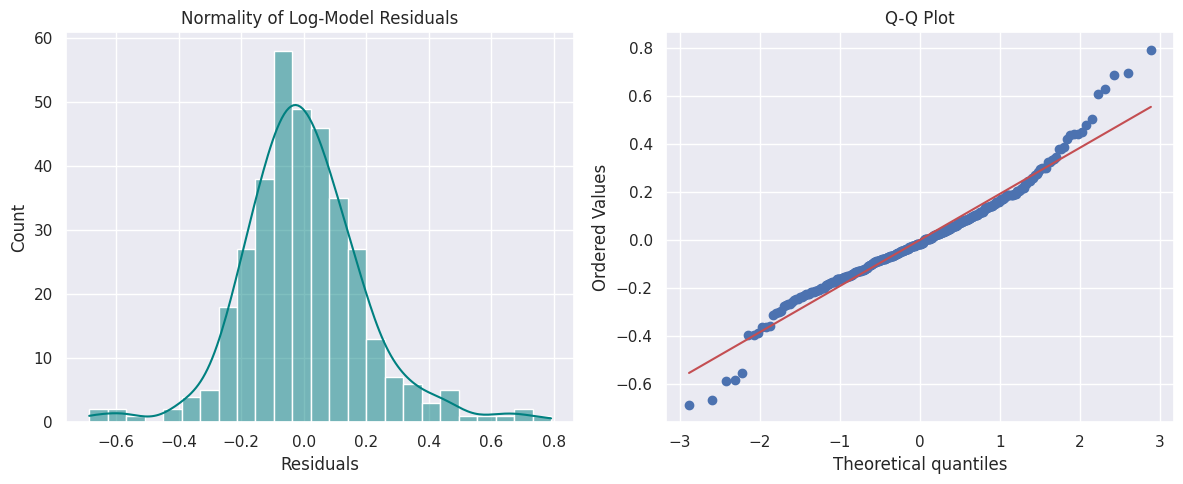

Shapiro-Wilk Test Results:
Statistic: 0.9628, p-value: 7.7226e-08


In [231]:
# Step 1: Take a copy of the target variable and apply a log transformation
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

# Step 2: Fit the OLS model using the transformed target variable
olsmodel_log = sm.OLS(y_train_log, X_train3).fit()
print(olsmodel_log.summary())

# Step 3: Create a dataframe with actual (log), fitted (log), and residual values
df_pred_log = pd.DataFrame()
df_pred_log["Actual (Log)"] = y_train_log
df_pred_log["Fitted (Log)"] = olsmodel_log.fittedvalues
df_pred_log["Residuals"] = olsmodel_log.resid

# Step 4: Visualize the distribution of the new residuals
plt.figure(figsize=(12, 5))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(data=df_pred_log, x="Residuals", kde=True, color="teal")
plt.title("Normality of Log-Model Residuals")

# Q-Q Plot
plt.subplot(1, 2, 2)
stats.probplot(df_pred_log["Residuals"], dist="norm", plot=plt)
plt.title("Q-Q Plot")

plt.tight_layout()
plt.show()

# Step 5: Perform the Shapiro-Wilk test on the new residuals
shapiro_stat, shapiro_p = stats.shapiro(df_pred_log["Residuals"])
print("Shapiro-Wilk Test Results:")
print(f"Statistic: {shapiro_stat:.4f}, p-value: {shapiro_p:.4e}")

TEST FOR HOMOSCEDASTICITY
We will test for homoscedasticity by using the goldfeldquandt test.
If we get a p-value greater than 0.05, we can say that the residuals are homoscedastic. Otherwise, they are heteroscedastic.

In [234]:
import statsmodels.stats.api as sms
from statsmodels.compat import lzip

name = ["F statistic", "p-value", "Alternative"]
# Convert features to float to ensure boolean columns (like CHAS_yes) are numeric
test = sms.het_goldfeldquandt(df_pred["Residuals"], X_train3.astype(float))
lzip(name, test)

[('F statistic', np.float64(1.2224599068220499)),
 ('p-value', np.float64(0.0976863004418288)),
 ('Alternative', 'increasing')]

Observations

Since p-value > 0.05, the residuals are homoscedastic.
So, the assumption is satisfied.
All the assumptions of linear regression are satisfied. Let's rebuild our final model, check its performance, and draw inferences from it.

In [235]:
olsmodel_final = sm.OLS(y_train, X_train3).fit()
print(olsmodel_final.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.703
Model:                            OLS   Adj. R-squared:                  0.695
Method:                 Least Squares   F-statistic:                     90.34
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           4.34e-85
Time:                        11:12:33   Log-Likelihood:                -1065.8
No. Observations:                 354   AIC:                             2152.
Df Residuals:                     344   BIC:                             2190.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         48.8196      6.092      8.014      0.0

Inferences from the model
A unit increase in per capita crime rate (CRIM) decreases the median house price by 0.1110 units, all other variables held constant.
A unit increase in nitric oxides concentration (NX) decreases the median house price by 23.4485 units, all other variables held constant.
A unit increase in average number of rooms (RM) increases the median house price by 2.7844 units, all other variables held constant.
A unit increase in index of accessibility to radial highways (RAD) increases the median house price by 0.1353 units, all other variables held constant.
Houses where tract bounds river (CHAS_yes) will have a 2.8779 units higher median price that the ones where tract does not bound river (CHAS_no).